# Project 11: Adverse Weather Robustness Benchmark (v5.0)

## Obiettivo del progetto

Il sistema scelto è una pipeline di Pedestrian Detection costruita su CARLA: un sensore camera RGB frontale acquisisce i frame della scena simulata, che vengono poi elaborati in tempo reale da YOLOv8n per rilevare la presenza di pedoni. L'obiettivo del benchmark è misurare come le prestazioni di questo sistema (detection rate, confidenza, warning delay, miss rate) degradano al variare delle condizioni ambientali (pioggia, nebbia, notte, backlight) e in presenza di blur ottico (mild e severe), come richiesto dalla traccia del progetto.

## Condizioni Testate

### Condizioni Ambientali (parametri meteo CARLA)

| Condizione | Descrizione |
|---|---|
| **Clear** | Cielo sereno, sole alto (70°) |
| **Rain** | Pioggia intensa (95%), nuvole (90%), pozzanghere e strada bagnata (100%) |
| **Fog** | Nebbia densa (densità 45, distanza 25m) |
| **Night** | Sole sotto l'orizzonte (-25°) |
| **Backlight** | Sole basso (8°) davanti alla camera (azimut calibrato per spawn point), controluce |
| **Rain severe** | Temporale al crepuscolo: pioggia e vento al massimo, cielo coperto, foschia, sole a 3° |
| **Fog severe** | Nebbia fittissima (densità 90, distanza 5 m): visibilità di pochi metri |
| **Fog 60 / Fog 75** | Nebbia intermedia (densità 60 e 75, distanza 15 e 10 m), tra fog e fog severe |
| **Night severe** | Notte con i lampioni spenti: la scena è illuminata solo dagli anabbaglianti dell'ego |
| **Night highbeam** | Come night severe, ma con gli abbaglianti dell'ego accesi |
| **Rain night** | La pioggia di *rain* di notte, con i lampioni accesi |

Le condizioni *severe* e i livelli intermedi di nebbia servono a trovare le **soglie di fallimento**: le versioni base di CARLA sono abbastanza leggere da non mettere in difficoltà il detector nella zona critica.

### Corruzione Visiva: Blur (post-processing sull'immagine catturata)

Come richiesto dalla traccia (*"Add mild and severe visual corruptions to identify clear failure thresholds"*), viene applicato **Gaussian Blur** a quattro livelli di severità (σ in pixel a 1280×720):

| Corruzione | Severità | σ | Cosa simula |
|---|---|---|---|
| **Blur σ1** | 1 | 1 px | Leggera perdita di nitidezza |
| **Blur σ2** | 2 | 2 px | Lente appena appannata |
| **Blur mild** | 3 | 3 px | Lente leggermente sporca o condensa |
| **Blur severe** | 4 | 7 px | Lente molto sporca o fuori fuoco |

**Totale: 20 condizioni** (5 meteo base + 5 meteo severo o intermedio + 2 combinazioni + 4 livelli di blur + 4 corruzioni insieme al meteo). Velocità di crociera: 30 km/h nello Scenario 1 (pedone), 40 km/h nello Scenario 2 (semaforo).

Il blur viene applicato in post-processing sul frame catturato dalla camera in condizione **clear**, così da isolare l'effetto della corruzione senza mescolare gli effetti del meteo.

### Corruzioni insieme al meteo: gocce sulla lente e abbagliamento

Due effetti che una camera reale subisce ma che CARLA riproduce poco o per niente: nella pioggia di CARLA si vedono solo poche macchie sfocate, simili ad acqua sulla lente, leggere e diverse da run a run (si notano sugli sfondi con molti dettagli, come gli alberi, e quasi mai sul target); nel controluce il sole basso finisce dietro i palazzi, quindi non abbaglia mai. Vengono aggiunti in post-processing **insieme al meteo che li provoca**, ognuno su due livelli (mild e severe):

| Corruzione | Meteo | Mild | Severe |
|---|---|---|---|
| **Lens drops** (gocce sulla lente) | rain | 30 gocce piccole | 70 gocce più grandi + velo d'acqua (σ 2 px) |
| **Glare** (abbagliamento) | backlight | sole saturato e alone leggero | alone ampio e velo che riduce il contrasto in tutta l'immagine |

Ogni goccia è fuori fuoco e mostra la scena rifratta (capovolta), come una piccola lente. Le gocce hanno posizioni fisse (seed fisso) e il sole è sempre nello stesso punto (al centro, poco sopra l'orizzonte), quindi la corruzione è identica in ogni frame e in ogni run. Il confronto con *rain* e *backlight* senza corruzione isola l'effetto delle gocce e dell'abbagliamento; l'esito resta calcolato rispetto al clear, come per tutte le condizioni.


## Metriche Raccolte

| Metrica | Descrizione |
|---|---|
| **Detection Rate (recall)** | Percentuale dei frame con pedone visibile in cui il pedone è stato rilevato correttamente (associato alla ground truth CARLA) |
| **Precision** | Frazione delle detection accettate che corrispondono davvero al target |
| **First Detection Distance** | Distanza (in metri) alla quale il sistema rileva il pedone per la prima volta |
| **Confidence** | Confidenza di YOLOv8n sulla detection associata al pedone |
| **Warning (FCW)** | Time-to-collision al primo warning, ritardo rispetto all'ingresso nella zona di warning, e se il veicolo riesce a fermarsi in tempo |
| **Miss Rate** | Percentuale di frame nella zona critica, con pedone visibile, in cui il pedone NON è stato rilevato |
| **False Positive Count** | Numero di detection "person" che non corrispondono al pedone reale (es. dissuasori, arredo urbano) |
| **Min Distance** | Distanza minima raggiunta tra veicolo e pedone prima dello stop |

Le metriche vengono registrate **frame-by-frame** e aggregate per ogni condizione, permettendo di tracciare curve di degradazione e identificare le soglie di fallimento del sistema.

### Deliverables
1. Benchmark scripts eseguibili (self-contained notebook)
2. Codice CARLA per gestione scenario e meteo
3. Report con metodologia, metriche e **failure cases**
4. Confronti side-by-side visuali
5. Grafici di degradazione con **soglie di collasso**
6. Tabelle con esito OK / DEGRADATO / COLLASSO per ogni condizione
7. Modulo FCW (pedone) e Red Light Warning (semaforo) basati sul time-to-collision

---

## 1. Setup Ambiente e Dipendenze

Prima di iniziare, assicuriamoci di avere tutte le librerie necessarie installate.

**Requisiti**:
- Python 3.7 o 3.8
- CARLA Simulator in esecuzione su `localhost:2000`
- Pacchetti: `carla`, `ultralytics`, `opencv-python`, `pandas`, `matplotlib`, `pillow`, `seaborn`

## 1.1 Fix Dipendenze (se necessario)

Se riscontri errori di import con `urllib3` e OpenSSL, esegui questa cella per downgrade alla versione compatibile.

In [1]:
# Fix compatibilità dipendenze per Python 3.7
import sys
!{sys.executable} -m pip install --upgrade "urllib3<2.0" "typing-extensions>=4.0" "tabulate" "seaborn" "matplotlib-inline==0.1.6" --quiet

print("Dipendenze fixate:")
print("   - urllib3 < 2.0 (compatibilità OpenSSL)")
print("   - typing-extensions >= 4.0 (backport typing per Python 3.7)")
print("   - tabulate (per report markdown)")
print("   - seaborn (per heatmap)")
print("   - matplotlib-inline 0.1.6 (le versioni nuove non funzionano con matplotlib 3.5: riavviare il kernel)")

Dipendenze fixate:
   - urllib3 < 2.0 (compatibilità OpenSSL)
   - typing-extensions >= 4.0 (backport typing per Python 3.7)
   - tabulate (per report markdown)
   - seaborn (per heatmap)
   - matplotlib-inline 0.1.6 (le versioni nuove non funzionano con matplotlib 3.5: riavviare il kernel)


In [2]:
%pip install -r requirements.txt

Note: you may need to restart the kernel to use updated packages.


In [ ]:
# Verifica versione Python
import sys
print(f"Python version: {sys.version}")

# Fix per typing.OrderedDict in Python 3.7
import typing
if not hasattr(typing, 'OrderedDict'):
    from collections import OrderedDict as CollectionsOrderedDict
    typing.OrderedDict = CollectionsOrderedDict
    print("Monkey-patch applicato: typing.OrderedDict aggiunto manualmente")

#  OpenMP e PyTorch PRIMA di matplotlib/seaborn
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
import torch
print("--- HARDWARE ACCELERATION CHECK ---")
print(f"CUDA (Nvidia GPU) available: {torch.cuda.is_available()}")
if hasattr(torch.backends, 'mps'):
    print(f"MPS (Apple Silicon GPU) available: {torch.backends.mps.is_available()}")
print("-----------------------------------")

# Importa librerie principali
import csv
import queue
import time
import glob
import json
from datetime import datetime

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from PIL import Image
from ultralytics import YOLO

import carla
# Stile plot
plt.style.use('seaborn-whitegrid')
sns.set_palette("husl")

print(" Tutte le librerie importate con successo")


Python version: 3.10.21 | packaged by Anaconda, Inc. | (main, Aug 27 2026, 14:35:39) [MSC v.1942 64 bit (AMD64)]
--- HARDWARE ACCELERATION CHECK ---
CUDA (Nvidia GPU) available: True
MPS (Apple Silicon GPU) available: False
-----------------------------------
✅ Tutte le librerie importate con successo


## 2. Configurazione Connessione CARLA

Connettiamoci al server CARLA e verifichiamo che sia raggiungibile.

**Nota**: Il server CARLA deve essere già avviato prima di eseguire questa cella.

In [3]:
# Configurazione connessione
CARLA_HOST = 'localhost'
CARLA_PORT = 2000
CARLA_TIMEOUT = 20.0

try:
    client = carla.Client(CARLA_HOST, CARLA_PORT)
    client.set_timeout(CARLA_TIMEOUT)
    world = client.get_world()
    
    print(f" Connesso a CARLA")
    print(f"   Client version: {client.get_client_version()}")
    print(f"   Server version: {client.get_server_version()}")
    print(f"   Mappa corrente: {world.get_map().name}")
    
except RuntimeError as e:
    print(f"Errore di connessione: {e}")
    print(f"   Verifica che CARLA sia in esecuzione su {CARLA_HOST}:{CARLA_PORT}")

 Connesso a CARLA
   Client version: 0.9.16
   Server version: 0.9.16
   Mappa corrente: Carla/Maps/Town10HD_Opt


## 3. Definizione Condizioni Meteo

Creiamo una funzione per gestire le diverse condizioni meteorologiche in modo consistente.

**Parametri CARLA controllati**:
- Cloudiness, precipitation, fog density, sun position, wetness, wind intensity

Tutti i parametri sono scritti in modo esplicito a partire da una base comune (= clear) e ogni chiamata crea un **nuovo** oggetto `carla.WeatherParameters`. I preset di CARLA (`ClearNoon`, ...) sono oggetti condivisi: modificarli "contamina" le condizioni eseguite dopo (nelle versioni precedenti la nebbia del test fog finiva anche nel test backlight).

In [ ]:
# Ordine e nomi dei parametri di carla.WeatherParameters (CARLA 0.9.16)
WEATHER_FIELDS = (
    'cloudiness', 'precipitation', 'precipitation_deposits', 'wind_intensity',
    'sun_azimuth_angle', 'sun_altitude_angle',
    'fog_density', 'fog_distance', 'fog_falloff', 'wetness',
    'scattering_intensity', 'mie_scattering_scale', 'rayleigh_scattering_scale',
    'dust_storm',
)

# Base comune (= clear): ogni condizione sovrascrive solo cio' che la caratterizza
BASE_WEATHER = {
    'cloudiness': 0.0,
    'precipitation': 0.0,
    'precipitation_deposits': 0.0,
    'wind_intensity': 0.0,
    'sun_azimuth_angle': 0.0,
    'sun_altitude_angle': 70.0,
    'fog_density': 0.0,
    'fog_distance': 0.0,
    'fog_falloff': 0.0,
    'wetness': 0.0,
    'scattering_intensity': 1.0,
    'mie_scattering_scale': 0.03,
    'rayleigh_scattering_scale': 0.0331,
    'dust_storm': 0.0,
}

WEATHER_OVERRIDES = {
    'clear': {},
    'rain': {
        'cloudiness': 90.0,
        'precipitation': 95.0,
        'precipitation_deposits': 90.0,
        'wind_intensity': 100.0,
        'wetness': 100.0,
        'fog_density': 8.0,
    },
    'fog': {
        'fog_density': 45.0,
        'fog_distance': 25.0,
        'fog_falloff': 1.5,
    },
    'night': {
        'sun_altitude_angle': -25.0,
    },
    # --- Livelli severi: stessa condizione, molto piu' pesante ---
    'rain_severe': {               # temporale al crepuscolo: pioggia massima, cielo coperto, poca luce
        'cloudiness': 100.0,
        'precipitation': 100.0,
        'precipitation_deposits': 100.0,
        'wind_intensity': 100.0,
        'wetness': 100.0,
        'fog_density': 25.0,
        'fog_distance': 10.0,
        'sun_altitude_angle': 3.0,
    },
    'fog_60': {                    # nebbia intermedia tra fog e fog_severe (soglia di fallimento)
        'fog_density': 60.0,
        'fog_distance': 15.0,
        'fog_falloff': 1.5,
    },
    'fog_75': {
        'fog_density': 75.0,
        'fog_distance': 10.0,
        'fog_falloff': 1.5,
    },
    'fog_severe': {                # nebbia fittissima: visibilita' di pochi metri
        'fog_density': 90.0,
        'fog_distance': 5.0,
        'fog_falloff': 1.5,
    },
    'night_severe': {              # notte senza lampioni (vedi STREET_LIGHTS_OFF): solo i fari dell'ego
        'sun_altitude_angle': -25.0,
        'cloudiness': 80.0,
    },
    # --- Combinazioni ---
    'night_highbeam': {            # come night_severe, ma con gli abbaglianti dell'ego (vedi EGO_HIGH_BEAM)
        'sun_altitude_angle': -25.0,
        'cloudiness': 80.0,
    },
    'rain_night': {                # pioggia di 'rain' di notte, con i lampioni accesi
        'cloudiness': 90.0,
        'precipitation': 95.0,
        'precipitation_deposits': 90.0,
        'wind_intensity': 100.0,
        'wetness': 100.0,
        'fog_density': 8.0,
        'sun_altitude_angle': -25.0,
    },
    'backlight': {
        'sun_azimuth_angle': 180.0,  # sostituito da (yaw ego + offset dello spawn) quando lo yaw e' noto
        'sun_altitude_angle': 8.0,   # sole basso: entro il campo visivo verticale della camera
    },
}

# Condizioni in cui i lampioni della citta' restano SPENTI anche di notte
STREET_LIGHTS_OFF = {'night_severe', 'night_highbeam'}

# Condizioni in cui l'ego accende gli abbaglianti (nelle altre: luci di posizione + anabbaglianti)
EGO_HIGH_BEAM = {'night_highbeam'}

# Azimut del sole relativo alla direzione di marcia dell'ego per avere il sole DAVANTI
# alla camera (controluce), per spawn point: l'offset in cui il sole compare
# nell'inquadratura. Entrambi gli spawn hanno yaw ~0: con 180 il sole e' davanti
# (con 0 il sole era alle spalle dell'ego nello Scenario 2).
BACKLIGHT_AZIMUTH_OFFSET = {0: 180.0, 103: 180.0}   # {spawn point: offset in gradi}


def backlight_offset(spawn_index):
    """Offset di azimut del sole per lo spawn point (180 se lo spawn non e' calibrato)."""
    return BACKLIGHT_AZIMUTH_OFFSET.get(spawn_index, 180.0)


def weather_params(weather_type, ego_yaw=None, spawn_index=None):
    """
    Dizionario completo dei parametri meteo per una condizione.

    Args:
        weather_type (str): una chiave di WEATHER_OVERRIDES ('clear', 'fog', 'fog_severe', ...)
        ego_yaw (float): yaw (gradi) dell'ego vehicle; per 'backlight' orienta il sole
                         davanti alla camera
        spawn_index (int): spawn point dell'ego, per l'offset calibrato del backlight
    """
    weather_type = weather_type.lower()
    if weather_type not in WEATHER_OVERRIDES:
        raise ValueError(f"Condizione meteo sconosciuta: {weather_type}")
    params = dict(BASE_WEATHER)
    params.update(WEATHER_OVERRIDES[weather_type])
    if weather_type == 'backlight' and ego_yaw is not None:
        params['sun_azimuth_angle'] = round((ego_yaw + backlight_offset(spawn_index)) % 360.0, 2)
    return params


def set_street_lights(world, weather_type, params):
    """
    Lampioni della citta' in modo esplicito e ripetibile: accesi solo di notte (sole sotto
    l'orizzonte) e spenti nelle condizioni di STREET_LIGHTS_OFF. Il ciclo giorno/notte
    automatico di CARLA viene disattivato, altrimenti riaccenderebbe le luci da solo.
    Da chiamare DOPO world.set_weather(). Restituisce 'on', 'off' o 'error'.
    """
    on = params['sun_altitude_angle'] < 0 and weather_type not in STREET_LIGHTS_OFF
    try:
        lm = world.get_lightmanager()
        lm.set_day_night_cycle(False)
        lights = lm.get_all_lights(carla.LightGroup.Street)
        if on:
            lm.turn_on(lights)
        else:
            lm.turn_off(lights)
        return 'on' if on else 'off'
    except Exception as exc:
        print(f"  [WARN] impossibile impostare i lampioni: {exc}")
        return 'error'


def set_ego_lights(vehicle, weather_type):
    """
    Luci dell'ego: posizione + anabbaglianti, piu' gli abbaglianti nelle condizioni di EGO_HIGH_BEAM.
    Restituisce 'high_beam' o 'low_beam' (salvato nei parametri del run).
    """
    state = carla.VehicleLightState.Position | carla.VehicleLightState.LowBeam
    high = weather_type in EGO_HIGH_BEAM
    if high:
        state |= carla.VehicleLightState.HighBeam
    vehicle.set_light_state(carla.VehicleLightState(state))
    return 'high_beam' if high else 'low_beam'


def build_weather(weather_type, ego_yaw=None, spawn_index=None):
    """
    Costruisce parametri meteo CARLA per una condizione specifica.
    Restituisce sempre un oggetto NUOVO (mai un preset condiviso di CARLA).

    Args:
        weather_type (str): una chiave di WEATHER_OVERRIDES
        ego_yaw, spawn_index: usati solo da 'backlight' (vedi weather_params)

    Returns:
        carla.WeatherParameters
    """
    return carla.WeatherParameters(**weather_params(weather_type, ego_yaw, spawn_index))


def weather_to_dict(weather):
    """Legge tutti i parametri da un carla.WeatherParameters (es. world.get_weather())."""
    return {f: round(float(getattr(weather, f)), 4) for f in WEATHER_FIELDS}


def check_applied_weather(world, expected, label='', tol=1e-3):
    """
    Confronta il meteo attivo sul server con i parametri attesi (dict di weather_params).

    Returns:
        bool: True se tutti i parametri coincidono (angoli confrontati modulo 360)
    """
    applied = weather_to_dict(world.get_weather())
    diff = {}
    for k in WEATHER_FIELDS:   # le chiavi extra ('street_lights', 'ego_lights') non sono parametri meteo
        delta = abs(expected[k] - applied[k])
        if k == 'sun_azimuth_angle':
            delta = min(delta % 360.0, 360.0 - delta % 360.0)
        if delta > tol:
            diff[k] = (expected[k], applied[k])
    if diff:
        print(f"  [WARN] Meteo applicato diverso da '{label}' (atteso, applicato): {diff}")
    else:
        print(f"  Meteo verificato sul server: {label}")
    return not diff


# Test: ogni chiamata restituisce un oggetto nuovo, non influenzato da modifiche precedenti
_w = build_weather('fog')
_w.fog_density = 99.0
assert build_weather('fog').fog_density == 45.0
assert build_weather('backlight').fog_density == 0.0
assert weather_params('backlight', ego_yaw=-90.0, spawn_index=103)['sun_azimuth_angle'] == (backlight_offset(103) - 90.0) % 360.0
assert weather_params('backlight', ego_yaw=-90.0, spawn_index=0)['sun_azimuth_angle'] == (backlight_offset(0) - 90.0) % 360.0
for _name in WEATHER_OVERRIDES:
    _got = weather_to_dict(build_weather(_name))
    assert all(abs(_got[k] - v) <= 1e-3 for k, v in weather_params(_name).items()), _name

print(f" Funzione build_weather() definita e testata")
print(f"   Condizioni supportate: {', '.join(WEATHER_OVERRIDES)}")


 Funzione build_weather() definita e testata
   Condizioni supportate: clear, rain, fog, night, rain_severe, fog_60, fog_75, fog_severe, night_severe, night_highbeam, rain_night, backlight


## 4. Classe Scenario per Test Ripetibili

## Scenario di Test

Lo scenario crea una scena fissa e ripetibile composta da:
- **Ego vehicle** (Tesla Model 3): parte da uno spawn point della mappa. Dopo un assestamento da fermo (freno tirato, per stabilizzare le sospensioni dopo lo spawn) accelera dolcemente (`EGO_ACCEL_MPS2`) fino a `PED_SPEED_KMH` (30 km/h) e da lì procede a velocità costante, senza sterzare.
- **Pedone** (target di rilevamento): attraversa la strada 80 metri davanti all'ego vehicle (`PED_CROSSING`). Parte dallo spartitraffico alla sinistra della corsia `PED_START_DELAY_S` secondi dopo l'ego e cammina verso destra a velocità costante, calcolata in modo da arrivare davanti all'angolo anteriore destro dell'ego quando il paraurti raggiunge la sua linea di attraversamento (incidente). Il time-to-collision è misurato dal paraurti alla linea di attraversamento; il run termina quando il paraurti arriva sulla linea.
- **Traffico nella carreggiata opposta** (`OPPOSITE_TRAFFIC`, due corsie): un'Audi e-tron e una Mini partono insieme all'ego da 78 e 90 m, prima dell'incrocio che c'è a circa 91 m, nella corsia vicina allo spartitraffico, e accelerano con la stessa rampa fino a 40 e 30 km/h; una moto parte dietro la Mini, da 140 m, oltre l'incrocio (la strada prosegue dritta fino a circa 148 m e poi finisce in un incrocio a T), nella corsia più a sinistra rispetto all'ego, fino a 35 km/h.
- **Veicolo nella corsia di destra** (`LEAD_TRAFFIC`): un Nissan Patrol parte oltre la linea del pedone (92 m) e va piano (20 km/h) verso il semaforo in fondo, nello stesso senso dell'ego.
- **Persone sul marciapiede a destra** (`SIDEWALK_WALKERS`): cinque persone camminano nei due sensi su due file separate, con percorso imposto a ogni tick.

Le persone sul marciapiede e il motociclista hanno anche loro una **ground truth**: una detection "person" su di loro non è il target né un falso positivo e viene contata a parte (`other_person_detections`). Un **sensore di collisione** sull'ego registra qualunque contatto (`ego_collisions`), per verificare che il contorno non interferisca con il test.

Tutti i parametri (posizioni, velocità, traffico) restano **identici** in ogni run, così l'unica variabile tra un test e l'altro è la condizione ambientale applicata.


In [6]:
class MovingScenario:
    """
    Scenario controllato: ego vehicle si muove verso un pedone che attraversa (PED_CROSSING)
    oppure fermo davanti a lui.

    Attraversamento: il pedone parte dallo spartitraffico (o marciapiede) piu' vicino alla
    sinistra dell'ego, sulla linea perpendicolare alla marcia che passa per il punto a
    ped_distance metri dallo spawn (dove stava il pedone fermo), e cammina verso destra.
    Parte PED_START_DELAY_S dopo l'ego, a una velocita' (calcolata in run_condition) che lo porta
    davanti all'angolo anteriore destro dell'ego quando il paraurti arriva sulla sua linea: incidente.

    Contorno: i veicoli di OPPOSITE_TRAFFIC incrociano l'ego nella carreggiata opposta durante
    l'avvicinamento, le persone di SIDEWALK_WALKERS camminano sul marciapiede a destra. Le loro
    detection 'person' non sono errori (other_road_users, contate in other_person_detections).
    """
    SPAWN_INDEX = 0

    def __init__(self, world):
        self.world = world
        self.vehicles = []
        self.pedestrians = []
        self.sensors = []
        self.blueprint_lib = world.get_blueprint_library()

    def setup(self, ped_distance=80):
        """
        Crea scenario con pedone a distanza fissa.
        
        Args:
            ped_distance (int): distanza iniziale pedone in metri
        """
        spawn_points = self.world.get_map().get_spawn_points()
        ego_spawn = spawn_points[self.SPAWN_INDEX]

        # Spawn ego vehicle
        vehicle_bp = self.blueprint_lib.find('vehicle.tesla.model3')
        self.ego_vehicle = self.world.spawn_actor(vehicle_bp, ego_spawn)
        self.vehicles.append(self.ego_vehicle)

        tesla_lights = carla.VehicleLightState.Position | carla.VehicleLightState.LowBeam
        self.ego_vehicle.set_light_state(carla.VehicleLightState(tesla_lights))
        
        # Punto davanti al veicolo, lungo la sua direzione di marcia: il pedone sta qui (fermo,
        # rivolto verso l'ego) oppure lo attraversa camminando verso destra
        ped_location = ego_spawn.location + ego_spawn.get_forward_vector() * ped_distance
        right = ego_spawn.get_right_vector()
        self.cross_line = ped_location
        self.cross_dir = carla.Vector3D(right.x, right.y, 0.0)
        pedestrian_bp = self.blueprint_lib.find('walker.pedestrian.0001')
        if PED_CROSSING:
            start_location = self._crossing_start(ped_location, right)
            ped_transform = carla.Transform(start_location, carla.Rotation(0, ego_spawn.rotation.yaw + 90.0, 0))
        else:
            ped_transform = carla.Transform(ped_location, carla.Rotation(0, ego_spawn.rotation.yaw + 180.0, 0))
        pedestrian = self.world.spawn_actor(pedestrian_bp, ped_transform)
        self.pedestrians.append(pedestrian)
        
        # Traffico nella carreggiata opposta e persone sul marciapiede a destra (stessi in ogni run)
        self.ego_spawn = ego_spawn
        self.opp_traffic = []
        self.lead_traffic = []
        self._plan_opposite_traffic(ego_spawn, ped_location)
        self._spawn_lead_traffic(ego_spawn)
        self._spawn_sidewalk_walkers(ego_spawn)
        return self.ego_vehicle, self.pedestrians

    def _rel(self, ego_spawn, location):
        """(distanza in avanti, spostamento a destra) di location rispetto allo spawn dell'ego."""
        fwd, right = ego_spawn.get_forward_vector(), ego_spawn.get_right_vector()
        d = location - ego_spawn.location
        return d.x * fwd.x + d.y * fwd.y, d.x * right.x + d.y * right.y

    def _opposite_lane(self, ego_spawn, ped_location):
        """Waypoint della corsia opposta (senso di marcia contrario all'ego) sulla linea del pedone."""
        carla_map = self.world.get_map()
        ped_wp = carla_map.get_waypoint(ped_location)
        right = ped_wp.transform.get_right_vector()
        for offset in (-6.0, -10.0, 6.0, 10.0):
            wp = carla_map.get_waypoint(ped_location + right * offset, project_to_road=True,
                                        lane_type=carla.LaneType.Driving)
            if wp is None or (wp.road_id == ped_wp.road_id and wp.lane_id == ped_wp.lane_id):
                continue
            yaw_diff = abs((wp.transform.rotation.yaw - ego_spawn.rotation.yaw + 180.0) % 360.0 - 180.0)
            if yaw_diff > 150.0:
                return wp
        return None

    def _opposite_lanes(self, ego_spawn, ped_location):
        """
        Corsie della carreggiata opposta sulla linea del pedone, come dict {'inner', 'outer'} di waypoint:
        'inner' e' la piu' vicina all'ego (accanto allo spartitraffico), 'outer' la piu' a sinistra.
        Con una sola corsia le due coincidono.
        """
        first = self._opposite_lane(ego_spawn, ped_location)
        if first is None:
            return None

        def opposite(wp):
            if wp is None or wp.lane_type != carla.LaneType.Driving:
                return False
            return abs((wp.transform.rotation.yaw - ego_spawn.rotation.yaw + 180.0) % 360.0 - 180.0) > 150.0

        lanes = [first]
        for step in ('get_left_lane', 'get_right_lane'):
            wp = first
            for _ in range(4):
                wp = getattr(wp, step)()
                if not opposite(wp) or any(wp.lane_id == l.lane_id and wp.road_id == l.road_id for l in lanes):
                    break
                lanes.append(wp)
        # Spostamento laterale rispetto all'ego: piu' negativo = piu' a sinistra
        lanes.sort(key=lambda wp: self._rel(ego_spawn, wp.transform.location)[1])
        if len(lanes) == 1:
            print("  AVVISO: la carreggiata opposta ha una sola corsia")
        return {'inner': lanes[-1], 'outer': lanes[0]}

    def _plan_opposite_traffic(self, ego_spawn, ped_location):
        """
        Veicoli di OPPOSITE_TRAFFIC nella carreggiata opposta, fermi alla distanza indicata davanti allo
        spawn e nella corsia indicata; partono al tick 1 insieme all'ego (update_traffic). La partenza puo'
        stare oltre un incrocio, se la corsia lo attraversa dritta; ci si ferma dove la corsia gira (fine strada)
        e mai dentro un incrocio.
        """
        if not OPPOSITE_TRAFFIC:
            return
        lanes = self._opposite_lanes(ego_spawn, ped_location)
        if lanes is None:
            print("  AVVISO: corsia opposta non trovata, niente traffico")
            return

        def rel_x(wp):
            return self._rel(ego_spawn, wp.transform.location)[0]

        def lat(wp):
            return self._rel(ego_spawn, wp.transform.location)[1]

        def step(wp, farther):
            """Waypoint a 1 m lungo la corsia (farther: allontanandosi dall'ego, cioe' previous(), visto che
            la corsia va verso l'ego); negli incroci il ramo piu' dritto. None se finisce o se esce di oltre
            1.5 m dalla linea della corsia (svolta)."""
            nxt = wp.previous(1.0) if farther else wp.next(1.0)
            if not nxt:
                return None
            best = min(nxt, key=lambda w: abs(lat(w) - lat(wp)))
            return best if abs(lat(best) - lane_y) <= 1.5 else None

        for name, kmh, x_start, lane in OPPOSITE_TRAFFIC:
            # A passi di 1 m lungo la corsia fino a meno di 1 m da x_start; si ferma se un passo
            # non avvicina o se la corsia gira
            wp = lanes[lane]
            lane_y = lat(wp)
            x = rel_x(wp)
            for _ in range(600):
                diff = x_start - x
                if abs(diff) < 1.0:
                    break
                nxt = step(wp, diff > 0)
                if nxt is None or abs(x_start - rel_x(nxt)) >= abs(diff):
                    break
                wp, x = nxt, rel_x(nxt)
            # Mai fermi dentro un incrocio: prima si prova poco oltre, se la corsia gira si torna indietro
            for farther in (True, False):
                w = wp
                for _ in range(80):
                    if not w.is_junction:
                        break
                    w = step(w, farther)
                    if w is None:
                        break
                if w is not None and not w.is_junction:
                    wp, x = w, rel_x(w)
                    break
            if abs(x - x_start) > 5.0:
                print(f"  AVVISO: {name} non raggiunge {x_start:.0f} m (la strada finisce o gira), parte da {x:.0f} m")
            tf = carla.Transform(wp.transform.location + carla.Location(z=0.5), wp.transform.rotation)
            blueprints = self.blueprint_lib.filter(name) or self.blueprint_lib.filter('vehicle.audi.etron')
            vehicle = self.world.try_spawn_actor(blueprints[0], tf)
            if vehicle is None:
                print(f"  AVVISO: spawn fallito per {name} nella corsia opposta")
                continue
            vehicle.set_light_state(carla.VehicleLightState(
                carla.VehicleLightState.Position | carla.VehicleLightState.LowBeam))
            vehicle.apply_control(carla.VehicleControl(brake=1.0))
            self.vehicles.append(vehicle)
            self.opp_traffic.append({'actor': vehicle, 'speed': kmh / 3.6, 'current': None})
            lateral = self._rel(ego_spawn, wp.transform.location)[1]
            print(f"  Traffico opposto: {vehicle.type_id} parte da {x:.0f} m davanti all'ego, corsia {lane} "
                  f"({lateral:+.1f} m), fino a {kmh:.0f} km/h")

    def _spawn_lead_traffic(self, ego_spawn):
        """
        Veicoli di LEAD_TRAFFIC nella corsia a destra dell'ego (stesso senso di marcia), alla distanza
        indicata davanti allo spawn. Per ognuno si cerca l'inizio dell'incrocio in fondo alla corsia:
        update_traffic lo fa fermare LEAD_STOP_MARGIN_M prima.
        """
        carla_map = self.world.get_map()
        fwd = ego_spawn.get_forward_vector()
        for name, kmh, ahead_m in LEAD_TRAFFIC:
            wp = carla_map.get_waypoint(ego_spawn.location + fwd * ahead_m).get_right_lane()
            if wp is None or wp.lane_type != carla.LaneType.Driving or \
                    abs((wp.transform.rotation.yaw - ego_spawn.rotation.yaw + 180.0) % 360.0 - 180.0) > 30.0:
                print(f"  AVVISO: corsia di destra (stesso senso dell'ego) non trovata a {ahead_m:.0f} m")
                continue
            # Inizio dell'incrocio in fondo alla corsia
            end_wp = wp
            for _ in range(300):
                nxt = end_wp.next(1.0)
                if not nxt or nxt[0].is_junction:
                    break
                end_wp = nxt[0]
            stop_x = self._rel(ego_spawn, end_wp.transform.location)[0] - LEAD_STOP_MARGIN_M
            tf = carla.Transform(wp.transform.location + carla.Location(z=0.5), wp.transform.rotation)
            blueprints = self.blueprint_lib.filter(name) or self.blueprint_lib.filter('vehicle.audi.etron')
            vehicle = self.world.try_spawn_actor(blueprints[0], tf)
            if vehicle is None:
                print(f"  AVVISO: spawn fallito per {name} nella corsia di destra")
                continue
            vehicle.set_light_state(carla.VehicleLightState(
                carla.VehicleLightState.Position | carla.VehicleLightState.LowBeam))
            vehicle.apply_control(carla.VehicleControl(brake=1.0))
            self.vehicles.append(vehicle)
            self.lead_traffic.append({'actor': vehicle, 'speed': kmh / 3.6, 'current': None,
                                      'stop_x': stop_x, 'stopped': False})
            room = stop_x + LEAD_STOP_MARGIN_M - (ahead_m + vehicle.bounding_box.extent.x)
            print(f"  Corsia di destra: {vehicle.type_id} parte da {ahead_m:.0f} m a {kmh:.0f} km/h; "
                  f"incrocio a {room:.0f} m dal suo muso" + (", si ferma prima" if LEAD_STOP_AT_JUNCTION else ""))

    def _spawn_sidewalk_walkers(self, ego_spawn):
        """
        Persone di SIDEWALK_WALKERS sul marciapiede alla destra dell'ego: dalla corsia dell'ego si va
        verso destra (get_right_lane) oltre la corsia libera, fino alla prima corsia di tipo Sidewalk.
        Due file a +-SIDEWALK_LANE_OFFSET_M dal centro del marciapiede, una per verso di marcia.
        """
        carla_map = self.world.get_map()
        fwd = ego_spawn.get_forward_vector()
        walker_bps = sorted(self.blueprint_lib.filter('walker.pedestrian.*'), key=lambda b: b.id)
        walker_bps = [b for b in walker_bps if b.id != 'walker.pedestrian.0001'] or walker_bps
        self.sidewalk_walkers = []
        for k, (ahead_m, direction, speed) in enumerate(SIDEWALK_WALKERS):
            wp = carla_map.get_waypoint(ego_spawn.location + fwd * ahead_m)
            crossed = []
            for _ in range(6):
                wp = wp.get_right_lane()
                if wp is None or wp.lane_type == carla.LaneType.Sidewalk:
                    break
                crossed.append(str(wp.lane_type))
            if wp is None or wp.lane_type != carla.LaneType.Sidewalk:
                print(f"  AVVISO: marciapiede a destra non trovato a {ahead_m:.0f} m (corsie: {crossed})")
                continue
            # due file: verso la strada (-) chi va come l'ego, verso l'interno (+) chi va verso l'ego
            right = ego_spawn.get_right_vector()
            side = -direction * SIDEWALK_LANE_OFFSET_M
            loc = wp.transform.location + carla.Location(x=right.x * side, y=right.y * side, z=1.0)
            yaw = ego_spawn.rotation.yaw + (0.0 if direction > 0 else 180.0)
            walker = self.world.try_spawn_actor(walker_bps[(3 * k + 1) % len(walker_bps)],
                                                carla.Transform(loc, carla.Rotation(yaw=yaw)))
            if walker is None:
                print(f"  AVVISO: spawn fallito per la persona sul marciapiede a {ahead_m:.0f} m")
                continue
            self.pedestrians.append(walker)
            walk_dir = carla.Vector3D(fwd.x * direction, fwd.y * direction, 0.0)
            self.sidewalk_walkers.append({'actor': walker, 'dir': walk_dir, 'speed': speed,
                                          'yaw': yaw, 'base': None})
            if k == 0:
                print(f"  Marciapiede: dopo le corsie {crossed}, a {self._rel(ego_spawn, loc)[1]:.1f} m a destra")
        print(f"  Marciapiede: {len(self.sidewalk_walkers)} persone")

    def other_road_users(self):
        """
        Attori che YOLO puo' rilevare come 'person' senza che sia un errore: le persone sul
        marciapiede e i veicoli a due ruote (il conducente fa parte del box del veicolo).
        """
        others = [w['actor'] for w in getattr(self, 'sidewalk_walkers', [])]
        others += [c['actor'] for c in self.opp_traffic
                   if c['actor'].attributes.get('number_of_wheels') == '2']
        return others

    def update_traffic(self, n):
        """
        Da chiamare prima del tick n (n = 1, 2, ...): i veicoli della corsia opposta partono al tick 1
        e accelerano con la rampa dell'ego (EGO_ACCEL_MPS2) fino alla propria velocita'. La chiamata
        al server parte solo se la velocita' cambia.
        """
        for car in self.opp_traffic:
            speed = min(car['speed'], EGO_ACCEL_MPS2 * n * FIXED_DELTA_S)
            if speed == car['current']:
                continue
            if car['current'] is None:
                car['actor'].apply_control(carla.VehicleControl(brake=0.0))
            car['actor'].enable_constant_velocity(carla.Vector3D(speed, 0.0, 0.0))
            car['current'] = speed
        # Corsia di destra: rampa da fermo e velocita' costante; con LEAD_STOP_AT_JUNCTION frenata dolce
        # fino a fermarsi prima dell'incrocio (v = sqrt(2 * decelerazione * spazio rimasto))
        for car in self.lead_traffic:
            if car['stopped']:
                continue
            front = self._rel(self.ego_spawn, car['actor'].get_location())[0] + car['actor'].bounding_box.extent.x
            speed = min(car['speed'], EGO_ACCEL_MPS2 * n * FIXED_DELTA_S)
            if LEAD_STOP_AT_JUNCTION:
                room = max(0.0, car['stop_x'] - front)
                speed = min(speed, (2.0 * LEAD_DECEL_MPS2 * room) ** 0.5)
            if speed < 0.2 and n > 1:
                car['actor'].disable_constant_velocity()
                car['actor'].apply_control(carla.VehicleControl(brake=1.0))
                car['stopped'] = True
                continue
            if car['current'] is None:
                car['actor'].apply_control(carla.VehicleControl(brake=0.0))
            if abs(speed - (car['current'] or 0.0)) > 1e-3:
                car['actor'].enable_constant_velocity(carla.Vector3D(speed, 0.0, 0.0))
                car['current'] = speed
        # Persone sul marciapiede: prima del tick n stanno nel punto raggiunto dopo n-1 tick lungo la
        # loro retta; durante il tick il WalkerControl le fa avanzare (e anima la camminata)
        for w in getattr(self, 'sidewalk_walkers', []):
            s = w['speed'] * (n - 1) * FIXED_DELTA_S
            loc = carla.Location(w['base'].x + w['dir'].x * s, w['base'].y + w['dir'].y * s, w['base'].z)
            w['actor'].set_transform(carla.Transform(loc, carla.Rotation(yaw=w['yaw'])))

    def _crossing_start(self, line_point, right, max_offset_m=20.0, step_m=0.25, margin_m=0.5):
        """
        Punto di partenza dell'attraversamento: margin_m a destra del bordo dello spartitraffico
        (o marciapiede) piu' vicino alla sinistra della corsia dell'ego, sulla linea di
        attraversamento. Il pedone parte dal lato strada: le catene sul bordo dello
        spartitraffico gli impedirebbero di scendere dal cordolo.

        Returns:
            carla.Location di partenza
        """
        carla_map = self.world.get_map()
        lane_wp = carla_map.get_waypoint(line_point)
        d = lane_wp.transform.location - line_point
        lane_center = d.x * right.x + d.y * right.y
        offset = lane_center - lane_wp.lane_width / 2.0
        while offset > lane_center - max_offset_m:
            offset -= step_m
            wp = carla_map.get_waypoint(line_point + right * offset, project_to_road=False,
                                        lane_type=carla.LaneType.Any)
            if wp is not None and wp.lane_type in (carla.LaneType.Median, carla.LaneType.Sidewalk):
                # offset = primo punto (a step_m di precisione) oltre il bordo dello spartitraffico
                start_offset = offset + step_m + margin_m
                start = line_point + right * start_offset
                start.z = lane_wp.transform.location.z + 1.0   # sopra l'asfalto: il pedone si appoggia a terra
                print(f"  Pedone: parte accanto a {wp.lane_type}")
                return start
        raise RuntimeError("nessuno spartitraffico o marciapiede a sinistra della corsia dell'ego")

    def start_crossing(self, speed_mps):
        """Il pedone inizia a camminare verso destra a velocita' costante."""
        self.pedestrians[0].apply_control(carla.WalkerControl(direction=self.cross_dir, speed=speed_mps))

    def set_weather(self, weather_type):
        """Applica condizione meteo (backlight orientato sullo yaw dell'ego) e restituisce i parametri."""
        self.weather_params = weather_params(weather_type, ego_yaw=self.ego_vehicle.get_transform().rotation.yaw,
                                             spawn_index=self.SPAWN_INDEX)
        self.world.set_weather(carla.WeatherParameters(**self.weather_params))
        self.weather_params['street_lights'] = set_street_lights(self.world, weather_type, self.weather_params)
        self.weather_params['ego_lights'] = set_ego_lights(self.ego_vehicle, weather_type)
        return self.weather_params

    def start_motion(self):
        """
        Rilascia i freni dell'ego dopo l'assestamento (da qui la sua velocita' e' imposta con
        set_speed()) e fa partire le persone sul marciapiede. Il traffico opposto parte con update_traffic().
        """
        self._speed = None
        self.ego_vehicle.apply_control(carla.VehicleControl(throttle=0.0, steer=0.0, brake=0.0))
        for w in getattr(self, 'sidewalk_walkers', []):
            w['base'] = w['actor'].get_location()   # appoggiato a terra dopo l'assestamento
            w['actor'].apply_control(carla.WalkerControl(direction=w['dir'], speed=w['speed']))

    def set_speed(self, speed_mps):
        """
        Velocita' imposta all'ego (enable_constant_velocity, coordinate locali); il traffico
        opposto ha velocita' proprie (update_traffic). Chiamata a ogni frame con la rampa di
        ramp_speed(): la chiamata al server parte solo se il valore cambia.
        """
        if speed_mps == self._speed:
            return
        self.ego_vehicle.enable_constant_velocity(carla.Vector3D(speed_mps, 0.0, 0.0))
        self._speed = speed_mps

    def cleanup(self):
        """Distruggi tutti gli attori creati e assicurati che spariscano."""
        for actor in self.sensors + self.vehicles + self.pedestrians:
            if actor.is_alive:
                actor.destroy()
        # Fai un tick sincrono per essere certi che il server li rimuova fisicamente
        # prima del prossimo test, evitando collisioni fantasma!
        try:
            settings = self.world.get_settings()
            was_sync = settings.synchronous_mode
            settings.synchronous_mode = True
            self.world.apply_settings(settings)
            self.world.tick()
            settings.synchronous_mode = was_sync
            self.world.apply_settings(settings)
        except:
            pass

print("Classe MovingScenario definita")


Classe MovingScenario definita


## 5. Caricamento Modello YOLOv8 (Baseline)

Utilizziamo YOLOv8n come baseline per il rilevamento pedoni.

**Perché YOLOv8n?**
- Modello leggero e veloce
- Pre-addestrato su COCO (include classe 'person')
- Ideale come baseline per test di robustezza

In [ ]:
# Scarica e carica il modello YOLOv8n
MODEL_PATH = 'yolov8n.pt'

# Le versioni recenti di ultralytics stampano "'half' is deprecated" a ogni frame (FP16 funziona lo stesso):
# si nasconde solo quel messaggio
try:
    from ultralytics.utils import LOGGER as _YOLO_LOGGER
    _YOLO_LOGGER.addFilter(lambda record: "'half' is deprecated" not in record.getMessage())
except Exception:
    pass

try:
    model = YOLO(MODEL_PATH)
    print(f"Modello YOLOv8n caricato da {MODEL_PATH}")
    print(f"   Classi disponibili: {len(model.names)} (inclusa 'person')")
except Exception as e:
    print(f"Errore caricamento modello: {e}")
    print("   Il modello verrà scaricato automaticamente al primo utilizzo")

Modello YOLOv8n caricato da yolov8n.pt
   Classi disponibili: 80 (inclusa 'person')


> **Ruolo di OpenCV nel progetto**
>
> Nel progetto OpenCV è presente a due livelli:
>
> 1. **Internamente a Ultralytics/YOLO**: il framework YOLO utilizza `cv2` (OpenCV) per tutta la pipeline di I/O immagini, pre-processing (resize, padding, normalizzazione), e post-processing (NMS, drawing).
>
> Quindi **la camera è il sensore primario**  e **OpenCV è il motore di elaborazione visiva** sottostante, sia per la detection (via YOLO) sia per la simulazione delle corruzioni atmosferiche.
>

> **Perché solo Camera e non LiDAR**
>
> Il benchmark utilizza esclusivamente il sensore **camera RGB** come modalità percettiva. Questa scelta è motivata da:
>
> 1. **Costo e diffusione industriale**: le telecamere sono sensori a basso costo che permettono la produzione in serie e l'installazione su veicoli di massa. Il LiDAR, al contrario, resta costoso e più diffuso nella comunità dell'Autonomous Driving (L4-L5) che nell'industria ADAS di serie.
>
> 2. **Rappresentatività del mercato reale**: la maggior parte dei sistemi ADAS attualmente in produzione (Mobileye EyeQ, Tesla Vision) si basa su telecamere come sensore primario. Testare la robustezza di un sistema camera-only è quindi più rilevante per l'industria.
>
> 3. **Vulnerabilità intenzionale**: la camera è il sensore **più vulnerabile** alle condizioni atmosferiche avverse (pioggia, nebbia, notte, controluce). Questo la rende il candidato ideale per un benchmark di robustezza — il degrado è massimo e misurabile.


## 6. Funzioni Utility per Benchmark

Definiamo le funzioni helper per:
- Conversione frame CARLA → RGB numpy
- **Corruzioni visive multiple** (blur, gocce sulla lente, abbagliamento)
- Salvataggio immagini annotate
- Logging risultati CSV

In [8]:
def frame_to_rgb(image):
    """Converte immagine CARLA in array RGB numpy."""
    array = np.frombuffer(image.raw_data, dtype=np.uint8)
    array = array.reshape((image.height, image.width, 4))
    return array[:, :, :3][:, :, ::-1].copy()  # .copy() CRUCIALE: evita sovrascrittura buffer C++ CARLA!

# CORRUZIONI VISIVE — Funzioni per degradare le immagini
# I parametri in pixel (sigma del blur, raggio delle gocce e dell'alone) sono definiti per una larghezza
# di riferimento di 640 px e scalati con la risoluzione reale: la stessa severita'
# produce la stessa sfocatura RELATIVA a qualunque risoluzione.
CORRUPTION_REF_WIDTH = 640


def _resolution_scale(rgb_frame):
    return rgb_frame.shape[1] / CORRUPTION_REF_WIDTH

def apply_blur(rgb_frame, severity):
    """
    Applica Gaussian blur al frame.
    severity (sigma sulla larghezza di riferimento di 640 px; a 1280 px e' il doppio):
        1 = 0.5 (1 px), 2 = 1.0 (2 px), 3 = 1.5 (3 px, mild), 4 = 3.5 (7 px, severe)
    """
    if severity <= 0:
        return rgb_frame
    radius_map = {1: 0.5, 2: 1.0, 3: 1.5, 4: 3.5}
    radius = radius_map.get(severity, 3.5) * _resolution_scale(rgb_frame)
    # OpenCV: ~5-9x piu' veloce di PIL a 1280x720, risultato equivalente (sigma = radius)
    return cv2.GaussianBlur(rgb_frame, (0, 0), sigmaX=radius, sigmaY=radius)


_LENS_DROPS_CACHE = {}


def _lens_drops_maps(height, width, severity):
    """
    Mappe (map_x, map_y, alpha) delle gocce sulla lente, calcolate una volta per risoluzione e severita'.
    Le gocce sono sempre nelle stesse posizioni (seed fisso): stesse gocce in ogni frame e in ogni run.
    Ogni goccia fa da piccola lente: mostra la scena intorno, rimpicciolita e capovolta.
    """
    key = (height, width, severity)
    if key in _LENS_DROPS_CACHE:
        return _LENS_DROPS_CACHE[key]
    # (numero di gocce, raggio minimo e massimo in px a 640 px di larghezza)
    params = {1: (30, 6, 16), 2: (70, 7, 26)}
    n_drops, r_min, r_max = params.get(severity, params[2])
    scale = width / CORRUPTION_REF_WIDTH
    rng = np.random.default_rng(1000 + severity)
    map_x, map_y = np.meshgrid(np.arange(width, dtype=np.float32), np.arange(height, dtype=np.float32))
    alpha = np.zeros((height, width), dtype=np.float32)
    for _ in range(n_drops):
        cx, cy = rng.uniform(0, width), rng.uniform(0, height)
        r = rng.uniform(r_min, r_max) * scale
        ry = r * rng.uniform(1.0, 1.3)                    # gocce un po' allungate in verticale
        x0, x1 = int(max(0, cx - r)), int(min(width, cx + r + 1))
        y0, y1 = int(max(0, cy - ry)), int(min(height, cy + ry + 1))
        if x1 <= x0 or y1 <= y0:
            continue
        xs, ys = np.meshgrid(np.arange(x0, x1, dtype=np.float32), np.arange(y0, y1, dtype=np.float32))
        dx, dy = (xs - cx) / r, (ys - cy) / ry
        d = np.sqrt(dx * dx + dy * dy)
        inside = d < 1.0
        # Rifrazione: dentro la goccia si vede la scena capovolta, presa da una zona 2.5 volte piu' grande
        map_x[y0:y1, x0:x1][inside] = (cx - (xs - cx) * 2.5)[inside]
        map_y[y0:y1, x0:x1][inside] = (cy - (ys - cy) * 2.5)[inside]
        edge = np.clip((1.0 - d) / 0.25, 0.0, 1.0)        # bordo sfumato
        alpha[y0:y1, x0:x1] = np.maximum(alpha[y0:y1, x0:x1], edge)
    maps = (map_x, map_y, alpha[..., None])
    _LENS_DROPS_CACHE[key] = maps
    return maps


def apply_lens_drops(rgb_frame, severity):
    """
    Gocce d'acqua sulla lente (quelle della pioggia di CARLA sono poche, leggere e cambiano da run a run):
    ogni goccia e' fuori fuoco e mostra
    la scena rifratta. Da usare insieme al meteo 'rain'.
    severity: 1 = mild (30 gocce piccole), 2 = severe (70 gocce piu' grandi + velo d'acqua, sigma 1 px)
    """
    if severity <= 0:
        return rgb_frame
    h, w = rgb_frame.shape[:2]
    map_x, map_y, alpha = _lens_drops_maps(h, w, severity)
    scale = _resolution_scale(rgb_frame)
    refracted = cv2.remap(rgb_frame, map_x, map_y, cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT)
    refracted = cv2.GaussianBlur(refracted, (0, 0), sigmaX=2.0 * scale)    # la goccia e' fuori fuoco
    base = rgb_frame
    if severity >= 2:
        base = cv2.GaussianBlur(rgb_frame, (0, 0), sigmaX=1.0 * scale)     # velo d'acqua su tutta la lente
    out = base.astype(np.float32) * (1.0 - alpha) + (refracted.astype(np.float32) * 1.08 + 6.0) * alpha
    return np.clip(out, 0, 255).astype(np.uint8)


_GLARE_CACHE = {}


def apply_glare(rgb_frame, severity):
    """
    Abbagliamento del sole basso davanti alla camera (nel controluce di CARLA il sole finisce dietro
    i palazzi): sole saturato, alone luminoso e velo che riduce il contrasto in tutta l'immagine.
    Da usare insieme al meteo 'backlight'. Sole fisso al centro, poco sopra l'orizzonte.
    severity: 1 = mild, 2 = severe
    """
    if severity <= 0:
        return rgb_frame
    h, w = rgb_frame.shape[:2]
    key = (h, w, severity)
    if key not in _GLARE_CACHE:
        # (raggio del sole, intensita' e raggio dell'alone, velo uniforme); raggi in px a 640 px
        params = {1: (12.0, 0.50, 80.0, 0.10), 2: (18.0, 0.75, 130.0, 0.22)}
        r_sun, halo_a, halo_r, veil = params.get(severity, params[2])
        scale = w / CORRUPTION_REF_WIDTH
        xs, ys = np.meshgrid(np.arange(w, dtype=np.float32), np.arange(h, dtype=np.float32))
        r = np.sqrt((xs - 0.5 * w) ** 2 + (ys - 0.38 * h) ** 2) / scale
        light = np.exp(-(r / r_sun) ** 2) + halo_a / (1.0 + (r / halo_r) ** 2) + veil
        _GLARE_CACHE[key] = np.clip(light, 0.0, 1.0)[..., None]
    light = _GLARE_CACHE[key]
    color = np.array([255.0, 244.0, 220.0], dtype=np.float32)               # luce calda del sole
    out = rgb_frame.astype(np.float32) * (1.0 - light) + color * light
    return np.clip(out, 0, 255).astype(np.uint8)


def apply_corruption(rgb_frame, corruption_type, severity):
    """
    Dispatcher: applica la corruzione specificata al frame.
    
    Args:
        rgb_frame: numpy array RGB
        corruption_type: 'none', 'blur', 'lens_drops', 'glare'
        severity: livello di severita (0 = nessuna)
    
    Returns:
        numpy array RGB con corruzione applicata
    """
    if corruption_type == 'none' or severity <= 0:
        return rgb_frame
    
    corruption_functions = {
        'blur': apply_blur,
        'lens_drops': apply_lens_drops,
        'glare': apply_glare,
    }
    
    fn = corruption_functions.get(corruption_type)
    if fn is None:
        raise ValueError(f"Corruzione sconosciuta: {corruption_type}")
    
    return fn(rgb_frame, severity)


def append_csv_rows(path, fieldnames, rows):
    """Aggiunge righe a CSV (crea file se non esiste)."""
    if not rows:
        return
    
    file_exists = os.path.exists(path)
    with open(path, 'a', newline='', encoding='utf-8') as f:
        writer = csv.DictWriter(f, fieldnames=fieldnames, extrasaction='ignore')
        if not file_exists:
            writer.writeheader()
        writer.writerows(rows)



# ── Spectator Chase-Cam (terza persona, stile videogioco) ──────────
def move_spectator_to(transform, spectator,
                      distance=7.0, x=0, y=0, z=3.0,
                      yaw=0, pitch=-15, roll=0):
    """
    Posiziona lo spectator di CARLA dietro al veicolo.
    Modifica direttamente il transform del veicolo per massima fluidita.
    """
    back_location = transform.location - transform.get_forward_vector() * distance

    back_location.x += x
    back_location.y += y
    back_location.z += z
    transform.rotation.yaw += yaw
    transform.rotation.pitch = pitch
    transform.rotation.roll = roll
    spectator_transform = carla.Transform(back_location, transform.rotation)
    spectator.set_transform(spectator_transform)


print("Funzioni utility definite")
print("   Corruzioni disponibili: blur, lens_drops, glare")
print("   Livelli severita: 1 (mild), 2 (moderate), 3 (severe)")
print("   Spectator chase-cam: move_spectator_to()")


def yolo_input(rgb_frame):
    """Ultralytics interpreta gli array numpy come BGR (convenzione OpenCV): convertiamo da RGB."""
    return np.ascontiguousarray(rgb_frame[:, :, ::-1])


def spawn_rgb_camera(world, parent):
    """Camera RGB frontale (risoluzione, FOV e montaggio dalla configurazione, Sezione 7)."""
    camera_bp = world.get_blueprint_library().find('sensor.camera.rgb')
    camera_bp.set_attribute('image_size_x', str(WIDTH))
    camera_bp.set_attribute('image_size_y', str(HEIGHT))
    camera_bp.set_attribute('fov', str(FOV))
    mount = carla.Transform(carla.Location(x=CAMERA_MOUNT[0], y=CAMERA_MOUNT[1], z=CAMERA_MOUNT[2]))
    return world.spawn_actor(camera_bp, mount, attach_to=parent)


def enable_sync_mode(world):
    """Modalita' sincrona a passo fisso FIXED_DELTA_S. Restituisce le impostazioni precedenti."""
    original = world.get_settings()
    settings = world.get_settings()
    settings.synchronous_mode = True
    settings.fixed_delta_seconds = FIXED_DELTA_S
    world.apply_settings(settings)
    return original


def ramp_speed(frame_index, cruise_mps=None):
    """
    Velocita' imposta al frame k (k = 1, 2, ...): rampa dolce a EGO_ACCEL_MPS2 partendo
    da fermo (niente scatti che facciano sbandare l'auto), poi costante alla velocita' di
    crociera (cruise_mps: PED_SPEED_MPS nello Scenario 1, EGO_SPEED_MPS se non indicata).
    """
    cruise = EGO_SPEED_MPS if cruise_mps is None else cruise_mps
    return min(cruise, EGO_ACCEL_MPS2 * frame_index * FIXED_DELTA_S)


class DriftTracker:
    """Deriva dell'ego rispetto alla retta di partenza: serve a verificare che l'auto non sbandi."""

    def __init__(self, start_transform):
        self.origin = start_transform.location
        self.right = start_transform.get_right_vector()
        self.yaw0 = start_transform.rotation.yaw

    def __call__(self, transform):
        """Restituisce (spostamento laterale in m, variazione di direzione in gradi)."""
        d = transform.location - self.origin
        lateral = d.x * self.right.x + d.y * self.right.y
        heading_change = (transform.rotation.yaw - self.yaw0 + 180.0) % 360.0 - 180.0
        return lateral, heading_change


def time_to_travel(distance_m, cruise_mps=None):
    """Tempo simulato (s) che l'ego impiega a percorrere distance_m partendo da fermo con ramp_speed()."""
    travelled, k = 0.0, 0
    while travelled < distance_m:
        k += 1
        travelled += ramp_speed(k, cruise_mps) * FIXED_DELTA_S
    return k * FIXED_DELTA_S


def select_device():
    """Sceglie l'accelerazione hardware disponibile per YOLO."""
    if torch.cuda.is_available():
        return 'cuda:0'
    if hasattr(torch.backends, 'mps') and torch.backends.mps.is_available():
        return 'mps'
    return 'cpu'


def tick_and_get_frame(world, image_queue, timeout=5.0):
    """
    Avanza la simulazione di un tick (modalita' sincrona) e restituisce
    (frame RGB, snapshot, transform della camera) dello STESSO tick: niente
    immagini in ritardo. Le immagini di tick precedenti rimaste in coda vengono scartate.
    """
    frame_id = world.tick()
    while True:
        image = image_queue.get(timeout=timeout)
        if image.frame >= frame_id:
            return frame_to_rgb(image), world.get_snapshot(), image.transform


def get_annotated_rgb(result):
    """Genera e congela immediatamente una copia RGB del frame annotato da YOLO."""
    annotated = result.plot()
    return annotated[:, :, ::-1].copy()


def save_annotated_sample(sample_data, output_path):
    """Salva frame con bounding box YOLO (accetta sia Result YOLO che array numpy RGB congelato)."""
    if hasattr(sample_data, 'plot'):
        annotated = sample_data.plot()
        annotated_rgb = annotated[:, :, ::-1]
    else:
        annotated_rgb = sample_data
    Image.fromarray(annotated_rgb).save(output_path)


Funzioni utility definite
   Corruzioni disponibili: blur, lens_drops, glare
   Livelli severita: 1 (mild), 2 (moderate), 3 (severe)
   Spectator chase-cam: move_spectator_to()


## 6.1 Ground Truth: proiezione dei bounding box di CARLA

Per sapere se una detection di YOLO corrisponde davvero al target (pedone o semaforo) usiamo la **ground truth** fornita da CARLA:

1. **Box 3D del target**: per il pedone `actor.bounding_box`, per il semaforo i box delle singole lanterne (`traffic_light.get_light_boxes()`).
2. **Proiezione nell'immagine**: gli 8 vertici del box vengono trasformati nel sistema di riferimento della camera (posizione della camera al momento dello scatto, `image.transform`) e proiettati con la matrice dei parametri intrinseci K (ricavata da risoluzione e FOV). Il rettangolo che li racchiude è il box 2D di ground truth.
3. **Visibilità**: il target è considerato visibile solo se è davanti alla camera, se almeno il 50% del box cade nell'inquadratura e se è alto almeno `MIN_GT_HEIGHT_PX` pixel. I frame in cui il target non è visibile non contano né come detection né come miss.
4. **Associazione (matching)**: le detection vengono considerate in ordine di confidenza decrescente; ognuna viene associata al box di ground truth libero con IoU più alto, se l'IoU è ≥ `IOU_MATCH_THRESHOLD` (stesso schema greedy del protocollo COCO).

Da qui le metriche per frame:

| Esito | Significato |
|---|---|
| **TP** (true positive) | Target visibile e associato a una detection con confidenza ≥ `CONF_THRESHOLD` |
| **FN** (false negative) | Target visibile ma nessuna detection associata sopra soglia |
| **FP** (false positive) | Detection sopra soglia che non corrisponde a nessun oggetto reale della classe (es. un dissuasore scambiato per pedone) |

YOLO viene interrogato con una confidenza minima bassa (`YOLO_MIN_CONF`) e nel CSV dei frame vengono salvate sia la confidenza della detection associata al target (`target_conf`) sia quelle dei falsi positivi (`fp_confs`): così è possibile **ricalcolare le metriche con un'altra soglia senza rieseguire la simulazione**.

Nelle immagini salvate il box di ground truth è disegnato in **verde** con l'etichetta `GT`: serve a verificare visivamente che la proiezione sia corretta.


In [9]:
# GROUND TRUTH: proiezione dei bounding box 3D di CARLA e associazione con le detection
# (le soglie CONF_THRESHOLD, IOU_MATCH_THRESHOLD, MIN_GT_HEIGHT_PX, MIN_GT_VISIBLE_FRAC
#  sono definite nella cella di configurazione, Sezione 7)

GT_COLOR = (0, 255, 0)  # verde (RGB)


def camera_intrinsics(width, height, fov_deg):
    """Matrice K della camera pinhole di CARLA (pixel quadrati, centro ottico al centro)."""
    f = width / (2.0 * np.tan(np.radians(fov_deg) / 2.0))
    return np.array([[f, 0.0, width / 2.0],
                     [0.0, f, height / 2.0],
                     [0.0, 0.0, 1.0]])


def vertices_to_array(world_vertices):
    """Lista di carla.Location -> array numpy (N, 3)."""
    return np.array([[v.x, v.y, v.z] for v in world_vertices])


def project_box_2d(world_vertices, cam_transform, K, width, height):
    """
    Proietta nell'immagine i vertici (coordinate mondo) di un box 3D.

    Args:
        world_vertices: lista di carla.Location oppure array numpy (N, 3)
        cam_transform: carla.Transform della camera nel momento dello scatto
        K: matrice dei parametri intrinseci (camera_intrinsics)

    Returns:
        (x1, y1, x2, y2) ritagliato ai bordi dell'immagine, oppure None se il box
        e' dietro la camera, se meno di MIN_GT_VISIBLE_FRAC della sua area cade
        nell'inquadratura o se e' piu' basso di MIN_GT_HEIGHT_PX pixel.
    """
    pts = world_vertices if isinstance(world_vertices, np.ndarray) else vertices_to_array(world_vertices)
    pts_h = np.hstack([pts, np.ones((len(pts), 1))]).T
    world_to_cam = np.array(cam_transform.get_inverse_matrix())
    x_fwd, y_right, z_up = (world_to_cam @ pts_h)[:3]
    if np.any(x_fwd <= 0.1):
        return None
    # Assi UE (x avanti, y destra, z alto) -> assi camera (x destra, y basso, z avanti)
    uvw = K @ np.vstack([y_right, -z_up, x_fwd])
    u, v = uvw[0] / uvw[2], uvw[1] / uvw[2]
    x1, y1, x2, y2 = u.min(), v.min(), u.max(), v.max()
    cx1, cy1 = max(x1, 0.0), max(y1, 0.0)
    cx2, cy2 = min(x2, float(width)), min(y2, float(height))
    if cx2 <= cx1 or cy2 <= cy1:
        return None
    if (cx2 - cx1) * (cy2 - cy1) < MIN_GT_VISIBLE_FRAC * (x2 - x1) * (y2 - y1):
        return None
    if cy2 - cy1 < MIN_GT_HEIGHT_PX:
        return None
    return (float(cx1), float(cy1), float(cx2), float(cy2))


def box_iou(a, b):
    """Intersection over Union tra due box (x1, y1, x2, y2)."""
    ix1, iy1 = max(a[0], b[0]), max(a[1], b[1])
    ix2, iy2 = min(a[2], b[2]), min(a[3], b[3])
    inter = max(0.0, ix2 - ix1) * max(0.0, iy2 - iy1)
    union = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / union if union > 0 else 0.0


def boxes_array(result):
    """
    Tutte le detection del frame come array numpy (N, 6): x1, y1, x2, y2, conf, cls.
    Un solo trasferimento GPU -> CPU per frame: leggere i box uno a uno (box.conf[0], ...)
    forza una sincronizzazione con la GPU per ogni valore, e con YOLO_MIN_CONF basso i box sono tanti.
    """
    return result.boxes.data.cpu().numpy()


def detections_of_class(boxes, names, class_name):
    """Detection di una classe (da boxes_array) come lista di (conf, (x1, y1, x2, y2))."""
    return [(float(b[4]), (float(b[0]), float(b[1]), float(b[2]), float(b[3])))
            for b in boxes if names[int(b[5])] == class_name]


def count_classes(boxes, names, counter, min_conf):
    """Aggiorna il conteggio per classe delle detection con confidenza >= min_conf (diagnostica)."""
    for b in boxes[boxes[:, 4] >= min_conf]:
        name = names[int(b[5])]
        counter[name] = counter.get(name, 0) + 1


def match_detections(detections, gt_boxes):
    """
    Associazione greedy detection <-> ground truth (schema COCO): le detection sono
    considerate in ordine di confidenza decrescente e ognuna prende il box GT libero
    con IoU piu' alto, se >= IOU_MATCH_THRESHOLD.

    Args:
        detections: lista di (conf, box)
        gt_boxes: dict {gt_id: box}

    Returns:
        matches: dict {gt_id: (conf, iou, box)}
        unmatched: lista di (conf, box) non associate a nessun GT
    """
    matches, unmatched = {}, []
    for conf, box in sorted(detections, key=lambda d: -d[0]):
        best_id, best_iou = None, IOU_MATCH_THRESHOLD
        for gt_id, gt_box in gt_boxes.items():
            if gt_id in matches:
                continue
            iou = box_iou(box, gt_box)
            if iou >= best_iou:
                best_id, best_iou = gt_id, iou
        if best_id is None:
            unmatched.append((conf, box))
        else:
            matches[best_id] = (conf, best_iou, box)
    return matches, unmatched


def ground_point(box, K, cam_height):
    """
    Stima la posizione a terra di un oggetto dal bordo inferiore del suo box
    (strada piana, camera orizzontale), come farebbe una FCW monoculare.

    Returns:
        (distanza in avanti, spostamento laterale) in metri rispetto alla camera,
        oppure None se il bordo inferiore del box e' sopra l'orizzonte.
    """
    f, cx, cy = K[0, 0], K[0, 2], K[1, 2]
    u, v = (box[0] + box[2]) / 2.0, box[3]
    if v <= cy + 1.0:
        return None
    forward = f * cam_height / (v - cy)
    return forward, (u - cx) * forward / f


def format_confs(confs):
    """Confidenze come stringa compatta per il CSV (es. '0.62;0.41')."""
    return ';'.join(f"{c:.3f}" for c in sorted(confs, reverse=True))


def draw_gt_box(image_rgb, box, label='GT'):
    """Disegna un box di ground truth in verde, con etichetta sotto il box."""
    x1, y1, x2, y2 = [int(round(v)) for v in box]
    cv2.rectangle(image_rgb, (x1, y1), (x2, y2), GT_COLOR, 1)
    cv2.putText(image_rgb, label, (x1, min(y2 + 12, image_rgb.shape[0] - 2)),
                cv2.FONT_HERSHEY_SIMPLEX, 0.4, GT_COLOR, 1)
    return image_rgb


def gt_zoom(image, frame_row, scale=3):
    """Ritaglio ingrandito attorno al box di ground truth di un frame."""
    x1, y1, x2, y2 = (frame_row[k] for k in ('gt_x1', 'gt_y1', 'gt_x2', 'gt_y2'))
    margin = max(40.0, 1.5 * (y2 - y1))
    h, w = image.shape[:2]
    cx1, cy1 = int(max(0, x1 - margin)), int(max(0, y1 - margin))
    cx2, cy2 = int(min(w, x2 + margin)), int(min(h, y2 + margin))
    crop = image[cy1:cy2, cx1:cx2]
    return cv2.resize(crop, (crop.shape[1] * scale, crop.shape[0] * scale), interpolation=cv2.INTER_NEAREST)


def annotate_frame(result, gt_boxes=()):
    """Frame annotato (RGB): detection YOLO sopra CONF_THRESHOLD + box di ground truth in verde."""
    shown = result[result.boxes.conf >= CONF_THRESHOLD]
    img = get_annotated_rgb(shown)
    for box in gt_boxes:
        draw_gt_box(img, box)
    return img


print("Utility ground truth definite")
print("   camera_intrinsics, project_box_2d, box_iou, match_detections, ground_point, annotate_frame")


Utility ground truth definite
   camera_intrinsics, project_box_2d, box_iou, match_detections, ground_point, annotate_frame


## 7. Configurazione Test Batch

Definiamo le **20 condizioni** da testare, aderenti alla traccia del progetto:
- **5 condizioni meteo** (clear, rain, fog, night, backlight) — baseline senza corruzione
- **5 condizioni meteo severe o intermedie** (rain severe, fog 60, fog 75, fog severe, night severe) — per trovare le soglie di fallimento
- **2 combinazioni** (night highbeam: notte senza lampioni con gli abbaglianti; rain night: pioggia di notte)
- **4 livelli di blur** (σ = 1, 2, 3 e 7 px; gli ultimi due sono il *mild* e il *severe* della traccia)
- **4 corruzioni insieme al meteo** (gocce sulla lente con rain, abbagliamento con backlight; mild e severe)

Totale: **20 condizioni** per batch

In [ ]:
# Parametri simulazione
WIDTH, HEIGHT = 1280, 720     # un pedone a 40 m era alto ~14 px: troppo piccolo per YOLOv8n
FOV = 90
CAMERA_MOUNT = (1.5, 0.0, 2.4)  # posizione camera rispetto all'ego (x avanti, y destra, z alto), metri
FIXED_DELTA_S = 0.05          # passo di simulazione (20 FPS, modalita' sincrona)
YOLO_IMGSZ = WIDTH            # dimensione di input di YOLO: senza questo YOLO ridimensiona a 640
YOLO_HALF = True              # inferenza FP16 su GPU NVIDIA: piu' veloce, ignorato su CPU/MPS
PEDESTRIAN_DISTANCE_M = 80
WARNING_DISTANCE_M = 15.0
MAX_FRAMES_PER_RUN = 500

# Moto: velocita' COSTANTE per ego e traffico (stessa in ogni condizione)
EGO_SPEED_KMH = 40.0          # Scenario 2 (semaforo): il warning (TTC 2.5 s) va dato a ~28 m dalla linea d'arresto
EGO_SPEED_MPS = EGO_SPEED_KMH / 3.6
PED_SPEED_KMH = 30.0          # Scenario 1 (pedone): velocita' urbana nelle zone di attraversamento. A 40 km/h il
                              # pedone di profilo, confermato solo a ~22 m, faceva collassare gia' il clear
PED_SPEED_MPS = PED_SPEED_KMH / 3.6
EGO_ACCEL_MPS2 = 2.5          # rampa di partenza da fermo: ~4.4 s e ~25 m per arrivare a 40 km/h
PED_CROSSING = True           # Scenario 1: il pedone attraversa (dallo spartitraffico a sinistra verso destra)
                              # e arriva davanti all'angolo destro dell'ego quando il paraurti raggiunge la sua linea (incidente)
PED_START_DELAY_S = 7.0       # il pedone parte 7 s dopo l'ego: a 30 km/h attraversa a ~0.8 m/s
# Scenario 1: traffico nella carreggiata opposta (due corsie). Tutti partono insieme all'ego e accelerano
# con la stessa rampa (EGO_ACCEL_MPS2) fino alla propria velocita'. Nella stessa corsia chi parte piu'
# lontano va piu' piano, quindi nessuno raggiunge il veicolo davanti.
# (blueprint, velocita' km/h, distanza di partenza davanti allo spawn dell'ego in m,
#  corsia: 'inner' = vicina allo spartitraffico, 'outer' = la piu' a sinistra rispetto all'ego)
# A ~91 m c'e' un incrocio con la strada che prosegue dritta fino a ~148 m, dove finisce in un incrocio a T:
# Audi e Mini partono prima del primo incrocio, la moto oltre (lo attraversa a velocita' costante).
OPPOSITE_TRAFFIC = [
    ('vehicle.audi.etron', 40.0, 78.0, 'inner'),
    ('vehicle.mini.cooper_s_2021', 30.0, 90.0, 'inner'),
    ('vehicle.yamaha.yzf', 35.0, 140.0, 'outer'),
]
# Scenario 1: veicoli nella corsia di destra (stesso senso dell'ego), oltre la linea del pedone: vanno piano
# verso il semaforo in fondo per tutto il run. Con LEAD_STOP_AT_JUNCTION = True si fermano invece
# LEAD_STOP_MARGIN_M prima dell'incrocio (decelerazione LEAD_DECEL_MPS2): serve spazio sufficiente.
# (blueprint, velocita' km/h, distanza di partenza davanti allo spawn dell'ego in m)
LEAD_TRAFFIC = [
    ('vehicle.nissan.patrol_2021', 20.0, 92.0),
]
LEAD_STOP_AT_JUNCTION = False
LEAD_STOP_MARGIN_M = 3.0
LEAD_DECEL_MPS2 = 3.0
# Scenario 1: persone sul marciapiede a destra dell'ego (non sono il target: detection contate a parte).
# Chi va come l'ego cammina SIDEWALK_LANE_OFFSET_M verso la strada, chi va verso l'ego verso l'interno:
# non si incontrano mai. Il percorso e' imposto a ogni tick (update_traffic): nessuno puo' essere spinto in strada.
# (distanza davanti allo spawn in m, verso: +1 = come l'ego, -1 = verso l'ego, velocita' m/s)
SIDEWALK_WALKERS = [
    (20.0, +1, 1.3),
    (38.0, -1, 1.1),
    (52.0, +1, 1.4),
    (66.0, -1, 1.2),
    (85.0, -1, 1.0),
]
SIDEWALK_LANE_OFFSET_M = 0.5
CROSS_TRAFFIC = True          # Scenario 2: traffico sulla strada trasversale (verde) e incidente dopo il rosso
CROSS_EARLY_GAP_M = 30.0      # auto da destra gia' nell'incrocio: passa davanti all'ego col paraurti a 30 m dalla linea
CROSS_FAST_KMH = 60.0         # auto veloci dai lati, fuori dall'inquadratura durante l'avvicinamento
CROSS_NEAR_MISS_S = 0.5       # auto veloce da destra: passa davanti all'ego 0.5 s dopo la linea d'arresto
CROSS_FAST_PARK_M = 60.0      # ...partendo da 60 m prima dell'incrocio
CROSS_KINEMATIC_BACK_M = 80.0 # auto veloce da sinistra (strada in curva): segue la corsia da 80 m prima dell'incrocio
TL_POST_CRASH_S = 2.0         # l'ego non si ferma al rosso: si simula fino a 2 s dopo l'urto
                              # (le metriche si fermano comunque alla linea d'arresto)
TL_SPAWN_BACK_M = 0.0         # Scenario 2: lo spawn 103 ha un incrocio subito dietro, non si puo' arretrare

# Warning (FCW per il pedone, red light warning per il semaforo), Sezione 8.1
FCW_TTC_WARNING_S = 2.5       # il warning va emesso quando il time-to-collision scende sotto questa soglia
FCW_CONFIRM_K, FCW_CONFIRM_N = 3, 5  # target confermato se rilevato in almeno K degli ultimi N frame
FCW_REACTION_S = 1.0          # tempo di reazione del guidatore dopo il warning
FCW_DECEL_MPS2 = 6.0          # decelerazione di frenata
EGO_PATH_HALF_WIDTH_M = 1.5   # semi-larghezza del percorso dell'ego (per i falsi allarmi FCW)

# Detection e ground truth (stessi valori per entrambi gli scenari)
CONF_THRESHOLD = 0.55       # confidenza minima perche' una detection conti (TP o FP): valore severo
YOLO_MIN_CONF = 0.10        # YOLO restituisce i box da questa confidenza: vengono salvati nel CSV
                            # cosi' le metriche si possono ricalcolare con un'altra soglia senza rieseguire
IOU_MATCH_THRESHOLD = 0.30  # IoU minimo per associare una detection alla ground truth
MIN_GT_HEIGHT_PX = 4        # target piu' bassi di cosi' (in pixel) sono considerati non visibili
MIN_GT_VISIBLE_FRAC = 0.5   # frazione minima del box di ground truth dentro l'inquadratura

# CONDIZIONI DA TESTARE (20): meteo base, meteo severo e intermedio, combinazioni, blur su 4 livelli,
# gocce sulla lente (con rain) e abbagliamento (con backlight) su 2 livelli
# Traccia: "clear weather, rain, fog, night, backlight, and blur"
#          "Add mild and severe visual corruptions to identify clear failure thresholds"

TESTS = [
    # --- Condizioni meteo (baseline: nessuna corruzione) ---
    {'weather': 'clear',     'corruption': 'none', 'severity': 0},
    {'weather': 'rain',      'corruption': 'none', 'severity': 0},
    {'weather': 'fog',       'corruption': 'none', 'severity': 0},
    {'weather': 'night',     'corruption': 'none', 'severity': 0},
    {'weather': 'backlight', 'corruption': 'none', 'severity': 0},

    # --- Meteo severo e livelli intermedi di nebbia (soglie di fallimento) ---
    {'weather': 'rain_severe',  'corruption': 'none', 'severity': 0},
    {'weather': 'fog_60',       'corruption': 'none', 'severity': 0},
    {'weather': 'fog_75',       'corruption': 'none', 'severity': 0},
    {'weather': 'fog_severe',   'corruption': 'none', 'severity': 0},
    {'weather': 'night_severe', 'corruption': 'none', 'severity': 0},

    # --- Combinazioni ---
    {'weather': 'night_highbeam', 'corruption': 'none', 'severity': 0},  # notte senza lampioni, abbaglianti
    {'weather': 'rain_night',     'corruption': 'none', 'severity': 0},  # pioggia di notte, lampioni accesi

    # --- Blur: sigma 1, 2, 3 (mild), 7 px (severe) a 1280 px ---
    {'weather': 'clear', 'corruption': 'blur', 'severity': 1},
    {'weather': 'clear', 'corruption': 'blur', 'severity': 2},
    {'weather': 'clear', 'corruption': 'blur', 'severity': 3},  # mild
    {'weather': 'clear', 'corruption': 'blur', 'severity': 4},  # severe

    # --- Corruzioni insieme al meteo che le provoca (in CARLA leggere o assenti): gocce sulla lente
    #     con la pioggia, abbagliamento del sole con il controluce ---
    {'weather': 'rain',      'corruption': 'lens_drops', 'severity': 1},  # mild
    {'weather': 'rain',      'corruption': 'lens_drops', 'severity': 2},  # severe
    {'weather': 'backlight', 'corruption': 'glare',      'severity': 1},  # mild
    {'weather': 'backlight', 'corruption': 'glare',      'severity': 2},  # severe
]

# Path output - NUOVA CARTELLA CON TIMESTAMP
batch_timestamp = datetime.now().strftime('%Y%m%d_%H%M%S')
BASE_OUTPUT_DIR = f'output_batch_{batch_timestamp}'
RESULTS_DIR = os.path.join(BASE_OUTPUT_DIR, 'results')
SAMPLES_DIR = os.path.join(BASE_OUTPUT_DIR, 'detection_samples')
PLOTS_DIR = os.path.join(BASE_OUTPUT_DIR, 'plots')

os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(SAMPLES_DIR, exist_ok=True)
os.makedirs(PLOTS_DIR, exist_ok=True)

FRAME_LOG_PATH = os.path.join(RESULTS_DIR, 'frame_metrics.csv')
RUN_SUMMARY_PATH = os.path.join(RESULTS_DIR, 'run_summary.csv')

print(f"Configurazione benchmark pronta")
print(f"   Test da eseguire: {len(TESTS)}")
print(f"   Nuova cartella output: {BASE_OUTPUT_DIR}")
print(f"   Sample detection: {SAMPLES_DIR}")
print(f"   Risultati CSV: {RESULTS_DIR}")
print()
print("Test configurati:")
for i, t in enumerate(TESTS, 1):
    print(f"   [{i:2d}] weather={t['weather']:10s} corruption={t['corruption']:12s} severity={t['severity']}")


def save_benchmark_config(path, scenario, summary_rows):
    """Salva in JSON la configurazione completa del batch insieme al meteo applicato in ogni run."""
    try:
        carla_info = {'client_version': client.get_client_version(),
                      'server_version': client.get_server_version(),
                      'map': world.get_map().name}
    except Exception as exc:
        carla_info = {'error': str(exc)}
    cfg = {
        'scenario': scenario,
        'created': datetime.now().isoformat(timespec='seconds'),
        'carla': carla_info,
        'camera': {'width': WIDTH, 'height': HEIGHT, 'fov': FOV, 'mount_xyz': list(CAMERA_MOUNT),
                   'fixed_delta_s': FIXED_DELTA_S},
        'model': {'path': globals().get('MODEL_PATH'), 'imgsz': YOLO_IMGSZ, 'yolo_min_conf': YOLO_MIN_CONF,
                  'half': YOLO_HALF},
        'detection': {'conf_threshold': CONF_THRESHOLD, 'iou_match_threshold': IOU_MATCH_THRESHOLD,
                      'min_gt_height_px': MIN_GT_HEIGHT_PX, 'min_gt_visible_frac': MIN_GT_VISIBLE_FRAC},
        'motion': {'ego_speed_kmh': PED_SPEED_KMH if scenario == 'pedestrian' else EGO_SPEED_KMH,
                   'ego_accel_mps2': EGO_ACCEL_MPS2,
                   'pedestrian_distance_m': PEDESTRIAN_DISTANCE_M, 'tl_spawn_back_m': TL_SPAWN_BACK_M,
                   'pedestrian_crossing': PED_CROSSING, 'ped_start_delay_s': PED_START_DELAY_S,
                   'opposite_traffic': OPPOSITE_TRAFFIC, 'lead_traffic': LEAD_TRAFFIC,
                   'sidewalk_walkers': SIDEWALK_WALKERS,
                   'cross_traffic': CROSS_TRAFFIC, 'cross_early_gap_m': CROSS_EARLY_GAP_M,
                   'cross_fast_kmh': CROSS_FAST_KMH, 'cross_near_miss_s': CROSS_NEAR_MISS_S,
                   'tl_post_crash_s': TL_POST_CRASH_S,
                   'max_frames_per_run': MAX_FRAMES_PER_RUN},
        'warning': {'ttc_warning_s': FCW_TTC_WARNING_S, 'confirm_k': FCW_CONFIRM_K, 'confirm_n': FCW_CONFIRM_N,
                    'reaction_s': FCW_REACTION_S, 'decel_mps2': FCW_DECEL_MPS2,
                    'ego_path_half_width_m': EGO_PATH_HALF_WIDTH_M},
        'weather_base': BASE_WEATHER,
        'street_lights_off': sorted(STREET_LIGHTS_OFF),
        'ego_high_beam': sorted(EGO_HIGH_BEAM),
        'backlight_azimuth_offset': BACKLIGHT_AZIMUTH_OFFSET,
        'corruption_ref_width': CORRUPTION_REF_WIDTH,
        'tests': TESTS,
        'runs': [{'run_label': r['run_label'], 'status': r['status'],
                  'weather_params': json.loads(r['weather_params']) if r.get('weather_params') else None}
                 for r in summary_rows],
    }
    with open(path, 'w', encoding='utf-8') as f:
        json.dump(cfg, f, indent=2, ensure_ascii=False)
    print(f"   Configurazione salvata: {path}")


Configurazione benchmark pronta
   Test da eseguire: 16
   Nuova cartella output: output_batch_20261021_142523
   Sample detection: output_batch_20261021_142523\detection_samples
   Risultati CSV: output_batch_20261021_142523\results

Test configurati:
   [ 1] weather=clear      corruption=none         severity=0
   [ 2] weather=rain       corruption=none         severity=0
   [ 3] weather=fog        corruption=none         severity=0
   [ 4] weather=night      corruption=none         severity=0
   [ 5] weather=backlight  corruption=none         severity=0
   [ 6] weather=rain_severe corruption=none         severity=0
   [ 7] weather=fog_60     corruption=none         severity=0
   [ 8] weather=fog_75     corruption=none         severity=0
   [ 9] weather=fog_severe corruption=none         severity=0
   [10] weather=night_severe corruption=none         severity=0
   [11] weather=night_highbeam corruption=none         severity=0
   [12] weather=rain_night corruption=none         severit

## 8. Funzione Esecuzione Singola Condizione
## Raccolta Dati e Metriche

La funzione `run_condition()` esegue un singolo test per ciascuna delle 10 condizioni, raccogliendo dati su due livelli di dettaglio salvati automaticamente in file CSV.

Ogni detection "person" viene confrontata con la **ground truth** del pedone (Sezione 6.1): conta come rilevamento corretto solo se si sovrappone al pedone reale (IoU ≥ `IOU_MATCH_THRESHOLD`) con confidenza ≥ `CONF_THRESHOLD`. Le detection che non corrispondono al pedone (es. dissuasori sullo spartitraffico) sono falsi positivi, a qualunque distanza.

#### Dati Aggregati (`run_summary.csv`) — 1 riga per condizione

| Metrica | Descrizione |
|---|---|
| `detection_rate` | **Recall**: frazione dei frame con pedone visibile in cui il pedone è stato rilevato (TP / `gt_visible_frames`) |
| `precision` | TP / (TP + FP): quante delle detection "person" accettate erano davvero il pedone |
| `gt_visible_frames` | Frame in cui il pedone è visibile nell'immagine (secondo la ground truth) |
| `false_negatives` | Frame con pedone visibile ma non rilevato |
| `false_positive_count` | Detection "person" sopra soglia che non corrispondono al pedone |
| `fp_per_frame` | Falsi positivi medi per frame |
| `first_detection_distance_m` | Distanza (m) del primo rilevamento corretto del pedone |
| `first_detection_elapsed_s` | Tempo simulato (s) dall'inizio del run fino alla prima detection |
| `warning_delay_s` | Ritardo (s, tempo simulato) tra l'ingresso nella zona di warning (<15m) e la prima detection |
| `miss_rate` | Frazione dei frame in zona critica (<30m), con pedone visibile, in cui il pedone NON è stato rilevato |
| `min_distance_m` | Distanza minima raggiunta tra veicolo e pedone |

#### Dati Frame-by-Frame (`frame_metrics.csv`) — 1 riga per frame

| Colonna | Descrizione |
|---|---|
| `frame_index` | Numero progressivo del frame |
| `elapsed_s` | Tempo simulato dall'inizio del run (indipendente dalla velocita' di GPU/rendering) |
| `distance_m` | Distanza veicolo-pedone in quel frame |
| `persons_detected` | Numero di "person" rilevate sopra soglia nel frame |
| `max_confidence` | Confidenza della detection associata al pedone (0 se nessuna) |
| `detected` / `tp` | 1 se il pedone è stato rilevato correttamente |
| `fn` | 1 se il pedone era visibile ma non è stato rilevato |
| `fp` | Numero di falsi positivi "person" nel frame |
| `fp_confs` | Confidenze di tutti i falsi positivi (anche sotto soglia), per ricalcolare le metriche con un'altra soglia |
| `gt_visible`, `gt_x1..gt_y2`, `gt_height_px` | Visibilità e box di ground truth del pedone (pixel) |
| `target_iou` | IoU tra la detection associata e la ground truth |
| `in_critical_zone` | 1 se distanza < 30m, 0 altrimenti |
| `speed_mps` | Velocità dell'ego (m/s): rampa iniziale, poi costante a `PED_SPEED_KMH` (Scenario 1) o `EGO_SPEED_KMH` (Scenario 2) |
| `lateral_offset_m`, `heading_change_deg` | Deriva laterale e variazione di direzione dell'ego rispetto alla partenza (controllo sbandamenti) |
| `gap_m` | Distanza reale tra paraurti anteriore e pedone |
| `ttc_s` | Time-to-collision reale = `gap_m` / `speed_mps` |
| `fp_in_path` | 1 se un falso positivo "person" è nel percorso dell'ego con TTC stimato sotto soglia (falso allarme FCW) |

I dati aggregati permettono confronti diretti tra condizioni (tabelle, heatmap), mentre i dati frame-by-frame consentono di tracciare curve di degradazione dettagliate (es. recall vs distanza o vs altezza del pedone in pixel).


##### Soglia di confidenza: `CONF_THRESHOLD`

In precedenza la soglia era stata alzata a 0.6 per scartare i falsi positivi (dissuasori, arredo urbano). Con la ground truth questi vengono riconosciuti e contati come falsi positivi, quindi non serve più una soglia alta per nasconderli. Usiamo comunque una soglia **severa (0.55)**: una detection conta solo se il modello è abbastanza sicuro, come serve a un sistema di warning che non deve reagire a detection incerte. Con una soglia bassa (es. 0.25–0.40) il modello risulterebbe più robusto di quanto sia in pratica. Poiché nel CSV vengono salvate anche le confidenze sotto soglia, il valore può essere cambiato in analisi senza rieseguire la simulazione.


In [11]:
def run_condition(world, model, batch_id, weather, corruption, severity):
    """
    Esegue un test completo per una condizione specifica.
    
    Ogni detection 'person' viene associata (IoU) al box di ground truth del pedone
    proiettato da CARLA: TP = pedone visibile e rilevato, FN = visibile ma non rilevato,
    FP = detection 'person' che non corrisponde al pedone.

    Metriche raccolte:
    - detection_rate (= recall: TP / frame con pedone visibile), precision
    - first_detection_distance, min_distance
    - warning_delay_s (tempo simulato tra zona warning e prima detection)
    - miss_rate (frame in zona critica con pedone visibile ma non rilevato)
    - false_positive_count, fp_per_frame

    Returns:
        tuple: (summary_row, frame_rows)
    """
    run_label = f"{weather}_{corruption}{severity}"
    print(f"\n{'='*50}")
    print(f"  Running: {run_label}")
    
    print(f"{'='*50}")

    # Zona critica: distanza sotto cui il pedone DOVREBBE essere rilevato
    CRITICAL_DISTANCE_M = 30.0

    frame_rows = []
    summary_row = {
        'batch_id': batch_id,
        'run_label': run_label,
        'weather': weather,
        'corruption': corruption,
        'severity': severity,
        'total_frames': 0,
        'detection_frames': 0,
        'detection_rate': 0.0,
        'first_detection_distance_m': None,
        'first_detection_elapsed_s': None,
        'warning_delay_s': None,
        'min_distance_m': None,
        'miss_rate': 0.0,
        'gt_visible_frames': 0,
        'false_negatives': 0,
        'false_positive_count': 0,
        'precision': 0.0,
        'fp_per_frame': 0.0,
        'critical_zone_frames': 0,
        'critical_zone_misses': 0,
        'weather_params': None,
        'weather_ok': None,
        'status': 'ok',
    }

    scenario = None
    camera = None
    first_detection_distance = None
    first_detection_time = None
    entered_warning_time = None
    frame_count = 0
    detection_count = 0      # frame TP
    fn_count = 0             # frame FN
    gt_visible_frames = 0    # frame con pedone visibile (denominatore del detection rate)
    min_distance = None
    detection_classes = {}
    false_positive_count = 0
    critical_zone_frames = 0
    critical_zone_misses = 0
    
    # Sotto-cartella per sample di questa condizione
    condition_samples_dir = os.path.join(SAMPLES_DIR, run_label)
    os.makedirs(condition_samples_dir, exist_ok=True)
    samples_saved = 0

    # Definiti prima del try: il blocco finally li usa anche se il setup fallisce
    original_settings = world.get_settings()  # per ripristinarlo alla fine
    device = select_device()
    use_half = YOLO_HALF and device.startswith('cuda')

    try:
        # Abilita Synchronous Mode (passo fisso FIXED_DELTA_S)
        enable_sync_mode(world)
        settings = world.get_settings()
        print(f"  Modalita' sincrona: {settings.synchronous_mode}, passo fisso {settings.fixed_delta_seconds} s")
        
        spectator = world.get_spectator()

        # Setup scenario
        scenario = MovingScenario(world)
        scenario.setup(ped_distance=PEDESTRIAN_DISTANCE_M)
        summary_row['weather_params'] = json.dumps(scenario.set_weather(weather))

        # Attach camera
        camera = spawn_rgb_camera(world, scenario.ego_vehicle)

        # Coda: ogni immagine viene associata al tick che l'ha generata
        image_queue = queue.Queue()
        camera.listen(image_queue.put)
        scenario.ego_vehicle.set_autopilot(False)

        # --- SETTLING PHASE  ---
        # Facciamo scorrere la simulazione per 1 secondo (20 tick) a vuoto
        # per far stabilizzare le sospensioni della macchina (evita sbandamenti)
        
        for _ in range(10):
            scenario.ego_vehicle.apply_control(carla.VehicleControl(throttle=0.0, steer=0.0, brake=1.0))
            tick_and_get_frame(world, image_queue)
            move_spectator_to(scenario.ego_vehicle.get_transform(), spectator, distance=8.0, z=3.0, pitch=-20)
        # ---------------------------------------------------------

        summary_row['weather_ok'] = check_applied_weather(world, scenario.weather_params, weather)

        # Sensore di collisione: qualunque contatto con l'ego viene registrato (verifica dello scenario)
        collisions = []
        collision_sensor = world.spawn_actor(world.get_blueprint_library().find('sensor.other.collision'),
                                             carla.Transform(), attach_to=scenario.ego_vehicle)
        scenario.sensors.append(collision_sensor)
        collision_sensor.listen(lambda e: collisions.append((e.frame, e.other_actor.type_id, e.other_actor.id)))

        # Partenza: ego e traffico a velocita' costante
        scenario.start_motion()
        start_frame = world.get_snapshot().frame
        drift = DriftTracker(scenario.ego_vehicle.get_transform())
        sim_start_time = world.get_snapshot().timestamp.elapsed_seconds

        # Ground truth: parametri camera e bounding box 3D del pedone
        K = camera_intrinsics(WIDTH, HEIGHT, FOV)
        pedestrian = scenario.pedestrians[0]
        ped_bbox = pedestrian.bounding_box
        # Persone sul marciapiede e veicoli a due ruote: una detection 'person' su di loro non e' un errore
        others = [(a.id, a.bounding_box) for a in scenario.other_road_users()]
        other_person_count = 0
        ego_half_length = scenario.ego_vehicle.bounding_box.extent.x
        fwd0 = scenario.ego_vehicle.get_transform().get_forward_vector()

        # Attraversamento: il pedone parte PED_START_DELAY_S dopo l'ego, alla velocita' che lo porta
        # davanti all'angolo anteriore destro dell'ego quando il paraurti arriva sulla sua linea (incidente)
        if PED_CROSSING:
            ego_loc0, line = scenario.ego_vehicle.get_location(), scenario.cross_line
            gap0 = (line.x - ego_loc0.x) * fwd0.x + (line.y - ego_loc0.y) * fwd0.y - ego_half_length
            p0 = pedestrian.get_location()
            impact_lateral = scenario.ego_vehicle.bounding_box.extent.y   # lato destro dell'auto
            path_m = impact_lateral - ((p0.x - drift.origin.x) * drift.right.x + (p0.y - drift.origin.y) * drift.right.y)
            ped_start_frame = int(round(PED_START_DELAY_S / FIXED_DELTA_S))
            walk_time = time_to_travel(gap0, PED_SPEED_MPS) - ped_start_frame * FIXED_DELTA_S
            if walk_time <= 0:
                raise RuntimeError(f"PED_START_DELAY_S={PED_START_DELAY_S} troppo grande: l'ego arriva prima")
            cross_speed = path_m / walk_time
            summary_row['ped_cross_speed_mps'] = round(cross_speed, 3)
            print(f"  Pedone: parte dopo {PED_START_DELAY_S:.1f} s e cammina {path_m:.1f} m a {cross_speed:.2f} m/s "
                  f"fino al lato destro dell'ego")

        key_samples = {}

        # Main loop
        while frame_count < MAX_FRAMES_PER_RUN:
            # Velocita': rampa dolce da fermo, poi costante (stessa in ogni condizione)
            scenario.set_speed(ramp_speed(frame_count + 1, PED_SPEED_MPS))
            scenario.update_traffic(frame_count + 1)
            if PED_CROSSING and frame_count == ped_start_frame:
                scenario.start_crossing(cross_speed)
            # Tick + immagine dello STESSO tick
            current_frame, snapshot, cam_tf = tick_and_get_frame(world, image_queue)

            # Sposta spectator insieme al tick sincrono
            move_spectator_to(scenario.ego_vehicle.get_transform(), spectator, distance=8.0, z=3.0, pitch=-20)

            frame_count += 1

            # Applica corruzione visiva (dispatcher generico)
            processed_frame = apply_corruption(current_frame, corruption, severity)

            # Calcola distanza veicolo-pedone
            v_loc = scenario.ego_vehicle.get_location()
            p_loc = scenario.pedestrians[0].get_location()
            distance = v_loc.distance(p_loc)
            min_distance = distance if min_distance is None else min(min_distance, distance)

            # Pedone rispetto all'ego: distanza longitudinale paraurti -> linea del pedone e
            # spostamento laterale rispetto alla retta di marcia (positivo = a destra)
            ped_gap = (p_loc.x - v_loc.x) * fwd0.x + (p_loc.y - v_loc.y) * fwd0.y - ego_half_length
            ped_lateral = (p_loc.x - drift.origin.x) * drift.right.x + (p_loc.y - drift.origin.y) * drift.right.y

            # Velocita' e time-to-collision (gap = paraurti anteriore -> pedone; se il pedone
            # attraversa: paraurti -> linea di attraversamento, cioe' tempo per arrivare al pedone)
            vel = scenario.ego_vehicle.get_velocity()
            speed = float(np.sqrt(vel.x ** 2 + vel.y ** 2 + vel.z ** 2))
            lateral_offset, heading_change = drift(scenario.ego_vehicle.get_transform())
            gap = max(0.0, ped_gap if PED_CROSSING else distance - ego_half_length)
            ttc = gap / speed if speed > 0.1 else None
            elapsed_s = snapshot.timestamp.elapsed_seconds - sim_start_time  # tempo SIMULATO

            # Tracking zona warning (< 15m)
            if distance <= WARNING_DISTANCE_M and entered_warning_time is None:
                entered_warning_time = elapsed_s

            # Ground truth: box 2D del pedone in questo frame (None se non visibile)
            ped_tf = snapshot.find(pedestrian.id).get_transform()
            gt_box = project_box_2d(ped_bbox.get_world_vertices(ped_tf), cam_tf, K, WIDTH, HEIGHT)
            gt_visible = gt_box is not None
            gt_others = {}
            for actor_id, bbox in others:
                box = project_box_2d(bbox.get_world_vertices(snapshot.find(actor_id).get_transform()),
                                     cam_tf, K, WIDTH, HEIGHT)
                if box is not None:
                    gt_others[('other', actor_id)] = box

            # YOLO detection (box da YOLO_MIN_CONF in su: la soglia si applica dopo)
            results = model(yolo_input(processed_frame), verbose=False, device=device,
                            conf=YOLO_MIN_CONF, imgsz=YOLO_IMGSZ, half=use_half)
            result = results[0]

            # Tutti i box in numpy con un solo trasferimento dalla GPU
            boxes = boxes_array(result)
            count_classes(boxes, model.names, detection_classes, CONF_THRESHOLD)

            # Associazione detection 'person' <-> pedone e altre persone reali
            persons = detections_of_class(boxes, model.names, 'person')
            gt_all = dict(gt_others)
            if gt_visible:
                gt_all['ped'] = gt_box
            matches, unmatched = match_detections(persons, gt_all)
            frame_other = sum(1 for k, m in matches.items() if k != 'ped' and m[0] >= CONF_THRESHOLD)
            other_person_count += frame_other
            target_conf, target_iou = matches['ped'][:2] if 'ped' in matches else (0.0, 0.0)
            detected = gt_visible and target_conf >= CONF_THRESHOLD   # TP
            missed = gt_visible and not detected                       # FN
            fp_confs = [c for c, _ in unmatched]
            frame_fp = sum(c >= CONF_THRESHOLD for c in fp_confs)
            persons_detected = sum(c >= CONF_THRESHOLD for c, _ in persons)

            # Falso positivo "nel percorso": una FCW monoculare frenerebbe per questo oggetto
            # (posizione stimata a terra dal bordo inferiore del box, TTC stimato <= soglia)
            cam_height = cam_tf.location.z - v_loc.z
            fp_in_path = False
            for c, box in unmatched:
                if c < CONF_THRESHOLD:
                    continue
                ground = ground_point(box, K, cam_height)
                if ground and abs(ground[1]) <= EGO_PATH_HALF_WIDTH_M and speed > 0.1 \
                        and ground[0] / speed <= FCW_TTC_WARNING_S:
                    fp_in_path = True

            # Error rate tracking
            false_positive_count += frame_fp
            if gt_visible:
                gt_visible_frames += 1
            if missed:
                fn_count += 1

            # Zona critica (< 30m) per miss rate: solo frame con pedone visibile
            in_critical_zone = distance <= CRITICAL_DISTANCE_M
            if in_critical_zone and gt_visible:
                critical_zone_frames += 1
                if missed:
                    critical_zone_misses += 1

            if detected:
                detection_count += 1
                if first_detection_distance is None:
                    first_detection_distance = distance
                    first_detection_time = elapsed_s
                    print(f"  Prima detection PERSON: {distance:.1f}m (conf={target_conf:.2f}, IoU={target_iou:.2f})")

            # Frame-level row per CSV
            frame_rows.append({
                'batch_id': batch_id,
                'run_label': run_label,
                'weather': weather,
                'corruption': corruption,
                'severity': severity,
                'frame_index': frame_count,
                'elapsed_s': round(elapsed_s, 3),
                'distance_m': round(distance, 3),
                'persons_detected': persons_detected,
                'max_confidence': round(target_conf, 4),  # confidenza della detection associata al pedone
                'detected': int(detected),
                'in_critical_zone': int(in_critical_zone),
                'gt_visible': int(gt_visible),
                'gt_x1': round(gt_box[0], 1) if gt_visible else None,
                'gt_y1': round(gt_box[1], 1) if gt_visible else None,
                'gt_x2': round(gt_box[2], 1) if gt_visible else None,
                'gt_y2': round(gt_box[3], 1) if gt_visible else None,
                'gt_height_px': round(gt_box[3] - gt_box[1], 1) if gt_visible else None,
                'target_iou': round(target_iou, 3),
                'tp': int(detected),
                'fn': int(missed),
                'fp': frame_fp,
                'fp_confs': format_confs(fp_confs),
                'fp_in_path': int(fp_in_path),
                'speed_mps': round(speed, 3),
                'lateral_offset_m': round(lateral_offset, 3),
                'heading_change_deg': round(heading_change, 3),
                'gap_m': round(gap, 3),
                'ttc_s': round(ttc, 3) if ttc is not None else None,
                'ped_lateral_m': round(ped_lateral, 3),
                'other_persons_visible': len(gt_others),
                'other_person_detections': frame_other,
            })

            # Cattura campioni visivi ordinati e congelati in RAM a distanze chiave (dall'inizio alla fine)
            # Box verde = ground truth del pedone
            gt_draw = [gt_box] if gt_visible else []
            if frame_count == 1 and '01_start' not in key_samples:
                key_samples['01_start'] = (annotate_frame(result, gt_draw), f"01_start_{distance:.1f}m")
            elif distance <= 60.0 and '02_approach_60m' not in key_samples:
                key_samples['02_approach_60m'] = (annotate_frame(result, gt_draw), f"02_approach_{distance:.1f}m")
            elif distance <= 40.0 and '03_approach_40m' not in key_samples:
                key_samples['03_approach_40m'] = (annotate_frame(result, gt_draw), f"03_approach_{distance:.1f}m")
            elif distance <= 20.0 and '04_critical_20m' not in key_samples:
                key_samples['04_critical_20m'] = (annotate_frame(result, gt_draw), f"04_critical_{distance:.1f}m")

            # Traccia primo rilevamento pedone ed eventuale miss in zona critica
            if detected and 'detected' not in key_samples:
                key_samples['detected'] = (annotate_frame(result, gt_draw), f"det_first_{distance:.1f}m_conf{target_conf:.2f}")
            elif in_critical_zone and missed and 'miss' not in key_samples:
                key_samples['miss'] = (annotate_frame(result, gt_draw), f"miss_crit_{distance:.1f}m")

            # Stop se troppo vicino (<3m)
            # (pedone che attraversa: stop quando il paraurti arriva sulla sua linea, l'ego gli passa accanto)
            if distance < 3.0 or (PED_CROSSING and ped_gap <= 0.5):
                key_samples['05_final'] = (annotate_frame(result, gt_draw), f"05_final_{distance:.1f}m")
                print(f'  Veicolo arrivato al pedone (distanza {distance:.1f} m, pedone a {ped_lateral:+.1f} m '
                      f'lateralmente), stop.')
                break

        # Salva su disco i pochi sample chiave (solo alla fine della corsa, in un lampo!)
        for s_type, (s_res, s_label) in key_samples.items():
            try:
                s_path = os.path.join(condition_samples_dir, f"{s_label}.png")
                save_annotated_sample(s_res, s_path)
                samples_saved += 1
            except Exception:
                pass

        # Calcola metriche finali
        # detection_rate = recall sui frame in cui il pedone e' visibile
        detection_rate = detection_count / gt_visible_frames if gt_visible_frames else 0.0
        miss_rate = critical_zone_misses / critical_zone_frames if critical_zone_frames else 0.0
        precision = (detection_count / (detection_count + false_positive_count)
                     if (detection_count + false_positive_count) else 0.0)
        fp_per_frame = false_positive_count / frame_count if frame_count else 0.0
        
        # Warning delay: tempo tra ingresso in zona warning e prima detection
        warning_delay = None
        if first_detection_time is not None and entered_warning_time is not None:
            warning_delay = round(max(0.0, first_detection_time - entered_warning_time), 3)
        
        first_detection_elapsed = None
        if first_detection_time is not None:
            first_detection_elapsed = round(first_detection_time, 3)
        
        summary_row.update({
            'total_frames': frame_count,
            'detection_frames': detection_count,
            'detection_rate': round(detection_rate, 4),
            'first_detection_distance_m': round(first_detection_distance, 3) if first_detection_distance else None,
            'first_detection_elapsed_s': first_detection_elapsed,
            'warning_delay_s': warning_delay,
            'min_distance_m': round(min_distance, 3) if min_distance else None,
            'miss_rate': round(miss_rate, 4),
            'gt_visible_frames': gt_visible_frames,
            'false_negatives': fn_count,
            'false_positive_count': false_positive_count,
            'precision': round(precision, 4),
            'fp_per_frame': round(fp_per_frame, 4),
            'critical_zone_frames': critical_zone_frames,
            'critical_zone_misses': critical_zone_misses,
            'other_person_detections': other_person_count,
        })
        hits = {}
        for frame, type_id, actor_id in collisions:
            if frame >= start_frame and actor_id not in hits:
                hits[actor_id] = (frame - start_frame, type_id)
        summary_row['ego_collisions'] = '; '.join(f"{tid}@{n * FIXED_DELTA_S:.2f}s" for n, tid in hits.values())
        for n, tid in hits.values():
            print(f"  URTO: l'ego e' stato toccato da {tid} al tick {n} ({n * FIXED_DELTA_S:.2f} s)")

        print(f"  Risultato {run_label}: detection_rate (recall)={detection_rate:.2%} "
              f"({detection_count}/{gt_visible_frames} frame con pedone visibile), precision={precision:.2%}")
        print(f"     Sample salvati: {samples_saved}")
        print(f"     Classi rilevate (conf>={CONF_THRESHOLD}): {detection_classes}")
        print(f"     Warning delay: {warning_delay}s")
        print(f"     Miss rate (zona critica): {miss_rate:.2%} ({critical_zone_misses}/{critical_zone_frames})")
        print(f"     Falsi positivi 'person': {false_positive_count} ({fp_per_frame:.3f} per frame)")
        print(f"     Detection di altre persone reali (marciapiede, motociclista; non errori): {other_person_count}")

    except Exception as exc:
        summary_row['status'] = 'failed'
        print(f"  ERRORE {run_label}: {type(exc).__name__}: {exc}")

    finally:
        # Ripristina impostazioni originali di CARLA
        try:
            world.apply_settings(original_settings)
        except:
            pass
            
        if camera is not None:
            try:
                camera.stop()
                camera.destroy()
            except:
                pass
        if scenario is not None:
            scenario.cleanup()
        if device != 'cpu' and hasattr(torch.cuda, 'empty_cache'):
            torch.cuda.empty_cache()

    return summary_row, frame_rows

print("Funzione run_condition() definita")
print(f"   Soglia confidenza: {CONF_THRESHOLD} | IoU matching: {IOU_MATCH_THRESHOLD}")


Funzione run_condition() definita
   Soglia confidenza: 0.55 | IoU matching: 0.3


## 8.1 Modulo di Warning: Forward Collision Warning (FCW) e Red Light Warning

Il modulo trasforma le detection in un **warning** per il guidatore, come farebbe un sistema ADAS, e misura **quando** il warning arriva rispetto al momento in cui sarebbe necessario. Lo stesso modulo viene usato in due modi:

- **FCW (Scenario 1)**: il target è il pedone; un falso allarme è un falso positivo "person" che si trova nel percorso dell'ego (posizione a terra stimata dal bordo inferiore del box, come in una FCW monoculare) con TTC stimato sotto soglia.
- **Red Light Warning (Scenario 2)**: il target è il semaforo rilevato **e** classificato rosso; un falso allarme è una detection che non corrisponde a nessun semaforo reale ma viene classificata rossa.

**Logica, frame per frame:**
1. **Time-to-collision** reale: TTC = gap / velocità, dove il gap è la distanza tra paraurti anteriore e pedone (o tra veicolo e linea d'arresto). Dopo la rampa di partenza la velocità dell'ego è costante (`PED_SPEED_KMH` = 30 km/h nello Scenario 1, `EGO_SPEED_KMH` = 40 km/h nello Scenario 2): la zona di warning inizia molto dopo la fine della rampa.
2. **Conferma**: il target è considerato confermato se rilevato in almeno `FCW_CONFIRM_K` degli ultimi `FCW_CONFIRM_N` frame. Le detection isolate non generano warning.
3. **Zona di warning**: TTC ≤ `FCW_TTC_WARNING_S`. In zona, il primo frame con target confermato emette il warning, che da lì resta attivo (come in un FCW reale); i frame in zona prima del warning sono warning mancati.

| Metrica | Significato |
|---|---|
| `fcw_recall` | Frazione dei frame in zona di warning con warning attivo: 1.0 = warning emesso appena entrati in zona, 0 = nessun warning |
| `fcw_precision` | Warning corretti / (warning corretti + frame di falso allarme) |
| `fcw_false_alarm_events` | Numero di falsi allarmi distinti |
| `fcw_warning_delay_s` | Ritardo (tempo simulato) tra l'ingresso in zona di warning e il primo warning: 0 se il target era già confermato prima di entrare in zona |
| `fcw_ttc_at_warning_s` | TTC al momento del primo warning (più alto = warning più tempestivo) |
| `fcw_first_warning_distance_m` | Gap al primo warning |
| `fcw_stopping_distance_m` | Spazio necessario per fermarsi alla velocità corrente (reazione `FCW_REACTION_S` + frenata a `FCW_DECEL_MPS2`) |
| `fcw_can_stop` | `True` se al primo warning il gap è sufficiente a fermarsi: è il criterio di **fallimento** del sistema |

Per il semaforo le stesse metriche hanno prefisso `rlw_`.

**Semplificazione dichiarata**: la distanza usata per il TTC è quella reale fornita da CARLA (*oracle range*). Il benchmark misura quindi il degrado dovuto alla **percezione** (rilevare il target in tempo), non alla stima della distanza.


In [12]:
from collections import deque


class ForwardCollisionWarning:
    """
    Modulo di warning basato su detection confermate e time-to-collision (TTC).
    Usato come FCW per il pedone (Scenario 1) e come red light warning per il semaforo (Scenario 2).

    Ad ogni frame riceve:
        positive  : target rilevato correttamente (FCW: TP pedone; RLW: TP semaforo + stato RED)
        false_cue : oggetto inesistente che farebbe scattare il warning
                    (FCW: falso positivo nel percorso dell'ego; RLW: falso positivo classificato rosso)
        ttc_s     : time-to-collision reale = gap / velocita' (None se l'ego e' fermo)
        gap_m     : distanza reale dal punto di conflitto (paraurti-pedone / linea d'arresto)
        speed_mps : velocita' dell'ego
        elapsed_s : tempo simulato

    Logica:
        - target confermato se positive in almeno K degli ultimi N frame (filtra detection isolate)
        - zona di warning: TTC reale <= soglia
        - warning corretto: target confermato mentre si e' in zona di warning; una volta emesso
          il warning resta attivo (come in un FCW reale, anche se il target esce dall'inquadratura)
        - warning mancato: frame in zona di warning prima che il warning sia stato emesso
        - falso allarme: false_cue confermato (K su N)
    """

    def __init__(self, ttc_threshold_s=None, confirm_k=None, confirm_n=None,
                 reaction_s=None, decel_mps2=None):
        self.ttc_threshold_s = FCW_TTC_WARNING_S if ttc_threshold_s is None else ttc_threshold_s
        self.confirm_k = FCW_CONFIRM_K if confirm_k is None else confirm_k
        self.confirm_n = FCW_CONFIRM_N if confirm_n is None else confirm_n
        self.reaction_s = FCW_REACTION_S if reaction_s is None else reaction_s
        self.decel_mps2 = FCW_DECEL_MPS2 if decel_mps2 is None else decel_mps2

        self._positive_hist = deque(maxlen=self.confirm_n)
        self._false_hist = deque(maxlen=self.confirm_n)
        self._prev_false_alarm = False

        self.warning_zone_frames = 0
        self.true_positive_warnings = 0   # frame in zona con warning attivo
        self.missed_warnings = 0          # frame in zona senza warning
        self.false_alarm_frames = 0
        self.false_alarm_events = 0       # numero di allarmi falsi distinti (fronti di salita)
        self.zone_entry_time = None
        self.first_warning = None         # dict con tempo, gap, TTC, velocita' del primo warning
        self.warning_log = []

    def evaluate_frame(self, positive, false_cue, ttc_s, gap_m, speed_mps, elapsed_s):
        """Valuta un frame e restituisce lo stato del warning."""
        self._positive_hist.append(bool(positive))
        self._false_hist.append(bool(false_cue))
        confirmed = sum(self._positive_hist) >= self.confirm_k
        false_alarm = sum(self._false_hist) >= self.confirm_k

        in_zone = ttc_s is not None and not pd.isna(ttc_s) and ttc_s <= self.ttc_threshold_s
        warning_type = 'none'
        if in_zone:
            self.warning_zone_frames += 1
            if self.zone_entry_time is None:
                self.zone_entry_time = elapsed_s
            if confirmed or self.first_warning is not None:
                self.true_positive_warnings += 1
                warning_type = 'WARNING'
                if self.first_warning is None:
                    self.first_warning = {'time': elapsed_s, 'gap_m': gap_m, 'ttc_s': ttc_s,
                                          'speed_mps': speed_mps}
            else:
                self.missed_warnings += 1
                warning_type = 'MISSED'

        if false_alarm:
            self.false_alarm_frames += 1
            if not self._prev_false_alarm:
                self.false_alarm_events += 1
            if warning_type == 'none':
                warning_type = 'FALSE_ALARM'
        self._prev_false_alarm = false_alarm

        frame_result = {'warning_type': warning_type, 'in_warning_zone': in_zone,
                        'confirmed': confirmed, 'false_alarm': false_alarm}
        self.warning_log.append(frame_result)
        return frame_result

    def stopping_distance(self, speed_mps):
        """Spazio necessario per fermarsi: reazione + frenata a decelerazione costante."""
        return speed_mps * self.reaction_s + speed_mps ** 2 / (2.0 * self.decel_mps2)

    def get_summary(self, prefix='fcw_'):
        """Metriche aggregate (con prefisso: 'fcw_' per il pedone, 'rlw_' per il semaforo)."""
        tp, missed, fa = self.true_positive_warnings, self.missed_warnings, self.false_alarm_frames
        fw = self.first_warning
        delay = stop_dist = can_stop = None
        if fw is not None:
            delay = max(0.0, fw['time'] - self.zone_entry_time)
            stop_dist = self.stopping_distance(fw['speed_mps'])
            can_stop = bool(fw['gap_m'] >= stop_dist)
        elif self.warning_zone_frames > 0:
            can_stop = False  # zona di warning raggiunta senza alcun warning

        summary = {
            'warnings_issued': tp,
            'true_positives': tp,
            'missed_warnings': missed,
            'false_alarms': fa,
            'false_alarm_events': self.false_alarm_events,
            'precision': round(tp / (tp + fa), 4) if (tp + fa) else None,
            'recall': round(tp / (tp + missed), 4) if (tp + missed) else None,
            'first_warning_distance_m': round(fw['gap_m'], 2) if fw else None,
            'ttc_at_warning_s': round(fw['ttc_s'], 3) if fw else None,
            'warning_delay_s': round(delay, 3) if delay is not None else None,
            'stopping_distance_m': round(stop_dist, 2) if stop_dist is not None else None,
            'can_stop': can_stop,
            'warning_zone_frames': self.warning_zone_frames,
        }
        return {prefix + k: v for k, v in summary.items()}


def evaluate_warning(frame_rows, positive_key, false_key, prefix):
    """Applica il modulo di warning ai frame di un run e restituisce le metriche con prefisso."""
    module = ForwardCollisionWarning()
    for fr in frame_rows:
        module.evaluate_frame(positive=fr[positive_key], false_cue=fr[false_key], ttc_s=fr['ttc_s'],
                              gap_m=fr['gap_m'], speed_mps=fr['speed_mps'], elapsed_s=fr['elapsed_s'])
    return module.get_summary(prefix)


print("Modulo di warning (FCW / red light warning) definito")
print(f"   Soglia TTC: {FCW_TTC_WARNING_S}s | conferma: {FCW_CONFIRM_K} frame su {FCW_CONFIRM_N}")
for _kmh in (PED_SPEED_KMH, EGO_SPEED_KMH):
    print(f"   Spazio di arresto a {_kmh:.0f} km/h: "
          f"{ForwardCollisionWarning().stopping_distance(_kmh / 3.6):.1f} m "
          f"(reazione {FCW_REACTION_S}s, decelerazione {FCW_DECEL_MPS2} m/s²)")

Modulo di warning (FCW / red light warning) definito
   Soglia TTC: 2.5s | conferma: 3 frame su 5
   Spazio di arresto a 30 km/h: 14.1 m (reazione 1.0s, decelerazione 6.0 m/s²)
   Spazio di arresto a 40 km/h: 21.4 m (reazione 1.0s, decelerazione 6.0 m/s²)


## 9. Scenario 2: Traffic Light Detection

In questo secondo scenario, testiamo la capacità del sistema (Camera + YOLO) di rilevare un **semaforo** (Traffic Light).
Utilizziamo lo **Spawn Point 103**. Il **semaforo target** è quello che regola la corsia dell'ego, trovato seguendo la corsia fino al primo *stop waypoint* di CARLA (`get_stop_waypoints`): non il semaforo più vicino davanti, perché il palo dall'altra parte dell'incrocio regola la strada trasversale. Viene bloccato sul rosso.

Tutte le **distanze** dello Scenario 2 sono misurate dal paraurti anteriore alla **linea d'arresto**; le metriche terminano quando l'ego arriva sulla linea.

**Traffico trasversale e incidente** (`CROSS_TRAFFIC`): l'incrocio è a T e la strada trasversale ha il verde. Un'auto la attraversa davanti all'ego quando questo è ancora a `CROSS_EARLY_GAP_M` metri dalla linea; durante l'avvicinamento non ci sono auto davanti, quindi la camera deve riconoscere il semaforo da sola. L'ego non si ferma al rosso: un'auto veloce da destra gli passa davanti `CROSS_NEAR_MISS_S` secondi dopo la linea (mancato incidente), un'altra da sinistra lo urta sul lato conducente. La simulazione continua fino a `TL_POST_CRASH_S` secondi dopo l'urto, solo per la visualizzazione. I tempi del traffico sono calcolati dalla rampa dell'ego e sono identici in ogni condizione.
Questo ci permette di confrontare come la stessa pipeline degrada in modo diverso a seconda del target (Pedone vs Semaforo).

**Ground truth**: CARLA fornisce i box 3D di ogni lanterna (`get_light_boxes()`). Vengono proiettate le lanterne di tutti i semafori vicini:
- una detection "traffic light" associata a una lanterna del **semaforo target** è un TP;
- una detection associata a un **altro semaforo reale** non è un errore e viene contata a parte (`other_tl_detections`);
- una detection che non corrisponde a **nessuna** lanterna (es. un cartello o un banner) è un falso positivo.

Lo stato del semaforo (colore) viene classificato solo sulla detection associata al target e confrontato con lo stato reale (`state_accuracy`).

**Cosa misura questo scenario.** YOLOv8 (COCO) ha una sola classe `traffic light` e non distingue i colori: la **detection** del semaforo è quindi il risultato principale e misura il degrado di un modello esistente, come nello Scenario 1. Il **colore** è stimato da un classificatore semplice scritto per questo progetto (`classify_traffic_light_state`: quale fascia della lanterna è accesa), quindi `state_accuracy` e il Red Light Warning misurano anche questa euristica. I sistemi reali di riconoscimento semafori usano reti addestrate apposta, mappe e tracking: questo classificatore è una baseline dimostrativa, non un sistema commerciale.

In [13]:
def find_lane_traffic_light(world, start_transform, max_distance_m=150.0, step_m=1.0):
    """
    Semaforo che regola la corsia dell'ego e posizione della sua linea d'arresto.
    Segue la corsia dallo spawn a passi di step_m finche' incontra uno stop waypoint
    (get_stop_waypoints) nella stessa direzione di marcia, prima dell'incrocio.

    Returns:
        (semaforo, location della linea d'arresto, distanza lungo la corsia in m) o (None, None, None)
    """
    stops = [(tl, wp) for tl in world.get_actors().filter('traffic.traffic_light')
             for wp in tl.get_stop_waypoints()]
    wp = world.get_map().get_waypoint(start_transform.location)
    travelled = 0.0
    while travelled <= max_distance_m and not wp.is_junction:
        fwd = wp.transform.get_forward_vector()
        for tl, stop_wp in stops:
            stop_fwd = stop_wp.transform.get_forward_vector()
            same_direction = fwd.x * stop_fwd.x + fwd.y * stop_fwd.y > 0.7
            if same_direction and stop_wp.transform.location.distance(wp.transform.location) <= 1.5:
                return tl, stop_wp.transform.location, travelled
        next_wps = wp.next(step_m)
        if not next_wps:
            break
        wp = next_wps[0]
        travelled += step_m
    return None, None, None


def spawn_behind(world, spawn, back_m, step_m=5.0):
    """
    Transform back_m metri PRIMA dello spawn, sulla stessa retta di marcia. Serve a dare
    all'ego lo spazio per finire la rampa di partenza prima della zona di warning.
    Ogni step_m controlla che la strada dietro sia dritta e fuori dagli incroci; se non lo e',
    restituisce lo spawn originale.
    """
    fwd = spawn.get_forward_vector()
    carla_map = world.get_map()
    d = step_m
    while d <= back_m + 1e-6:
        loc = spawn.location - fwd * d
        wp = carla_map.get_waypoint(loc)
        yaw_diff = abs((wp.transform.rotation.yaw - spawn.rotation.yaw + 180.0) % 360.0 - 180.0)
        offset = ((wp.transform.location.x - loc.x) ** 2 + (wp.transform.location.y - loc.y) ** 2) ** 0.5
        if wp.is_junction or yaw_diff > 3.0 or offset > 1.0:
            print(f"  AVVISO: strada non dritta {d:.0f} m dietro lo spawn: uso lo spawn originale")
            return spawn
        d += step_m
    return carla.Transform(spawn.location - fwd * back_m, spawn.rotation)


class TrafficLightScenario:
    """
    Scenario controllato: ego vehicle si avvicina a un semaforo rosso.
    Spawn point 103 (Town10HD_Opt). Il semaforo target e' quello che regola la corsia
    dell'ego (trovato con gli stop waypoint di CARLA), non semplicemente il piu' vicino:
    il palo dall'altra parte dell'incrocio regola la strada trasversale.
    L'ego parte TL_SPAWN_BACK_M metri prima dello spawn, per finire la rampa prima della zona di warning.

    Traffico e incidente (CROSS_TRAFFIC): l'incrocio e' a T, dopo la linea d'arresto c'e' la strada
    trasversale, con il verde. Un'auto la attraversa davanti all'ego quando e' lontano; durante
    l'avvicinamento non ci sono auto davanti (la camera deve riconoscere il semaforo da sola), due
    auto veloci arrivano dai lati fuori dall'inquadratura. L'ego passa col rosso e continua: una
    passa davanti (mancato incidente), l'altra lo urta sul lato conducente (_plan_cross_traffic).
    """
    SPAWN_INDEX = 103

    def __init__(self, world):
        self.world = world
        self.vehicles = []
        self.sensors = []
        self.target_tl = None
        self.stop_location = None   # linea d'arresto del semaforo target sulla corsia dell'ego
        self.cross_traffic = []     # veicoli sulla strada trasversale (CROSS_TRAFFIC)
        self.crash_car = None
        self.impact_frame = None    # tick previsto dell'urto
        self.collision = None
        self.blueprint_lib = world.get_blueprint_library()

    def setup(self):
        spawn_points = self.world.get_map().get_spawn_points()
        ego_spawn = spawn_behind(self.world, spawn_points[self.SPAWN_INDEX], TL_SPAWN_BACK_M)

        # Spawn ego vehicle
        vehicle_bp = self.blueprint_lib.find('vehicle.tesla.model3')
        self.ego_vehicle = self.world.spawn_actor(vehicle_bp, ego_spawn)
        self.vehicles.append(self.ego_vehicle)

        tesla_lights = carla.VehicleLightState.Position | carla.VehicleLightState.LowBeam
        self.ego_vehicle.set_light_state(carla.VehicleLightState(tesla_lights))
        
        # Semaforo target: quello che regola la corsia dell'ego
        best_tl, self.stop_location, route_m = find_lane_traffic_light(self.world, ego_spawn)
        if best_tl:
            self.target_tl = best_tl
            # Blocca il semaforo su ROSSO
            self.target_tl.set_state(carla.TrafficLightState.Red)
            self.target_tl.set_green_time(999)
            self.target_tl.set_red_time(999)
            if CROSS_TRAFFIC:
                # Verde per la strada trasversale (prima del freeze, che blocca tutti i semafori)
                for tl in best_tl.get_group_traffic_lights():
                    if tl.id != best_tl.id:
                        tl.set_state(carla.TrafficLightState.Green)
            self.target_tl.freeze(True)
            print(f"  Semaforo target (regola la corsia dell'ego): ID={best_tl.id}, "
                  f"linea d'arresto a {route_m:.0f} m dallo spawn")
            if CROSS_TRAFFIC:
                self._plan_cross_traffic(ego_spawn)
        else:
            print("  AVVISO: nessun semaforo trovato lungo la corsia dello spawn 103.")

        return self.ego_vehicle, self.target_tl

    def _plan_cross_traffic(self, ego_spawn):
        """
        Traffico sulla strada trasversale (incrocio a T, verde per la trasversale) e incidente:
          1. auto da destra a velocita' di crociera, gia' in movimento: attraversa davanti all'ego quando
             il suo paraurti e' a CROSS_EARLY_GAP_M dalla linea d'arresto (ego ancora lontano)
          2. auto veloce da destra: parte fuori dall'inquadratura e passa davanti all'ego
             CROSS_NEAR_MISS_S dopo che ha superato la linea d'arresto (mancato incidente)
          3. auto veloce da sinistra: centra il lato conducente dell'ego dentro l'incrocio. La strada
             di sinistra e' in curva: l'auto segue i punti della corsia in modo cinematico e passa
             alla fisica vera poco prima dell'incrocio, dove la strada e' dritta
        I tempi sono calcolati dalla rampa dell'ego (time_to_travel): identici in ogni condizione.
        """
        carla_map = self.world.get_map()
        fwd, right = ego_spawn.get_forward_vector(), ego_spawn.get_right_vector()

        def rel(location):
            d = location - ego_spawn.location
            return d.x * fwd.x + d.y * fwd.y, d.x * right.x + d.y * right.y

        wp = carla_map.get_waypoint(self.stop_location)
        for _ in range(30):
            if wp.is_junction:
                break
            wp = wp.next(1.0)[0]
        if not wp.is_junction:
            print("  AVVISO: incrocio dopo la linea d'arresto non trovato, niente traffico trasversale")
            return

        # Corsie che attraversano l'incrocio dritte e perpendicolari alla marcia dell'ego:
        # +90 = da sinistra verso destra, -90 = da destra verso sinistra (ordinate dalla piu' vicina all'ego)
        lanes = {90: [], -90: []}
        for entry, exit_wp in wp.get_junction().get_waypoints(carla.LaneType.Driving):
            yaw_in = (entry.transform.rotation.yaw - ego_spawn.rotation.yaw + 180.0) % 360.0 - 180.0
            yaw_out = (exit_wp.transform.rotation.yaw - ego_spawn.rotation.yaw + 180.0) % 360.0 - 180.0
            if abs((yaw_out - yaw_in + 180.0) % 360.0 - 180.0) > 15.0:
                continue   # svolta
            for side in lanes:
                if abs(yaw_in - side) < 15.0:
                    lanes[side].append(entry)
        left_lanes = sorted(lanes[90], key=lambda e: rel(e.transform.location)[0])
        right_lanes = sorted(lanes[-90], key=lambda e: rel(e.transform.location)[0])
        if not left_lanes or len(right_lanes) < 2:
            print("  AVVISO: corsie trasversali non trovate, niente traffico trasversale")
            return

        ego_bb = self.ego_vehicle.bounding_box.extent
        stop_fwd = rel(self.stop_location)[0]
        t_stop = time_to_travel(stop_fwd - ego_bb.x)
        fast = CROSS_FAST_KMH / 3.6

        # 1. Da destra, gia' in movimento (corsia esterna)
        entry = right_lanes[-1]
        t_cross = time_to_travel(stop_fwd - ego_bb.x - CROSS_EARLY_GAP_M)
        back = EGO_SPEED_MPS * t_cross - abs(rel(entry.transform.location)[1])
        self._add_cross_car('vehicle.lincoln.mkz_2020', entry.previous(back)[0].transform, EGO_SPEED_MPS, 1,
                            f"da destra, gia' in movimento: passa davanti all'ego con il paraurti "
                            f"a {CROSS_EARLY_GAP_M:.0f} m dalla linea d'arresto")

        # 2. Da destra, veloce: mancato incidente (corsia interna)
        entry = right_lanes[0]
        dist = CROSS_FAST_PARK_M + abs(rel(entry.transform.location)[1])
        launch = int(round((t_stop + CROSS_NEAR_MISS_S - dist / fast) / FIXED_DELTA_S))
        self._add_cross_car('vehicle.audi.etron', entry.previous(CROSS_FAST_PARK_M)[0].transform, fast, launch,
                            f"da destra a {CROSS_FAST_KMH:.0f} km/h: passa davanti all'ego "
                            f"{CROSS_NEAR_MISS_S:.1f} s dopo la linea d'arresto")

        # 3. Da sinistra, veloce: urto sul lato conducente (corsia piu' vicina all'ego)
        entry = left_lanes[0]
        step = 0.5
        back_pts = [entry.previous(step * k)[0] for k in range(int(CROSS_KINEMATIC_BACK_M / step), 0, -1)]
        fwd_pts = [entry] + [entry.next(step * k)[0] for k in range(1, int(30.0 / step))]
        path = [p.transform for p in back_pts + fwd_pts]
        s = [0.0]
        for a, b in zip(path, path[1:]):
            s.append(s[-1] + a.location.distance(b.location))
        s_entry = s[len(back_pts)]
        i_axis = next(i for i, tf in enumerate(path) if rel(tf.location)[1] >= 0.0)
        car = self._add_cross_car('vehicle.dodge.charger_2020', path[0], fast, None,
                                  f"da sinistra a {CROSS_FAST_KMH:.0f} km/h: urta il lato conducente dell'ego")
        if car is None:
            return
        car_bb = car['actor'].bounding_box.extent
        t_imp = time_to_travel(rel(path[i_axis].location)[0])   # il centro dell'ego arriva sulla corsia dell'auto
        car.update(path=path, s=s, s_imp=s[i_axis] - ego_bb.y - car_bb.x, t_imp=t_imp,
                   s_switch=s_entry - 2.0, mode='kinematic')
        car['actor'].set_simulate_physics(False)
        self.crash_car = car
        self.impact_frame = int(round(t_imp / FIXED_DELTA_S))

    def _add_cross_car(self, name, transform, speed_mps, launch_frame, label):
        """Spawna un veicolo fermo (frenato) che partira' a speed_mps al tick launch_frame."""
        transform = carla.Transform(transform.location + carla.Location(z=0.5), transform.rotation)
        blueprints = self.blueprint_lib.filter(name) or self.blueprint_lib.filter('vehicle.audi.etron')
        vehicle = self.world.try_spawn_actor(blueprints[0], transform)
        if vehicle is None:
            print(f"  AVVISO: spawn del veicolo trasversale fallito ({label})")
            return None
        vehicle.set_light_state(carla.VehicleLightState(
            carla.VehicleLightState.Position | carla.VehicleLightState.LowBeam))
        vehicle.apply_control(carla.VehicleControl(brake=1.0))
        self.vehicles.append(vehicle)
        car = {'actor': vehicle, 'speed': speed_mps, 'launch_frame': launch_frame, 'mode': 'parked'}
        self.cross_traffic.append(car)
        print(f"  Traffico: {vehicle.type_id} {label}")
        return car

    @staticmethod
    def _path_transform(car, s_now):
        """Transform lungo il percorso cinematico alla distanza s_now (interpolazione lineare)."""
        path, s = car['path'], car['s']
        i = max(0, min(len(s) - 2, next((k for k in range(len(s) - 1) if s[k + 1] >= s_now), len(s) - 2)))
        a, b = path[i].location, path[i + 1].location
        f = min(1.0, max(0.0, (s_now - s[i]) / max(s[i + 1] - s[i], 1e-6)))
        loc = carla.Location(a.x + (b.x - a.x) * f, a.y + (b.y - a.y) * f, a.z + (b.z - a.z) * f + 0.05)
        yaw = np.degrees(np.arctan2(b.y - a.y, b.x - a.x))
        return carla.Transform(loc, carla.Rotation(yaw=float(yaw)))

    def update_traffic(self, n):
        """
        Da chiamare prima del tick n (n = 1, 2, ... dalla partenza dell'ego): fa partire i veicoli
        trasversali, muove quello cinematico e, all'urto, lascia la dinamica alla fisica di CARLA.
        """
        for car in self.cross_traffic:
            actor = car['actor']
            if car['mode'] == 'parked' and car['launch_frame'] is not None and n >= car['launch_frame']:
                actor.apply_control(carla.VehicleControl(brake=0.0))
                actor.enable_constant_velocity(carla.Vector3D(car['speed'], 0.0, 0.0))
                car['mode'] = 'constant'
            elif car['mode'] == 'kinematic':
                s_now = car['s_imp'] - car['speed'] * (car['t_imp'] - n * FIXED_DELTA_S)
                actor.set_transform(self._path_transform(car, max(0.0, s_now)))
                if s_now >= car['s_switch']:   # strada dritta: da qui fisica vera
                    actor.set_simulate_physics(True)
                    actor.enable_constant_velocity(carla.Vector3D(car['speed'], 0.0, 0.0))
                    car['mode'] = 'constant'

        # Urto (contatto tra il muso dell'auto da sinistra e il fianco sinistro dell'ego): da qui
        # niente piu' velocita' imposte, la dinamica dell'impatto e' quella fisica di CARLA
        if self.crash_car is not None and self.collision is None:
            ego_tf = self.ego_vehicle.get_transform()
            d = self.crash_car['actor'].get_location() - ego_tf.location
            f, r = ego_tf.get_forward_vector(), ego_tf.get_right_vector()
            lon, lat = d.x * f.x + d.y * f.y, d.x * r.x + d.y * r.y
            ego_bb, car_bb = self.ego_vehicle.bounding_box.extent, self.crash_car['actor'].bounding_box.extent
            if abs(lat) <= ego_bb.y + car_bb.x + 0.3 and abs(lon) <= ego_bb.x + car_bb.y:
                self.collision = {'frame': n, 'with': self.crash_car['actor'].type_id,
                                  'point_m': round(lon, 2)}   # >0: davanti al centro dell'ego
                for vehicle in self.vehicles:
                    vehicle.disable_constant_velocity()
                print(f"  URTO al tick {n}: {self.collision['with']} sul fianco sinistro dell'ego "
                      f"({lon:+.1f} m dal centro)")

    def post_stop_frames(self, frame_count):
        """Tick da simulare dopo la linea d'arresto: fino a TL_POST_CRASH_S dopo l'urto previsto."""
        if self.impact_frame is None:
            return 0
        return max(0, self.impact_frame + int(round(TL_POST_CRASH_S / FIXED_DELTA_S)) - frame_count)

    def set_weather(self, weather_type):
        """Applica condizione meteo (backlight orientato sullo yaw dell'ego) e restituisce i parametri."""
        self.weather_params = weather_params(weather_type, ego_yaw=self.ego_vehicle.get_transform().rotation.yaw,
                                             spawn_index=self.SPAWN_INDEX)
        self.world.set_weather(carla.WeatherParameters(**self.weather_params))
        self.weather_params['street_lights'] = set_street_lights(self.world, weather_type, self.weather_params)
        self.weather_params['ego_lights'] = set_ego_lights(self.ego_vehicle, weather_type)
        return self.weather_params

    def start_motion(self):
        """Rilascia i freni dell'ego dopo l'assestamento: da qui la velocita' e' imposta con set_speed()."""
        self._speed = None
        self.ego_vehicle.apply_control(carla.VehicleControl(throttle=0.0, steer=0.0, brake=0.0))

    def set_speed(self, speed_mps):
        """
        Velocita' imposta all'ego (enable_constant_velocity, coordinate locali); il traffico
        trasversale ha velocita' proprie (update_traffic). Chiamata a ogni frame con la rampa di
        ramp_speed(): la chiamata al server parte solo se il valore cambia. Dopo l'urto non
        reimpone piu' nulla.
        """
        if speed_mps == self._speed or self.collision is not None:
            return
        self.ego_vehicle.enable_constant_velocity(carla.Vector3D(speed_mps, 0.0, 0.0))
        self._speed = speed_mps

    def cleanup(self):
        for actor in self.sensors + self.vehicles:
            if actor.is_alive:
                actor.destroy()
        if self.target_tl:
            try:
                self.target_tl.freeze(False)
            except:
                pass
        try:
            settings = self.world.get_settings()
            was_sync = settings.synchronous_mode
            settings.synchronous_mode = True
            self.world.apply_settings(settings)
            self.world.tick()
            settings.synchronous_mode = was_sync
            self.world.apply_settings(settings)
        except:
            pass

print("Classe TrafficLightScenario definita")


Classe TrafficLightScenario definita


In [14]:
def classify_traffic_light_state(tl_crop_rgb):
    import cv2
    import numpy as np
    if tl_crop_rgb.size == 0:
        return "UNKNOWN", 0.0
    h, w, _ = tl_crop_rgb.shape
    if h < 6 or w < 2:
        return "UNKNOWN", 0.0
    h_third = h // 3
    zones = {
        'RED': tl_crop_rgb[0:h_third, :, :],
        'YELLOW': tl_crop_rgb[h_third:2*h_third, :, :],
        'GREEN': tl_crop_rgb[2*h_third:h, :, :]
    }
    scores = {}
    for state, zone in zones.items():
        if zone.size == 0:
            scores[state] = 0
            continue
        hsv = cv2.cvtColor(zone, cv2.COLOR_RGB2HSV)
        v = hsv[:,:,2]
        s = hsv[:,:,1]
        # Active lamp criteria
        mask = (v > 120) & (s > 50)
        scores[state] = np.sum(v[mask])
    
    best_state = max(scores, key=scores.get)
    best_score = scores[best_state]
    if best_score == 0:
        return "UNKNOWN", 0.0
    total = sum(scores.values())
    conf = best_score / total if total > 0 else 0.0
    return best_state, float(conf)

def draw_traffic_light_box(image_rgb, xyxy, state, conf):
    import cv2
    color_map = {
        'RED': (255, 0, 0),
        'YELLOW': (255, 255, 0),
        'GREEN': (0, 255, 0),
        'UNKNOWN': (128, 128, 128)
    }
    c = color_map.get(state, (128, 128, 128))
    x1, y1, x2, y2 = [int(v) for v in xyxy]
    cv2.rectangle(image_rgb, (x1, y1), (x2, y2), c, 2)
    label = f"{state} {conf:.2f}"
    cv2.putText(image_rgb, label, (x1, max(y1 - 10, 0)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, c, 2)
    return image_rgb

def get_custom_annotated(result, tl_state_data, gt_boxes=()):
    img = annotate_frame(result, gt_boxes).copy()
    for (xyxy, state, conf) in tl_state_data:
        img = draw_traffic_light_box(img, xyxy, state, conf)
    return img

def traffic_light_heads(world, center, radius_m=150.0):
    """
    Box 3D (vertici in coordinate mondo) di ogni lanterna dei semafori entro radius_m.
    I semafori sono statici: si calcolano una sola volta per run.

    Returns:
        dict {(tl_id, indice_lanterna): array (8, 3)}
    """
    heads = {}
    for tl in world.get_actors().filter('traffic.traffic_light'):
        if tl.get_location().distance(center) > radius_m:
            continue
        # get_light_boxes() restituisce box gia' in coordinate mondo -> trasformazione identita'
        for k, bb in enumerate(tl.get_light_boxes()):
            heads[(tl.id, k)] = vertices_to_array(bb.get_world_vertices(carla.Transform()))
    return heads

def run_condition_tl(world, model, batch_id, weather, corruption, severity):
    """
    Esegue un test completo per lo Scenario 2: Traffic Light Detection.
    Connessione camera e spectator chase-cam sincrone identiche allo Scenario 1.
    Target YOLO: classe COCO 'traffic light' (id 9).

    Ground truth: le lanterne di TUTTI i semafori vicini vengono proiettate nell'immagine.
    - TP: una lanterna del semaforo target e' visibile ed e' associata a una detection
    - FN: lanterna target visibile ma non rilevata
    - FP: detection 'traffic light' che non corrisponde a nessuna lanterna reale
    - le detection di ALTRI semafori reali non sono errori: contate a parte (other_tl_detections)
    Lo stato (colore) viene classificato solo sulla detection associata al target.

    Distanze: dal paraurti anteriore alla linea d'arresto del semaforo target, lungo la direzione di marcia.
    Il run termina quando l'ego arriva sulla linea d'arresto (non entra nell'incrocio).
    Immagini salvate a: partenza, 30 m, 20 m, 10 m, linea d'arresto.
    """
    run_label = f"tl_{weather}_{corruption}{severity}"
    print(f"\n{'='*50}")
    print(f"  Running: {run_label}")

    # Distanze dalla linea d'arresto (paraurti anteriore)
    CRITICAL_DISTANCE_M = round(FCW_TTC_WARNING_S * EGO_SPEED_MPS, 1)  # zona critica = zona di warning (2.5 s)
    WARNING_DISTANCE_M = CRITICAL_DISTANCE_M + 10.0                    # inizio avvicinamento
    STOP_MARGIN_M = 0.5         # fine del run: ego sulla linea d'arresto

    frame_rows = []
    summary_row = {
        'batch_id': batch_id,
        'run_label': run_label,
        'weather': weather,
        'corruption': corruption,
        'severity': severity,
        'total_frames': 0,
        'detection_frames': 0,
        'detection_rate': 0.0,
        'state_accuracy': 0.0,
        'first_detection_distance_m': None,
        'first_detection_elapsed_s': None,
        'warning_delay_s': None,
        'min_distance_m': None,
        'miss_rate': 0.0,
        'gt_visible_frames': 0,
        'false_negatives': 0,
        'false_positive_count': 0,
        'precision': 0.0,
        'fp_per_frame': 0.0,
        'other_tl_detections': 0,
        'critical_zone_frames': 0,
        'critical_zone_misses': 0,
        'target_tl_id': None,
        'lane_tl_id': None,          # semaforo che CARLA associa all'ego sulla linea d'arresto (verifica)
        'start_distance_m': None,    # distanza iniziale dalla linea d'arresto
        'weather_params': None,
        'weather_ok': None,
        'status': 'ok',
    }

    scenario = None
    camera = None
    first_detection_distance = None
    first_detection_time = None
    entered_warning_time = None
    frame_count = 0
    detection_count = 0      # frame TP
    fn_count = 0             # frame FN
    gt_visible_frames = 0    # frame con il semaforo target visibile
    min_distance = None
    critical_zone_frames = 0
    critical_zone_misses = 0
    false_positive_count = 0
    other_tl_count = 0
    state_correct_count = 0
    state_evaluated_count = 0
    detection_classes = {}

    # Sotto-cartella per sample di questa condizione
    tl_samples_base = globals().get('TL_SAMPLES_DIR', os.path.join(BASE_OUTPUT_DIR, 'scenario2_traffic_light', 'detection_samples'))
    condition_samples_dir = os.path.join(tl_samples_base, run_label)
    os.makedirs(condition_samples_dir, exist_ok=True)
    samples_saved = 0

    # Definiti prima del try: il blocco finally li usa anche se il setup fallisce
    original_settings = world.get_settings()
    device = select_device()
    use_half = YOLO_HALF and device.startswith('cuda')

    try:
        # Abilita Synchronous Mode (come in Scenario 1)
        enable_sync_mode(world)
        settings = world.get_settings()
        print(f"  Modalita' sincrona: {settings.synchronous_mode}, passo fisso {settings.fixed_delta_seconds} s")

        spectator = world.get_spectator()

        # Setup scenario
        scenario = TrafficLightScenario(world)
        ego_vehicle, target_tl = scenario.setup()
        summary_row['weather_params'] = json.dumps(scenario.set_weather(weather))
        if target_tl is None:
            raise RuntimeError("semaforo target non trovato: impossibile calcolare la ground truth")

        # Attach camera RGB
        camera = spawn_rgb_camera(world, scenario.ego_vehicle)

        # Coda: ogni immagine viene associata al tick che l'ha generata
        image_queue = queue.Queue()
        camera.listen(image_queue.put)
        scenario.ego_vehicle.set_autopilot(False)

        # Settling phase
        for _ in range(10):
            scenario.ego_vehicle.apply_control(carla.VehicleControl(throttle=0.0, steer=0.0, brake=1.0))
            tick_and_get_frame(world, image_queue)
            move_spectator_to(scenario.ego_vehicle.get_transform(), spectator, distance=8.0, z=3.0, pitch=-20)

        summary_row['weather_ok'] = check_applied_weather(world, scenario.weather_params, weather)

        # Partenza: ego a velocita' costante
        scenario.start_motion()
        drift = DriftTracker(scenario.ego_vehicle.get_transform())
        sim_start_time = world.get_snapshot().timestamp.elapsed_seconds

        # Ground truth: parametri camera e lanterne dei semafori vicini
        K = camera_intrinsics(WIDTH, HEIGHT, FOV)
        tl_heads = traffic_light_heads(world, scenario.ego_vehicle.get_location())
        target_id = target_tl.id
        summary_row['target_tl_id'] = target_id
        stop_loc = scenario.stop_location
        fwd0 = scenario.ego_vehicle.get_transform().get_forward_vector()
        ego_half_length = scenario.ego_vehicle.bounding_box.extent.x
        n_target_heads = sum(1 for h in tl_heads if h[0] == target_id)
        print(f"  Ground truth: {len(tl_heads)} lanterne di semafori vicini, {n_target_heads} del semaforo target")

        # Stato reale del semaforo target (bloccato su rosso nel setup)
        gt_state_str = {
            carla.TrafficLightState.Red: "RED",
            carla.TrafficLightState.Yellow: "YELLOW",
            carla.TrafficLightState.Green: "GREEN",
        }.get(target_tl.get_state(), "UNKNOWN")

        key_samples = {}

        # Main loop simulazione
        while frame_count < MAX_FRAMES_PER_RUN:
            # Velocita': rampa dolce da fermo, poi costante (stessa in ogni condizione)
            scenario.set_speed(ramp_speed(frame_count + 1))
            scenario.update_traffic(frame_count + 1)
            # Tick + immagine dello STESSO tick
            current_frame, snapshot, cam_tf = tick_and_get_frame(world, image_queue)

            # Segui il veicolo con la camera spectator
            move_spectator_to(scenario.ego_vehicle.get_transform(), spectator, distance=8.0, z=3.0, pitch=-20)

            frame_count += 1
            processed_frame = apply_corruption(current_frame, corruption, severity)

            # Distanza paraurti anteriore -> linea d'arresto, lungo la direzione di marcia
            v_loc = scenario.ego_vehicle.get_location()
            distance = ((stop_loc.x - v_loc.x) * fwd0.x + (stop_loc.y - v_loc.y) * fwd0.y) - ego_half_length
            if frame_count == 1:
                summary_row['start_distance_m'] = round(distance, 2)
                print(f"  Linea d'arresto a {distance:.1f} m dal paraurti")

            min_distance = distance if min_distance is None else min(min_distance, distance)

            # Velocita' e time-to-collision rispetto alla linea d'arresto
            vel = scenario.ego_vehicle.get_velocity()
            speed = float(np.sqrt(vel.x ** 2 + vel.y ** 2 + vel.z ** 2))
            lateral_offset, heading_change = drift(scenario.ego_vehicle.get_transform())
            gap = max(0.0, distance)
            ttc = gap / speed if speed > 0.1 else None
            elapsed_s = snapshot.timestamp.elapsed_seconds - sim_start_time  # tempo SIMULATO

            # Tracking warning zone (WARNING_DISTANCE_M dalla linea d'arresto)
            if distance <= WARNING_DISTANCE_M and entered_warning_time is None:
                entered_warning_time = elapsed_s

            # Ground truth: box 2D delle lanterne visibili in questo frame
            gt_boxes = {}
            for head_id, verts in tl_heads.items():
                box = project_box_2d(verts, cam_tf, K, WIDTH, HEIGHT)
                if box is not None:
                    gt_boxes[head_id] = box
            target_gt = [box for head_id, box in gt_boxes.items() if head_id[0] == target_id]
            gt_visible = len(target_gt) > 0

            # YOLO detection (box da YOLO_MIN_CONF in su: la soglia si applica dopo)
            results = model(yolo_input(processed_frame), verbose=False, device=device,
                            conf=YOLO_MIN_CONF, imgsz=YOLO_IMGSZ, half=use_half)
            result = results[0]

            # Tutti i box in numpy con un solo trasferimento dalla GPU
            boxes = boxes_array(result)
            count_classes(boxes, model.names, detection_classes, CONF_THRESHOLD)

            # Associazione detection 'traffic light' <-> lanterne reali
            tl_dets = detections_of_class(boxes, model.names, 'traffic light')
            matches, unmatched = match_detections(tl_dets, gt_boxes)
            target_matches = [m for head_id, m in matches.items() if head_id[0] == target_id]
            target_conf, target_iou, target_box = max(target_matches, key=lambda m: m[0]) if target_matches else (0.0, 0.0, None)
            detected = gt_visible and target_conf >= CONF_THRESHOLD   # TP
            missed = gt_visible and not detected                       # FN
            fp_confs = [c for c, _ in unmatched]
            frame_fp = sum(c >= CONF_THRESHOLD for c in fp_confs)
            frame_other_tl = sum(1 for head_id, m in matches.items()
                                 if head_id[0] != target_id and m[0] >= CONF_THRESHOLD)
            tl_detected_count = sum(c >= CONF_THRESHOLD for c, _ in tl_dets)

            # Stato (colore) classificato solo sulla detection del semaforo target
            tl_state_data = []
            detected_state = "UNKNOWN"
            state_conf = 0.0
            if detected:
                x1, y1, x2, y2 = [int(v) for v in target_box]
                x1, y1 = max(0, x1), max(0, y1)
                x2, y2 = min(processed_frame.shape[1], x2), min(processed_frame.shape[0], y2)
                detected_state, state_conf = classify_traffic_light_state(processed_frame[y1:y2, x1:x2])
                tl_state_data.append(((x1, y1, x2, y2), detected_state, state_conf))
            state_correct = int(detected_state == gt_state_str) if gt_state_str != "UNKNOWN" and detected_state != "UNKNOWN" else 0

            # Red light warning: positivo se il semaforo target e' rilevato E classificato rosso;
            # falso allarme se una detection che non e' un semaforo reale viene classificata rossa
            rlw_positive = detected and detected_state == 'RED'
            fp_red = False
            for c, box in unmatched:
                if c < CONF_THRESHOLD:
                    continue
                bx1, by1, bx2, by2 = [int(v) for v in box]
                bx1, by1 = max(0, bx1), max(0, by1)
                if classify_traffic_light_state(processed_frame[by1:by2, bx1:bx2])[0] == 'RED':
                    fp_red = True

            # Error rate tracking
            false_positive_count += frame_fp
            other_tl_count += frame_other_tl
            if gt_visible:
                gt_visible_frames += 1
            if missed:
                fn_count += 1

            # Zona critica (CRITICAL_DISTANCE_M dalla linea d'arresto): solo frame con semaforo target visibile
            in_critical_zone = distance <= CRITICAL_DISTANCE_M
            if in_critical_zone and gt_visible:
                critical_zone_frames += 1
                if missed:
                    critical_zone_misses += 1

            if detected:
                detection_count += 1
                if detected_state != "UNKNOWN" and gt_state_str != "UNKNOWN":
                    state_evaluated_count += 1
                    state_correct_count += state_correct
                if first_detection_distance is None:
                    first_detection_distance = distance
                    first_detection_time = elapsed_s
                    print(f"  Prima detection SEMAFORO: {distance:.1f}m (conf={target_conf:.2f}, IoU={target_iou:.2f})")

            # Frame logging (gt_*: box della lanterna target piu' alta nell'immagine)
            gt_main = max(target_gt, key=lambda b: b[3] - b[1]) if gt_visible else None
            frame_rows.append({
                'batch_id': batch_id,
                'run_label': run_label,
                'weather': weather,
                'corruption': corruption,
                'severity': severity,
                'frame_index': frame_count,
                'elapsed_s': round(elapsed_s, 3),
                'distance_m': round(distance, 3),
                'traffic_lights_detected': tl_detected_count,
                'max_confidence': round(target_conf, 4),  # confidenza della detection associata al target
                'detected': int(detected),
                'in_critical_zone': int(in_critical_zone),
                'gt_visible': int(gt_visible),
                'gt_heads_visible': len(target_gt),
                'gt_x1': round(gt_main[0], 1) if gt_visible else None,
                'gt_y1': round(gt_main[1], 1) if gt_visible else None,
                'gt_x2': round(gt_main[2], 1) if gt_visible else None,
                'gt_y2': round(gt_main[3], 1) if gt_visible else None,
                'gt_height_px': round(gt_main[3] - gt_main[1], 1) if gt_visible else None,
                'target_iou': round(target_iou, 3),
                'tp': int(detected),
                'fn': int(missed),
                'fp': frame_fp,
                'fp_confs': format_confs(fp_confs),
                'other_tl_detections': frame_other_tl,
                'detected_state': detected_state,
                'gt_state': gt_state_str,
                'state_confidence': round(state_conf, 4),
                'state_correct': state_correct,
                'rlw_positive': int(rlw_positive),
                'fp_red': int(fp_red),
                'speed_mps': round(speed, 3),
                'lateral_offset_m': round(lateral_offset, 3),
                'heading_change_deg': round(heading_change, 3),
                'gap_m': round(gap, 3),
                'ttc_s': round(ttc, 3) if ttc is not None else None,
            })

            # Cattura campioni visivi di avvicinamento a intervalli di distanza regolari (prima del semaforo)
            # Box verdi = ground truth delle lanterne del semaforo target
            if frame_count == 1 and '01_start' not in key_samples:
                key_samples['01_start'] = (get_custom_annotated(result, tl_state_data, target_gt), f"01_start_{distance:.1f}m")
            elif distance <= 30.0 and '02_approach' not in key_samples:
                key_samples['02_approach'] = (get_custom_annotated(result, tl_state_data, target_gt), f"02_approach_{distance:.1f}m")
            elif distance <= 20.0 and '03_approach' not in key_samples:
                key_samples['03_approach'] = (get_custom_annotated(result, tl_state_data, target_gt), f"03_approach_{distance:.1f}m")
            elif distance <= 10.0 and '04_near' not in key_samples:
                key_samples['04_near'] = (get_custom_annotated(result, tl_state_data, target_gt), f"04_near_{distance:.1f}m")

            # Traccia eventuale prima detection e miss in zona critica
            if detected and 'detected' not in key_samples:
                key_samples['detected'] = (get_custom_annotated(result, tl_state_data, target_gt), f"det_first_{distance:.1f}m_conf{target_conf:.2f}")
            elif in_critical_zone and missed and 'miss' not in key_samples:
                key_samples['miss'] = (get_custom_annotated(result, tl_state_data, target_gt), f"miss_crit_{distance:.1f}m")

            # Fine delle metriche: ego sulla linea d'arresto
            if distance <= STOP_MARGIN_M:
                key_samples['05_final_stop'] = (get_custom_annotated(result, tl_state_data, target_gt), f"05_stopline_{distance:.1f}m")
                # Verifica: il semaforo che CARLA associa all'ego deve essere il target
                lane_tl = scenario.ego_vehicle.get_traffic_light()
                summary_row['lane_tl_id'] = lane_tl.id if lane_tl is not None else None
                print(f"  Veicolo arrivato alla linea d'arresto ({distance:.1f} m) -> fine metriche")

                # Con il traffico trasversale l'ego passa col rosso e la simulazione continua fino
                # a TL_POST_CRASH_S dopo l'urto (solo visualizzazione: nessuna metrica)
                post_frames = scenario.post_stop_frames(frame_count) if CROSS_TRAFFIC else 0
                for k in range(frame_count + 1, frame_count + 1 + post_frames):
                    scenario.set_speed(ramp_speed(k))
                    scenario.update_traffic(k)
                    tick_and_get_frame(world, image_queue)
                    move_spectator_to(scenario.ego_vehicle.get_transform(), spectator, distance=8.0, z=3.0, pitch=-20)
                if scenario.collision is not None:
                    summary_row['collision_with'] = scenario.collision['with']
                    summary_row['collision_time_s'] = round(scenario.collision['frame'] * FIXED_DELTA_S, 2)
                    summary_row['collision_point_m'] = scenario.collision['point_m']
                break

        # Salva campioni su disco alla fine della corsa
        for s_type, (s_res, s_label) in key_samples.items():
            try:
                s_path = os.path.join(condition_samples_dir, f"{s_label}.png")
                save_annotated_sample(s_res, s_path)
                samples_saved += 1
            except Exception:
                pass

        # Calcolo metriche
        # detection_rate = recall sui frame in cui il semaforo target e' visibile
        detection_rate = detection_count / gt_visible_frames if gt_visible_frames else 0.0
        miss_rate = critical_zone_misses / critical_zone_frames if critical_zone_frames else 0.0
        precision = (detection_count / (detection_count + false_positive_count)
                     if (detection_count + false_positive_count) else 0.0)
        fp_per_frame = false_positive_count / frame_count if frame_count else 0.0

        warning_delay = None
        if first_detection_time is not None and entered_warning_time is not None:
            warning_delay = round(max(0.0, first_detection_time - entered_warning_time), 3)

        first_detection_elapsed = None
        if first_detection_time is not None:
            first_detection_elapsed = round(first_detection_time, 3)

        state_accuracy = state_correct_count / state_evaluated_count if state_evaluated_count > 0 else 0.0

        summary_row.update({
            'total_frames': frame_count,
            'detection_frames': detection_count,
            'state_accuracy': round(state_accuracy, 4),
            'detection_rate': round(detection_rate, 4),
            'first_detection_distance_m': round(first_detection_distance, 3) if first_detection_distance else None,
            'first_detection_elapsed_s': first_detection_elapsed,
            'warning_delay_s': warning_delay,
            'min_distance_m': round(min_distance, 3) if min_distance else None,
            'miss_rate': round(miss_rate, 4),
            'gt_visible_frames': gt_visible_frames,
            'false_negatives': fn_count,
            'false_positive_count': false_positive_count,
            'precision': round(precision, 4),
            'fp_per_frame': round(fp_per_frame, 4),
            'other_tl_detections': other_tl_count,
            'critical_zone_frames': critical_zone_frames,
            'critical_zone_misses': critical_zone_misses,
        })

        print(f"  Risultato {run_label}: detection_rate (recall)={detection_rate:.2%} "
              f"({detection_count}/{gt_visible_frames} frame con semaforo visibile), precision={precision:.2%}")
        print(f"     Sample salvati: {samples_saved}")
        print(f"     Classi rilevate (conf>={CONF_THRESHOLD}): {detection_classes}")
        if first_detection_distance:
            print(f"     Prima detection semaforo: {first_detection_distance:.1f}m")
        print(f"     Miss rate (zona critica): {miss_rate:.2%} ({critical_zone_misses}/{critical_zone_frames})")
        print(f"     Falsi positivi 'traffic light': {false_positive_count} ({fp_per_frame:.3f} per frame)")
        print(f"     Detection di altri semafori reali (non errori): {other_tl_count}")
        print(f"     Accuratezza stato (colore): {state_accuracy:.2%} su {state_evaluated_count} frame")

    except Exception as exc:
        summary_row['status'] = 'failed'
        print(f"  ERRORE {run_label}: {type(exc).__name__}: {exc}")

    finally:
        try:
            world.apply_settings(original_settings)
        except:
            pass
        if camera is not None:
            try:
                camera.stop()
                camera.destroy()
            except:
                pass
        if scenario is not None:
            scenario.cleanup()
        if device != 'cpu' and hasattr(torch.cuda, 'empty_cache'):
            torch.cuda.empty_cache()

    return summary_row, frame_rows

print("Funzione run_condition_tl() definita con arresto anticipato al semaforo")
print("   Target: semaforo della corsia ('traffic light') | distanze dalla linea d'arresto | "
      "immagini a partenza, 30 m, 20 m, 10 m, linea d'arresto")
print(f"   Soglia confidenza: {CONF_THRESHOLD} | IoU matching: {IOU_MATCH_THRESHOLD}")


Funzione run_condition_tl() definita con arresto anticipato al semaforo
   Target: semaforo della corsia ('traffic light') | distanze dalla linea d'arresto | immagini a partenza, 30 m, 20 m, 10 m, linea d'arresto
   Soglia confidenza: 0.55 | IoU matching: 0.3


## 10. Esecuzione Benchmark Scenario 1 (Pedone)

Questa cella esegue tutti i test configurati in `TESTS` (Sezione 7) per lo Scenario 1. Può richiedere diversi minuti.

Per ogni condizione viene anche valutato il **modulo FCW** (Sezione 8.1). Insieme ai CSV viene salvato `config.json` con la configurazione completa e il meteo effettivamente applicato in ogni run.


In [17]:
# Colonne dei CSV
SUMMARY_FIELDS = [
    'batch_id', 'run_label', 'weather', 'corruption', 'severity',
    'total_frames', 'detection_frames', 'detection_rate',
    'first_detection_distance_m', 'first_detection_elapsed_s',
    'warning_delay_s', 'min_distance_m',
    'miss_rate', 'gt_visible_frames', 'false_negatives',
    'false_positive_count', 'precision', 'fp_per_frame',
    'critical_zone_frames', 'critical_zone_misses',
    'fcw_warnings_issued', 'fcw_true_positives', 'fcw_missed_warnings',
    'fcw_false_alarms', 'fcw_false_alarm_events', 'fcw_precision', 'fcw_recall',
    'fcw_first_warning_distance_m', 'fcw_ttc_at_warning_s', 'fcw_warning_delay_s',
    'fcw_stopping_distance_m', 'fcw_can_stop', 'fcw_warning_zone_frames',
    'ped_cross_speed_mps', 'other_person_detections', 'ego_collisions',
    'weather_ok', 'weather_params',
    'status',
]

FRAME_FIELDS = [
    'batch_id', 'run_label', 'weather', 'corruption', 'severity',
    'frame_index', 'elapsed_s', 'distance_m',
    'persons_detected', 'max_confidence', 'detected', 'in_critical_zone',
    'gt_visible', 'gt_x1', 'gt_y1', 'gt_x2', 'gt_y2', 'gt_height_px',
    'target_iou', 'tp', 'fn', 'fp', 'fp_confs', 'fp_in_path',
    'speed_mps', 'gap_m', 'ttc_s', 'lateral_offset_m', 'heading_change_deg',
    'ped_lateral_m', 'other_persons_visible', 'other_person_detections',
]

# Genera batch ID univoco
batch_id = datetime.now().strftime('%Y%m%d_%H%M%S')
all_summary_rows = []
all_frame_rows = []
fcw_results = {}

print(f"Benchmark avviato | batch={batch_id}")
print(f"   Test totali: {len(TESTS)}")
print("-" * 60)

for idx, test in enumerate(TESTS, 1):
    print(f"\n[{idx}/{len(TESTS)}] Test in corso...")
    
    summary_row, frame_rows = run_condition(
        world=world,
        model=model,
        batch_id=batch_id,
        weather=test['weather'],
        corruption=test['corruption'],
        severity=test['severity'],
    )
    
    # Valutazione FCW su frame_rows (pedone confermato / falso positivo nel percorso)
    fcw_summary = evaluate_warning(frame_rows, 'detected', 'fp_in_path', 'fcw_')
    summary_row.update(fcw_summary)
    fcw_results[summary_row['run_label']] = fcw_summary
    
    all_summary_rows.append(summary_row)
    all_frame_rows.extend(frame_rows)

    # Salvataggio dopo ogni condizione: un crash non fa perdere i run gia' completati
    append_csv_rows(RUN_SUMMARY_PATH, SUMMARY_FIELDS, [summary_row])
    append_csv_rows(FRAME_LOG_PATH, FRAME_FIELDS, frame_rows)

save_benchmark_config(os.path.join(RESULTS_DIR, 'config.json'), 'pedestrian', all_summary_rows)

print("\n" + "=" * 60)
print(f"Benchmark completato!")
print(f"   Risultati salvati: {RUN_SUMMARY_PATH}")
print(f"   Frame log salvato: {FRAME_LOG_PATH}")
print(f"   Sample annotate: {SAMPLES_DIR}")


Benchmark avviato | batch=20261021_142554
   Test totali: 16
------------------------------------------------------------

[1/16] Test in corso...

  Running: clear_none0
  Modalita' sincrona: True, passo fisso 0.05 s
  Pedone: parte accanto a Median
  Traffico opposto: vehicle.audi.etron parte da 68 m davanti all'ego, fino a 40 km/h
  Traffico opposto: vehicle.yamaha.yzf parte da 80 m davanti all'ego, fino a 35 km/h
  Traffico opposto: vehicle.mini.cooper_s_2021 parte da 91 m davanti all'ego, fino a 30 km/h
  Corsia di destra: vehicle.nissan.patrol_2021 parte da 92 m a 20 km/h; incrocio a -3 m dal suo muso
  AVVISO: marciapiede a destra non trovato a 20 m (corsie: ['Driving', 'Shoulder'])
  Marciapiede: 4 persone
  Meteo verificato sul server: clear
  Pedone: parte dopo 7.0 s e cammina 3.3 m a 0.82 m/s fino al lato destro dell'ego
  Prima detection PERSON: 22.1m (conf=0.60, IoU=0.74)
  Veicolo arrivato al pedone (distanza 3.1 m, pedone a +0.7 m lateralmente), stop.
  Risultato clear_n

## 11. Esecuzione Benchmark Scenario 2 (Semaforo)

Esegue gli stessi `TESTS` dello Scenario 1 sul semaforo. Per ogni condizione viene valutato il **Red Light Warning** (Sezione 8.1, metriche `rlw_*`). Insieme ai CSV viene salvato `config.json`.

In [ ]:
# === BATCH RUNNER SCENARIO 2 ===

# Directory dedicate per Scenario 2 (zero interferenza con Scenario 1)
TL_BASE_DIR = os.path.join(BASE_OUTPUT_DIR, 'scenario2_traffic_light')
TL_RESULTS_DIR = os.path.join(TL_BASE_DIR, 'results')
TL_SAMPLES_DIR = os.path.join(TL_BASE_DIR, 'detection_samples')
TL_PLOTS_DIR = os.path.join(TL_BASE_DIR, 'plots')

os.makedirs(TL_RESULTS_DIR, exist_ok=True)
os.makedirs(TL_SAMPLES_DIR, exist_ok=True)
os.makedirs(TL_PLOTS_DIR, exist_ok=True)

print(f"\n{'='*60}")
print("AVVIO BATCH: SCENARIO 2 (TRAFFIC LIGHT DETECTION)")
print(f"Cartella output dedicata: {TL_BASE_DIR}")
print(f"{'='*60}")

tl_batch_id = f"TL_{datetime.now().strftime('%Y%m%d_%H%M%S')}"
tl_summary_rows = []
tl_frame_rows = []

for idx, test in enumerate(TESTS, 1):
    print(f"\n[{idx}/{len(TESTS)}] TL Test in corso...")
    
    summary_row, frame_rows = run_condition_tl(
        world=world,
        model=model,
        batch_id=tl_batch_id,
        weather=test['weather'],
        corruption=test['corruption'],
        severity=test['severity'],
    )
    
    # Red light warning: semaforo confermato e classificato rosso / falso positivo rosso
    summary_row.update(evaluate_warning(frame_rows, 'rlw_positive', 'fp_red', 'rlw_'))
    tl_summary_rows.append(summary_row)
    tl_frame_rows.extend(frame_rows)

    # Salvataggio dopo ogni condizione: un crash non fa perdere i run gia' completati
    pd.DataFrame(tl_summary_rows).to_csv(os.path.join(TL_RESULTS_DIR, 'run_summary.csv'), index=False)
    pd.DataFrame(tl_frame_rows).to_csv(os.path.join(TL_RESULTS_DIR, 'frame_metrics.csv'), index=False)

# config.json solo a batch completato: l'analisi considera validi solo i batch che lo hanno
save_benchmark_config(os.path.join(TL_RESULTS_DIR, 'config.json'), 'traffic_light', tl_summary_rows)

print("\n Scenario 2 completato!")
print(f"   Risultati salvati in: {TL_RESULTS_DIR}")
print(f"   Campioni visivi in:   {TL_SAMPLES_DIR}")



AVVIO BATCH: SCENARIO 2 (TRAFFIC LIGHT DETECTION)
Cartella output dedicata: output_batch_20261021_132640\scenario2_traffic_light

[1/16] TL Test in corso...

  Running: tl_clear_none0
  Modalita' sincrona: True, passo fisso 0.05 s
  Semaforo target (regola la corsia dell'ego): ID=12, linea d'arresto a 40 m dallo spawn
  Traffico: vehicle.lincoln.mkz_2020 da destra, gia' in movimento: passa davanti all'ego con il paraurti a 30 m dalla linea d'arresto
  Traffico: vehicle.audi.etron da destra a 60 km/h: passa davanti all'ego 0.5 s dopo la linea d'arresto
  Traffico: vehicle.dodge.charger_2020 da sinistra a 60 km/h: urta il lato conducente dell'ego
  Meteo verificato sul server: clear
  Ground truth: 54 lanterne di semafori vicini, 4 del semaforo target
  Linea d'arresto a 38.4 m dal paraurti
  Prima detection SEMAFORO: 33.3m (conf=0.58, IoU=0.60)
  Veicolo arrivato alla linea d'arresto (0.0 m) -> fine metriche
  URTO al tick 147: vehicle.dodge.charger_2020 sul fianco sinistro dell'ego (-

## 12. Analisi Risultati

### 12.1 Caricamento e tabella riassuntiva

Vengono caricati **solo i batch nel formato attuale**, cioè le cartelle `output_batch_*` che contengono `config.json`; i batch delle versioni precedenti vengono ignorati automaticamente. Se ci sono più batch validi, le metriche sono la media tra i batch (`n_run`), con la deviazione standard della recall.

**Definizione di collasso** (uguale per entrambi gli scenari):

| Esito | Criterio |
|---|---|
| **COLLASSO** | il warning arriva troppo tardi per fermarsi (o non arriva), **oppure** la recall in zona critica scende sotto il 50% di quella in clear |
| **DEGRADATO** | la recall in zona critica scende sotto l'80% del clear, **oppure** il warning arriva più di 0.5 s dopo rispetto al clear (TTC più basso) |
| **OK** | nessuno dei casi precedenti |

La **recall in zona critica** è la frazione dei frame con target visibile, entro la zona critica (30 m dal pedone; per il semaforo la zona di warning, 2.5 s alla velocità di crociera: ~28 m dalla linea d'arresto a 40 km/h), in cui il target è stato rilevato. Il "troppo tardi per fermarsi" usa `can_stop` del modulo di warning (Sezione 8.1).

La tabella viene salvata anche in `plots/summary_<scenario>.csv` e `.md` per il report.


In [18]:
# CARICAMENTO RISULTATI E TABELLA RIASSUNTIVA
COLLAPSE_RECALL_FRAC = 0.5   # COLLASSO se la recall in zona critica < 50% di quella in clear
DEGRADED_RECALL_FRAC = 0.8   # DEGRADATO se < 80%
DEGRADED_TTC_DROP_S = 0.5    # DEGRADATO se il warning arriva > 0.5 s piu' tardi (TTC) rispetto al clear

SCENARIOS = {
    'ped': {'name': 'Scenario 1 - Pedone (FCW)', 'results': 'results', 'samples': 'detection_samples',
            'prefix': 'fcw_', 'side_sample': '04_critical'},
    'tl': {'name': 'Scenario 2 - Semaforo (Red Light Warning)',
           'results': os.path.join('scenario2_traffic_light', 'results'),
           'samples': os.path.join('scenario2_traffic_light', 'detection_samples'),
           'prefix': 'rlw_', 'side_sample': '03_approach'},
}
SEVERITY_NAMES = {'blur': {1: 'σ1', 2: 'σ2', 3: 'mild', 4: 'severe'},   # blur: sigma 1, 2, 3, 7 px a 1280 px
                  'lens_drops': {1: 'mild', 2: 'severe'},
                  'glare': {1: 'mild', 2: 'severe'}}
VERDICT_COLORS = {'OK': '#2e7d32', 'DEGRADATO': '#f9a825', 'COLLASSO': '#c62828'}


def condition_label(weather, corruption, severity):
    """Nome leggibile della condizione: 'fog', 'blur mild', 'rain + lens drops severe', ..."""
    weather = weather.replace('_', ' ')   # 'fog_severe' -> 'fog severe'
    if corruption == 'none':
        return weather
    level = SEVERITY_NAMES.get(corruption, {}).get(int(severity), f's{int(severity)}')
    name = f"{corruption.replace('_', ' ')} {level}"
    return name if weather == 'clear' else f"{weather} + {name}"


def load_scenario(key):
    """Carica summary e frame di tutti i batch validi (con config.json) di uno scenario."""
    cfg = SCENARIOS[key]
    batches = sorted(d for d in glob.glob('output_batch_*')
                     if os.path.exists(os.path.join(d, cfg['results'], 'config.json')))
    if not batches:
        return None
    summaries, frames = [], []
    for d in batches:
        s = pd.read_csv(os.path.join(d, cfg['results'], 'run_summary.csv'))
        s['batch_dir'] = d
        summaries.append(s)
        f_path = os.path.join(d, cfg['results'], 'frame_metrics.csv')
        if os.path.exists(f_path):
            f = pd.read_csv(f_path)
            f['batch_dir'] = d
            frames.append(f)
    summary = pd.concat(summaries, ignore_index=True)
    frames = pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()
    for df in (summary, frames):
        if len(df):
            df['condition'] = [condition_label(w, c, s) for w, c, s in zip(df['weather'], df['corruption'], df['severity'])]
    with open(os.path.join(batches[-1], cfg['results'], 'config.json'), encoding='utf-8') as fh:
        config = json.load(fh)
    return {'summary': summary, 'frames': frames, 'batches': batches, 'latest': batches[-1], 'config': config}


def aggregate(summary, prefix):
    """Una riga per condizione (media tra i batch), nell'ordine dei TESTS."""
    ok = summary[summary['status'] == 'ok'].copy()
    ok['critical_recall'] = np.where(ok['critical_zone_frames'] > 0, 1 - ok['miss_rate'], np.nan)
    ok['can_stop_num'] = ok[prefix + 'can_stop'].map({True: 1.0, False: 0.0, 'True': 1.0, 'False': 0.0})
    for col in (prefix + 'ttc_at_warning_s', prefix + 'warning_delay_s', 'first_detection_distance_m'):
        ok[col] = pd.to_numeric(ok[col], errors='coerce')
    named = {
        'n_run': ('batch_dir', 'nunique'),
        'critical_recall': ('critical_recall', 'mean'),
        'critical_recall_std': ('critical_recall', 'std'),
        'recall': ('detection_rate', 'mean'),
        'first_detection_m': ('first_detection_distance_m', 'mean'),
        'precision': ('precision', 'mean'),
        'fp_per_frame': ('fp_per_frame', 'mean'),
        'ttc_at_warning_s': (prefix + 'ttc_at_warning_s', 'mean'),
        'warning_delay_s': (prefix + 'warning_delay_s', 'mean'),
        'can_stop': ('can_stop_num', 'mean'),
    }
    if 'state_accuracy' in ok:
        named['state_accuracy'] = ('state_accuracy', 'mean')
    order = list(dict.fromkeys(ok['condition']))
    return ok.groupby('condition', sort=False).agg(**named).reindex(order)


def verdict(row, ref):
    """Esito (OK / DEGRADATO / COLLASSO) e motivo, rispetto alla riga di riferimento (clear)."""
    if not row['can_stop'] >= 0.5:
        return 'COLLASSO', ('warning troppo tardi per fermarsi' if pd.notna(row['ttc_at_warning_s'])
                            else 'nessun warning')
    if ref is None:
        return 'OK', ''
    if ref['critical_recall'] > 0:
        ratio = row['critical_recall'] / ref['critical_recall']
        if ratio < COLLAPSE_RECALL_FRAC:
            return 'COLLASSO', f'recall zona critica al {ratio:.0%} del clear'
        if ratio < DEGRADED_RECALL_FRAC:
            return 'DEGRADATO', f'recall zona critica al {ratio:.0%} del clear'
    ttc_drop = ref['ttc_at_warning_s'] - row['ttc_at_warning_s']
    if ttc_drop > DEGRADED_TTC_DROP_S:
        return 'DEGRADATO', f'warning {ttc_drop:.1f} s piu\' tardi del clear'
    return 'OK', ''


RESULTS = {}
for key, cfg in SCENARIOS.items():
    res = load_scenario(key)
    if res is None:
        print(f"{cfg['name']}: nessun batch valido trovato (eseguire le Sezioni 10/11)")
        continue
    agg = aggregate(res['summary'], cfg['prefix'])
    ref = agg.loc['clear'] if 'clear' in agg.index else None
    verdicts = [verdict(row, ref) for _, row in agg.iterrows()]
    agg['esito'] = [v[0] for v in verdicts]
    agg['motivo'] = [v[1] for v in verdicts]
    res['agg'] = agg
    res['plots_dir'] = os.path.join(res['latest'], 'plots')
    os.makedirs(res['plots_dir'], exist_ok=True)
    RESULTS[key] = res

    pct = lambda v: f'{v:.0%}' if pd.notna(v) else '-'
    table = pd.DataFrame({
        'Condizione': agg.index,
        'Recall zona critica': agg['critical_recall'].map(pct),
        'Recall totale': agg['recall'].map(pct),
        'Prima detection (m)': agg['first_detection_m'].map(lambda v: f'{v:.1f}' if pd.notna(v) else '-'),
        'Precision': agg['precision'].map(pct),
        'FP/frame': agg['fp_per_frame'].map('{:.3f}'.format),
        'TTC al warning (s)': agg['ttc_at_warning_s'].map(lambda v: f'{v:.2f}' if pd.notna(v) else 'nessuno'),
        'Ritardo warning (s)': agg['warning_delay_s'].map(lambda v: f'{v:.2f}' if pd.notna(v) else '-'),
        'Si ferma in tempo': agg['can_stop'].map(lambda v: 'si' if v >= 0.5 else 'NO'),
        'Esito': agg['esito'],
        'Motivo': agg['motivo'],
    })
    if 'state_accuracy' in agg:
        table.insert(5, 'Colore corretto', agg['state_accuracy'].map(pct).values)
    res['table'] = table

    print('=' * 100)
    print(f"  {cfg['name']}  |  batch: {', '.join(res['batches'])}  |  run per condizione: {int(agg['n_run'].max())}")
    print('=' * 100)
    print(table.to_string(index=False))
    print()
    table.to_csv(os.path.join(res['plots_dir'], f'summary_{key}.csv'), index=False)
    try:
        with open(os.path.join(res['plots_dir'], f'summary_{key}.md'), 'w', encoding='utf-8') as fh:
            fh.write(table.to_markdown(index=False))
    except ImportError:
        pass  # to_markdown richiede il pacchetto 'tabulate'


  Scenario 1 - Pedone (FCW)  |  batch: output_batch_20261021_140739, output_batch_20261021_142523  |  run per condizione: 2
    Condizione Recall zona critica Recall totale Prima detection (m) Precision FP/frame TTC al warning (s) Ritardo warning (s) Si ferma in tempo     Esito                               Motivo
         clear                 57%           16%                22.1       88%    0.023               1.71                0.75                si        OK                                     
          rain                 52%           15%                18.8       79%    0.039               1.66                0.80                si        OK                                     
           fog                 59%           17%                19.6       90%    0.018               1.91                0.55                si        OK                                     
         night                 65%           18%                21.5       87%    0.028               2.06  

### 12.2 Quando collassa la baseline

Per ogni scenario, due grafici con i colori dell'esito (verde OK, giallo DEGRADATO, rosso COLLASSO):

- **Sinistra, recall in zona critica**: quanto spesso il target viene rilevato quando è vicino. La linea tratteggiata rossa è la soglia di collasso (50% della recall in clear).
- **Destra, TTC al primo warning**: quanto tempo prima dell'impatto (o della linea d'arresto) arriva il warning. La linea tratteggiata rossa è il **TTC minimo per fermarsi** (tempo di reazione + frenata): una barra sotto questa linea significa che il guidatore, anche reagendo subito, non riesce a fermarsi. La linea grigia è la soglia a cui il warning viene emesso quando la percezione è perfetta.


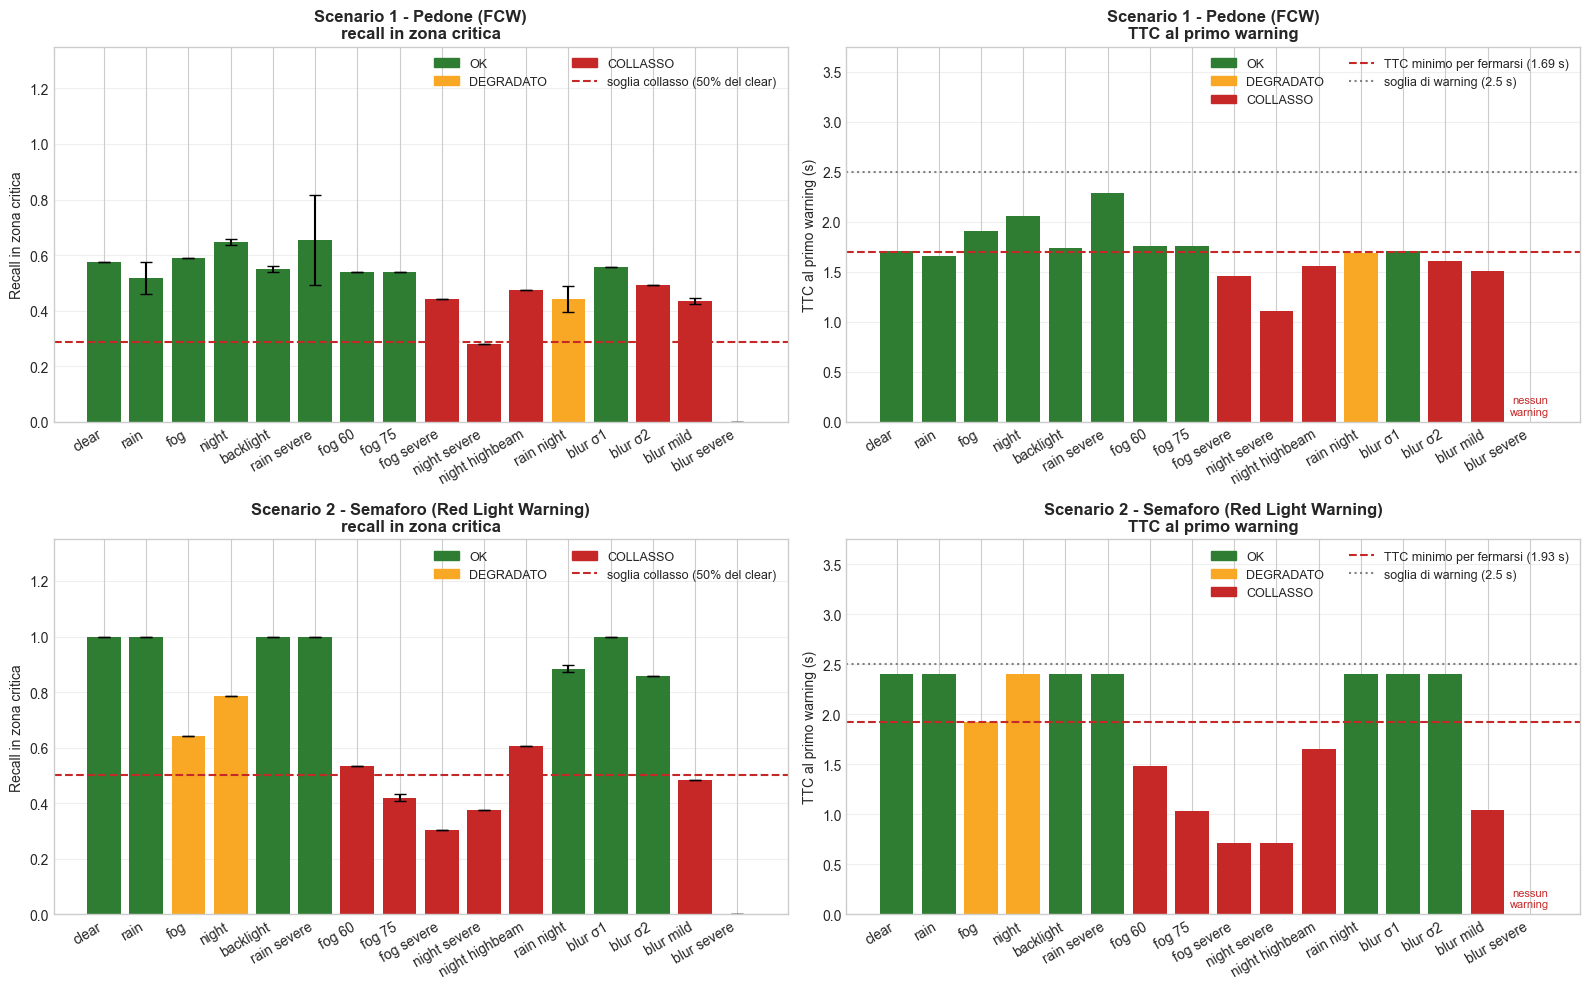

In [20]:
# QUANDO COLLASSA: recall in zona critica e TTC al warning per condizione
def warning_limits(config):
    """(soglia TTC di warning, TTC minimo per fermarsi) dalla configurazione del batch."""
    w, m = config['warning'], config['motion']
    speed = m['ego_speed_kmh'] / 3.6
    return w['ttc_warning_s'], w['reaction_s'] + speed / (2.0 * w['decel_mps2'])


def verdict_legend(ax, extra=()):
    handles = [mpatches.Patch(color=c, label=v) for v, c in VERDICT_COLORS.items()]
    ax.legend(handles=handles + list(extra), fontsize=9, loc='upper right', ncol=2)


if RESULTS:
    fig, axes = plt.subplots(len(RESULTS), 2, figsize=(16, 5 * len(RESULTS)), squeeze=False)
    for (key, res), (ax_rec, ax_ttc) in zip(RESULTS.items(), axes):
        agg, cfg = res['agg'], SCENARIOS[key]
        x = np.arange(len(agg))
        colors = [VERDICT_COLORS[v] for v in agg['esito']]
        ttc_warn, ttc_stop = warning_limits(res['config'])

        # Recall in zona critica
        yerr = agg['critical_recall_std'] if agg['n_run'].max() > 1 else None
        ax_rec.bar(x, agg['critical_recall'], color=colors, yerr=yerr, capsize=4)
        extra = []
        if 'clear' in agg.index:
            thr = COLLAPSE_RECALL_FRAC * agg.loc['clear', 'critical_recall']
            extra.append(ax_rec.axhline(thr, color='#c62828', ls='--', lw=1.5,
                                        label=f'soglia collasso ({COLLAPSE_RECALL_FRAC:.0%} del clear)'))
        ax_rec.set_ylim(0, 1.35)  # spazio in alto per la legenda
        ax_rec.set_ylabel('Recall in zona critica')
        ax_rec.set_title(f"{cfg['name']}\nrecall in zona critica", fontweight='bold')
        verdict_legend(ax_rec, extra)

        # TTC al primo warning (0 = nessun warning)
        ttc = agg['ttc_at_warning_s']
        ax_ttc.bar(x, ttc.fillna(0), color=colors)
        for xi, v in zip(x, ttc):
            if pd.isna(v):
                ax_ttc.text(xi, 0.05, 'nessun\nwarning', ha='center', va='bottom', fontsize=8, color='#c62828')
        lines = [ax_ttc.axhline(ttc_stop, color='#c62828', ls='--', lw=1.5,
                                label=f'TTC minimo per fermarsi ({ttc_stop:.2f} s)'),
                 ax_ttc.axhline(ttc_warn, color='gray', ls=':', lw=1.5,
                                label=f'soglia di warning ({ttc_warn:.1f} s)')]
        ax_ttc.set_ylim(0, ttc_warn * 1.5)  # spazio in alto per la legenda
        ax_ttc.set_ylabel('TTC al primo warning (s)')
        ax_ttc.set_title(f"{cfg['name']}\nTTC al primo warning", fontweight='bold')
        verdict_legend(ax_ttc, lines)

        for ax in (ax_rec, ax_ttc):
            ax.set_xticks(x)
            ax.set_xticklabels(agg.index, rotation=30, ha='right')
            ax.grid(axis='y', alpha=0.3)

    plt.tight_layout()
    for plots_dir in {r['plots_dir'] for r in RESULTS.values()}:
        plt.savefig(os.path.join(plots_dir, 'collapse_overview.png'), dpi=150, bbox_inches='tight')
    plt.show()


### 12.3 Recall in funzione della distanza

Per ogni condizione, la frazione di frame (con target visibile) in cui il target viene rilevato, a intervalli di 5 m. Mostra **da quale distanza** il sistema inizia a vedere il target: una curva spostata verso destra significa rilevamento più precoce. L'asse X è invertito (il veicolo si avvicina da sinistra verso destra) e l'area rossa è la zona critica.


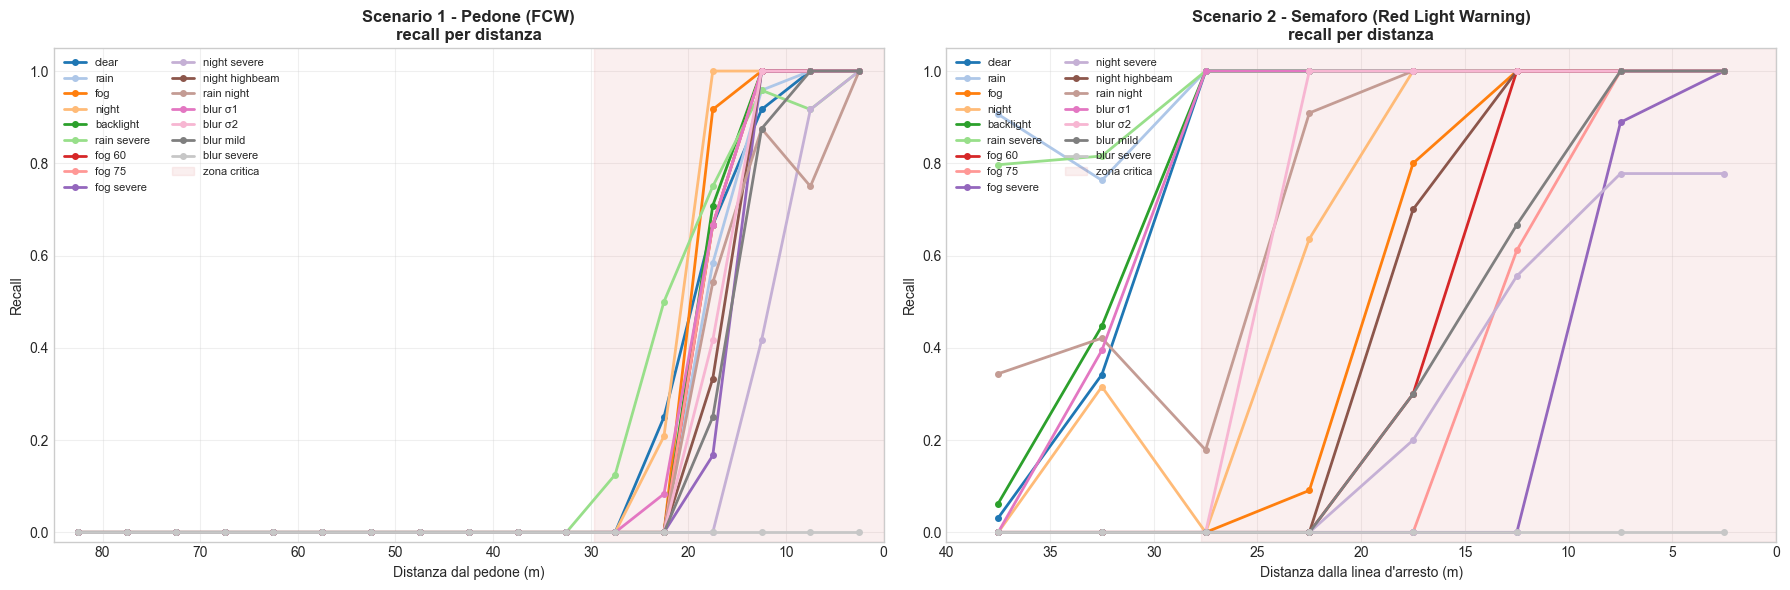

In [21]:
# RECALL IN FUNZIONE DELLA DISTANZA (bin da 5 m)
if RESULTS:
    fig, axes = plt.subplots(1, len(RESULTS), figsize=(9 * len(RESULTS), 6), squeeze=False)
    for (key, res), ax in zip(RESULTS.items(), axes[0]):
        frames = res['frames']
        if frames.empty:
            continue
        vis = frames[frames['gt_visible'] == 1].copy()
        max_d = float(np.ceil(vis['distance_m'].max() / 5.0) * 5.0)
        crit_m = vis.loc[vis['in_critical_zone'] == 1, 'distance_m'].max()  # limite della zona critica
        vis['bin'] = pd.cut(vis['distance_m'], bins=np.arange(0, max_d + 5, 5), right=False)
        cmap = plt.get_cmap('tab20')
        for i, cond in enumerate(res['agg'].index):
            curve = vis[vis['condition'] == cond].groupby('bin', observed=True)['tp'].mean()
            ax.plot([b.mid for b in curve.index], curve.values, marker='o', ms=4, lw=2,
                    color=cmap(i % 20), label=cond)
        if not pd.isna(crit_m):
            ax.axvspan(0, crit_m, color='#c62828', alpha=0.07, label='zona critica')
        ax.set_xlim(max_d, 0)
        ax.set_ylim(-0.02, 1.05)
        ax.set_xlabel("Distanza dalla linea d'arresto (m)" if key == 'tl' else 'Distanza dal pedone (m)')
        ax.set_ylabel('Recall')
        ax.set_title(f"{SCENARIOS[key]['name']}\nrecall per distanza", fontweight='bold')
        ax.grid(alpha=0.3)
        ax.legend(fontsize=8, loc='upper left', ncol=2)
    plt.tight_layout()
    for plots_dir in {r['plots_dir'] for r in RESULTS.values()}:
        plt.savefig(os.path.join(plots_dir, 'recall_vs_distance.png'), dpi=150, bbox_inches='tight')
    plt.show()


### 12.4 Corruzioni visive: blur, gocce sulla lente e abbagliamento

Andamento delle due metriche principali per ogni corruzione, per entrambi gli scenari: dal clear al blur con σ = 1, 2, 3 (mild) e 7 px (severe); da rain alle gocce sulla lente mild e severe; da backlight all'abbagliamento mild e severe. Il passaggio in cui la curva scende sotto la soglia di collasso (sempre rispetto al clear) indica la **soglia di fallimento** di quella corruzione. Nel grafico del TTC la linea tratteggiata di ogni scenario è il suo TTC minimo per fermarsi (30 km/h per il pedone, 40 km/h per il semaforo).


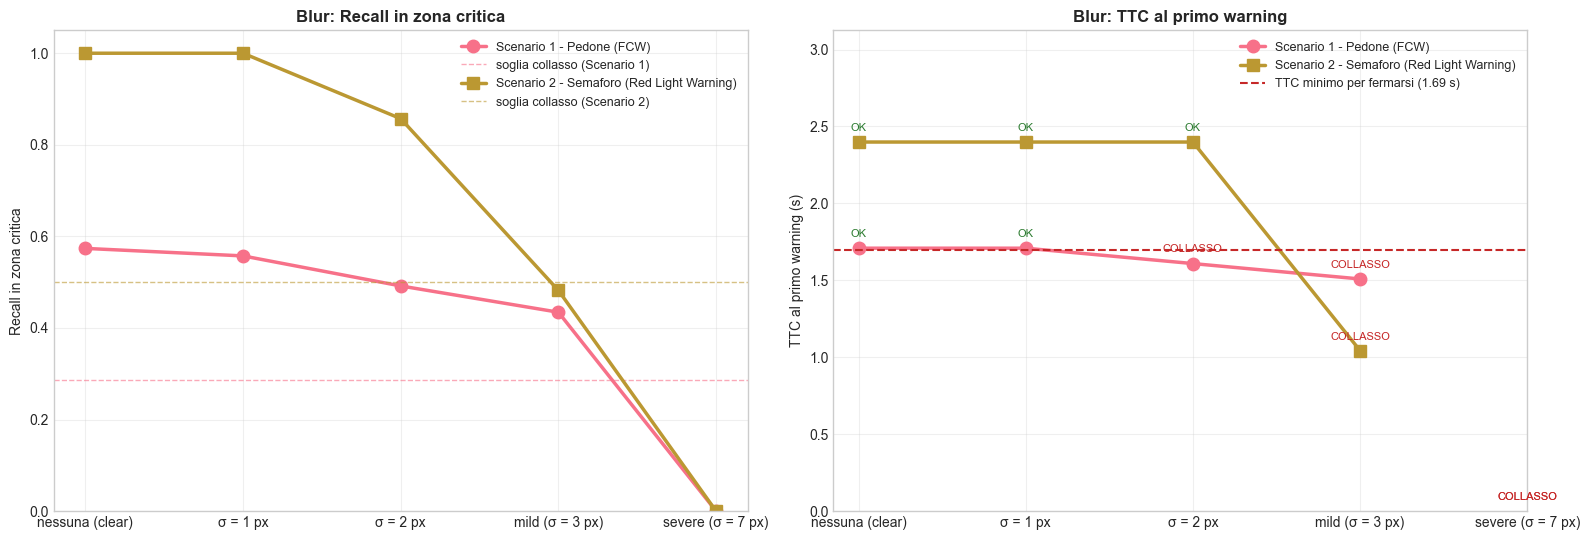

In [22]:
# CORRUZIONI: blur (clear -> sigma 1, 2, 3 mild, 7 severe), gocce sulla lente (rain -> mild -> severe),
# abbagliamento (backlight -> mild -> severe)
CORRUPTION_LADDERS = {
    'Blur': (['clear', 'blur σ1', 'blur σ2', 'blur mild', 'blur severe'],
             ['nessuna (clear)', 'σ = 1 px', 'σ = 2 px', 'mild (σ = 3 px)', 'severe (σ = 7 px)']),
    'Gocce sulla lente': (['rain', 'rain + lens drops mild', 'rain + lens drops severe'],
                          ['nessuna (rain)', 'mild', 'severe']),
    'Abbagliamento': (['backlight', 'backlight + glare mild', 'backlight + glare severe'],
                      ['nessuno (backlight)', 'mild', 'severe']),
}

ladders = {}
for title, (steps, ticks) in CORRUPTION_LADDERS.items():
    found = {k: r for k, r in RESULTS.items() if all(s in r['agg'].index for s in steps)}
    if found:
        ladders[title] = (steps, ticks, found)
if ladders:
    fig, axes = plt.subplots(len(ladders), 2, figsize=(16, 5.5 * len(ladders)), squeeze=False)
    markers = {'ped': 'o', 'tl': 's'}
    for (title, (steps, ticks, found)), (ax_rec, ax_ttc) in zip(ladders.items(), axes):
        x = np.arange(len(steps))
        for key, res in found.items():
            rows = res['agg'].loc[steps]
            name = SCENARIOS[key]['name']
            short = name.split(' - ')[0]
            line, = ax_rec.plot(x, rows['critical_recall'], marker=markers[key], ms=9, lw=2.5, label=name)
            if 'clear' in res['agg'].index:   # soglia di collasso: sempre rispetto al clear
                ax_rec.axhline(COLLAPSE_RECALL_FRAC * res['agg'].loc['clear', 'critical_recall'], ls='--', lw=1,
                               alpha=0.6, color=line.get_color(), label=f'soglia collasso ({short})')
            ax_ttc.plot(x, rows['ttc_at_warning_s'], marker=markers[key], ms=9, lw=2.5, label=name,
                        color=line.get_color())
            ttc_warn, ttc_stop = warning_limits(res['config'])   # dipende dalla velocita' dello scenario
            ax_ttc.axhline(ttc_stop, color=line.get_color(), ls='--', lw=1.2, alpha=0.8,
                           label=f'TTC minimo per fermarsi ({short}, {ttc_stop:.2f} s)')
            for xi, (v, esito) in enumerate(zip(rows['ttc_at_warning_s'], rows['esito'])):
                ax_ttc.annotate(esito, (xi, 0 if pd.isna(v) else v), textcoords='offset points', xytext=(0, 8),
                                ha='center', fontsize=8, color=VERDICT_COLORS[esito])
        ax_rec.set_ylabel('Recall in zona critica')
        ax_rec.set_ylim(0, 1.05)
        ax_ttc.set_ylabel('TTC al primo warning (s)')
        ax_ttc.set_ylim(0, ttc_warn * 1.25)
        for ax, metric in ((ax_rec, 'recall in zona critica'), (ax_ttc, 'TTC al primo warning')):
            ax.set_xticks(x)
            ax.set_xticklabels(ticks)
            ax.set_title(f'{title}: {metric}', fontweight='bold')
            ax.grid(alpha=0.3)
            ax.legend(fontsize=9)
    plt.tight_layout()
    for plots_dir in {r['plots_dir'] for _, _, found in ladders.values() for r in found.values()}:
        plt.savefig(os.path.join(plots_dir, 'corruption_degradation.png'), dpi=150, bbox_inches='tight')
    plt.show()
else:
    print("Nessuna serie di corruzioni completa nei risultati")


## 13. Confronto Visuale Side-by-Side

Lo **stesso frame**, alla stessa distanza dal target, in tutte le condizioni: circa 20 m per il pedone, circa 42 m per il semaforo. Le traiettorie sono identiche in ogni run, quindi l'unica differenza tra le immagini è la condizione ambientale o la corruzione.

- **Riga superiore**: frame intero con le detection di YOLO (sopra soglia) e il box di ground truth in verde.
- **Riga inferiore**: ingrandimento attorno al target.

Il titolo riporta l'esito della condizione (Sezione 12.1). Risponde al requisito: *"Include at least one clean side-by-side comparison for rain, fog, night, and blur"*.


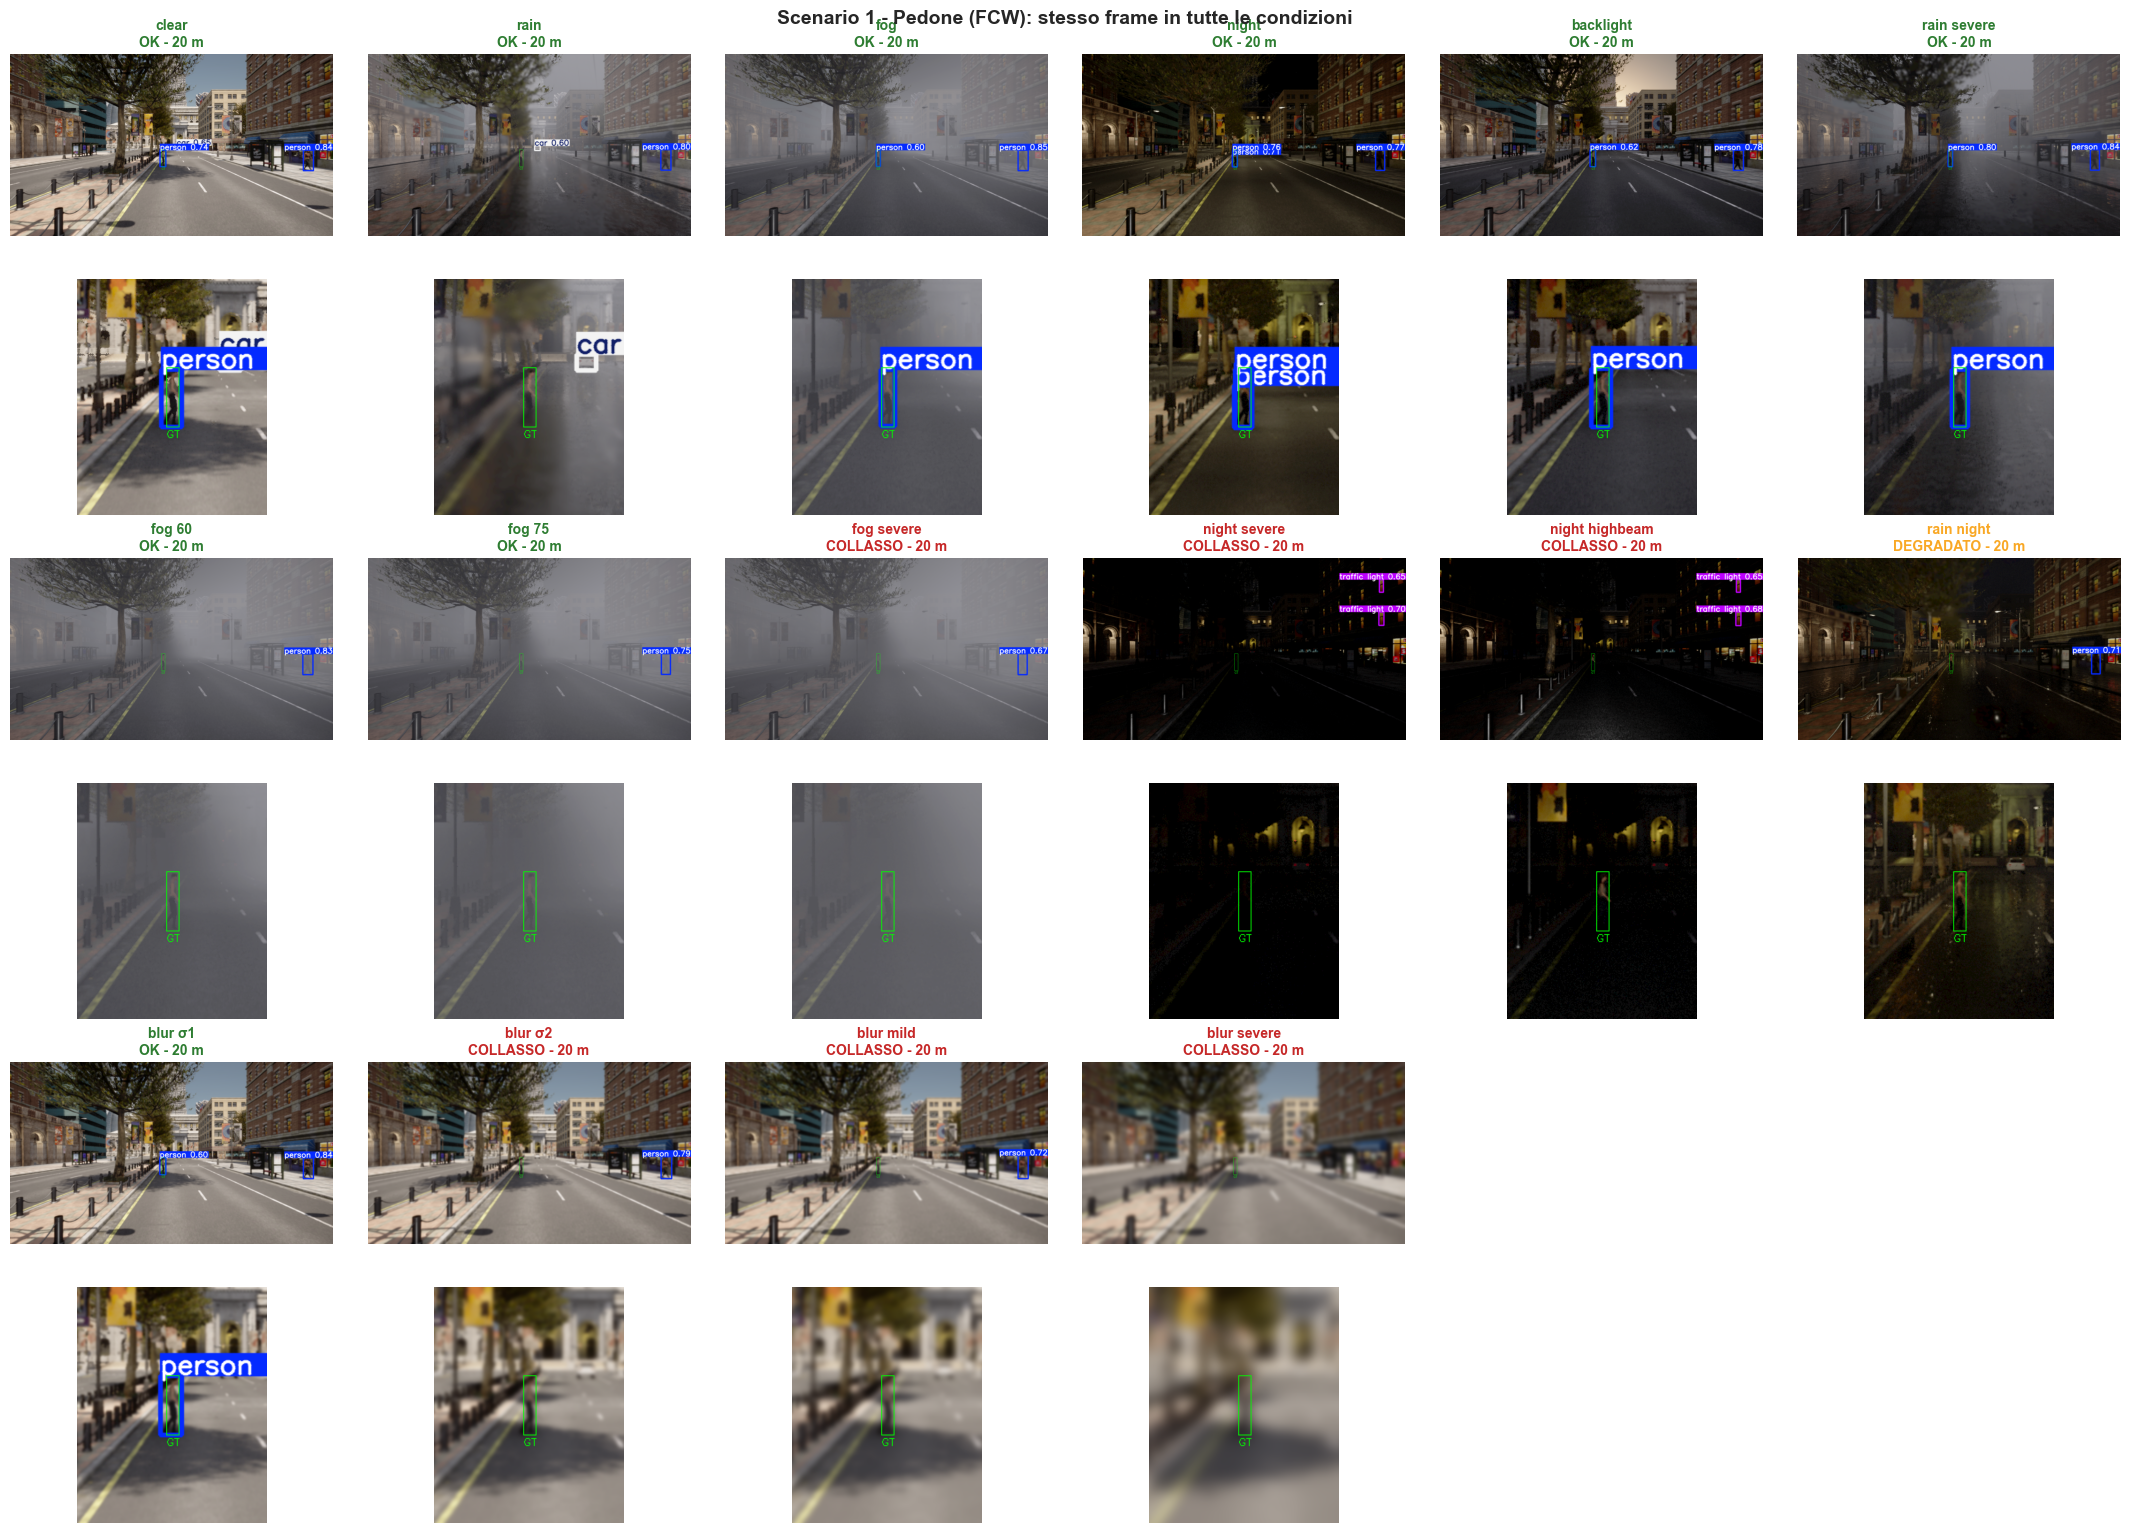

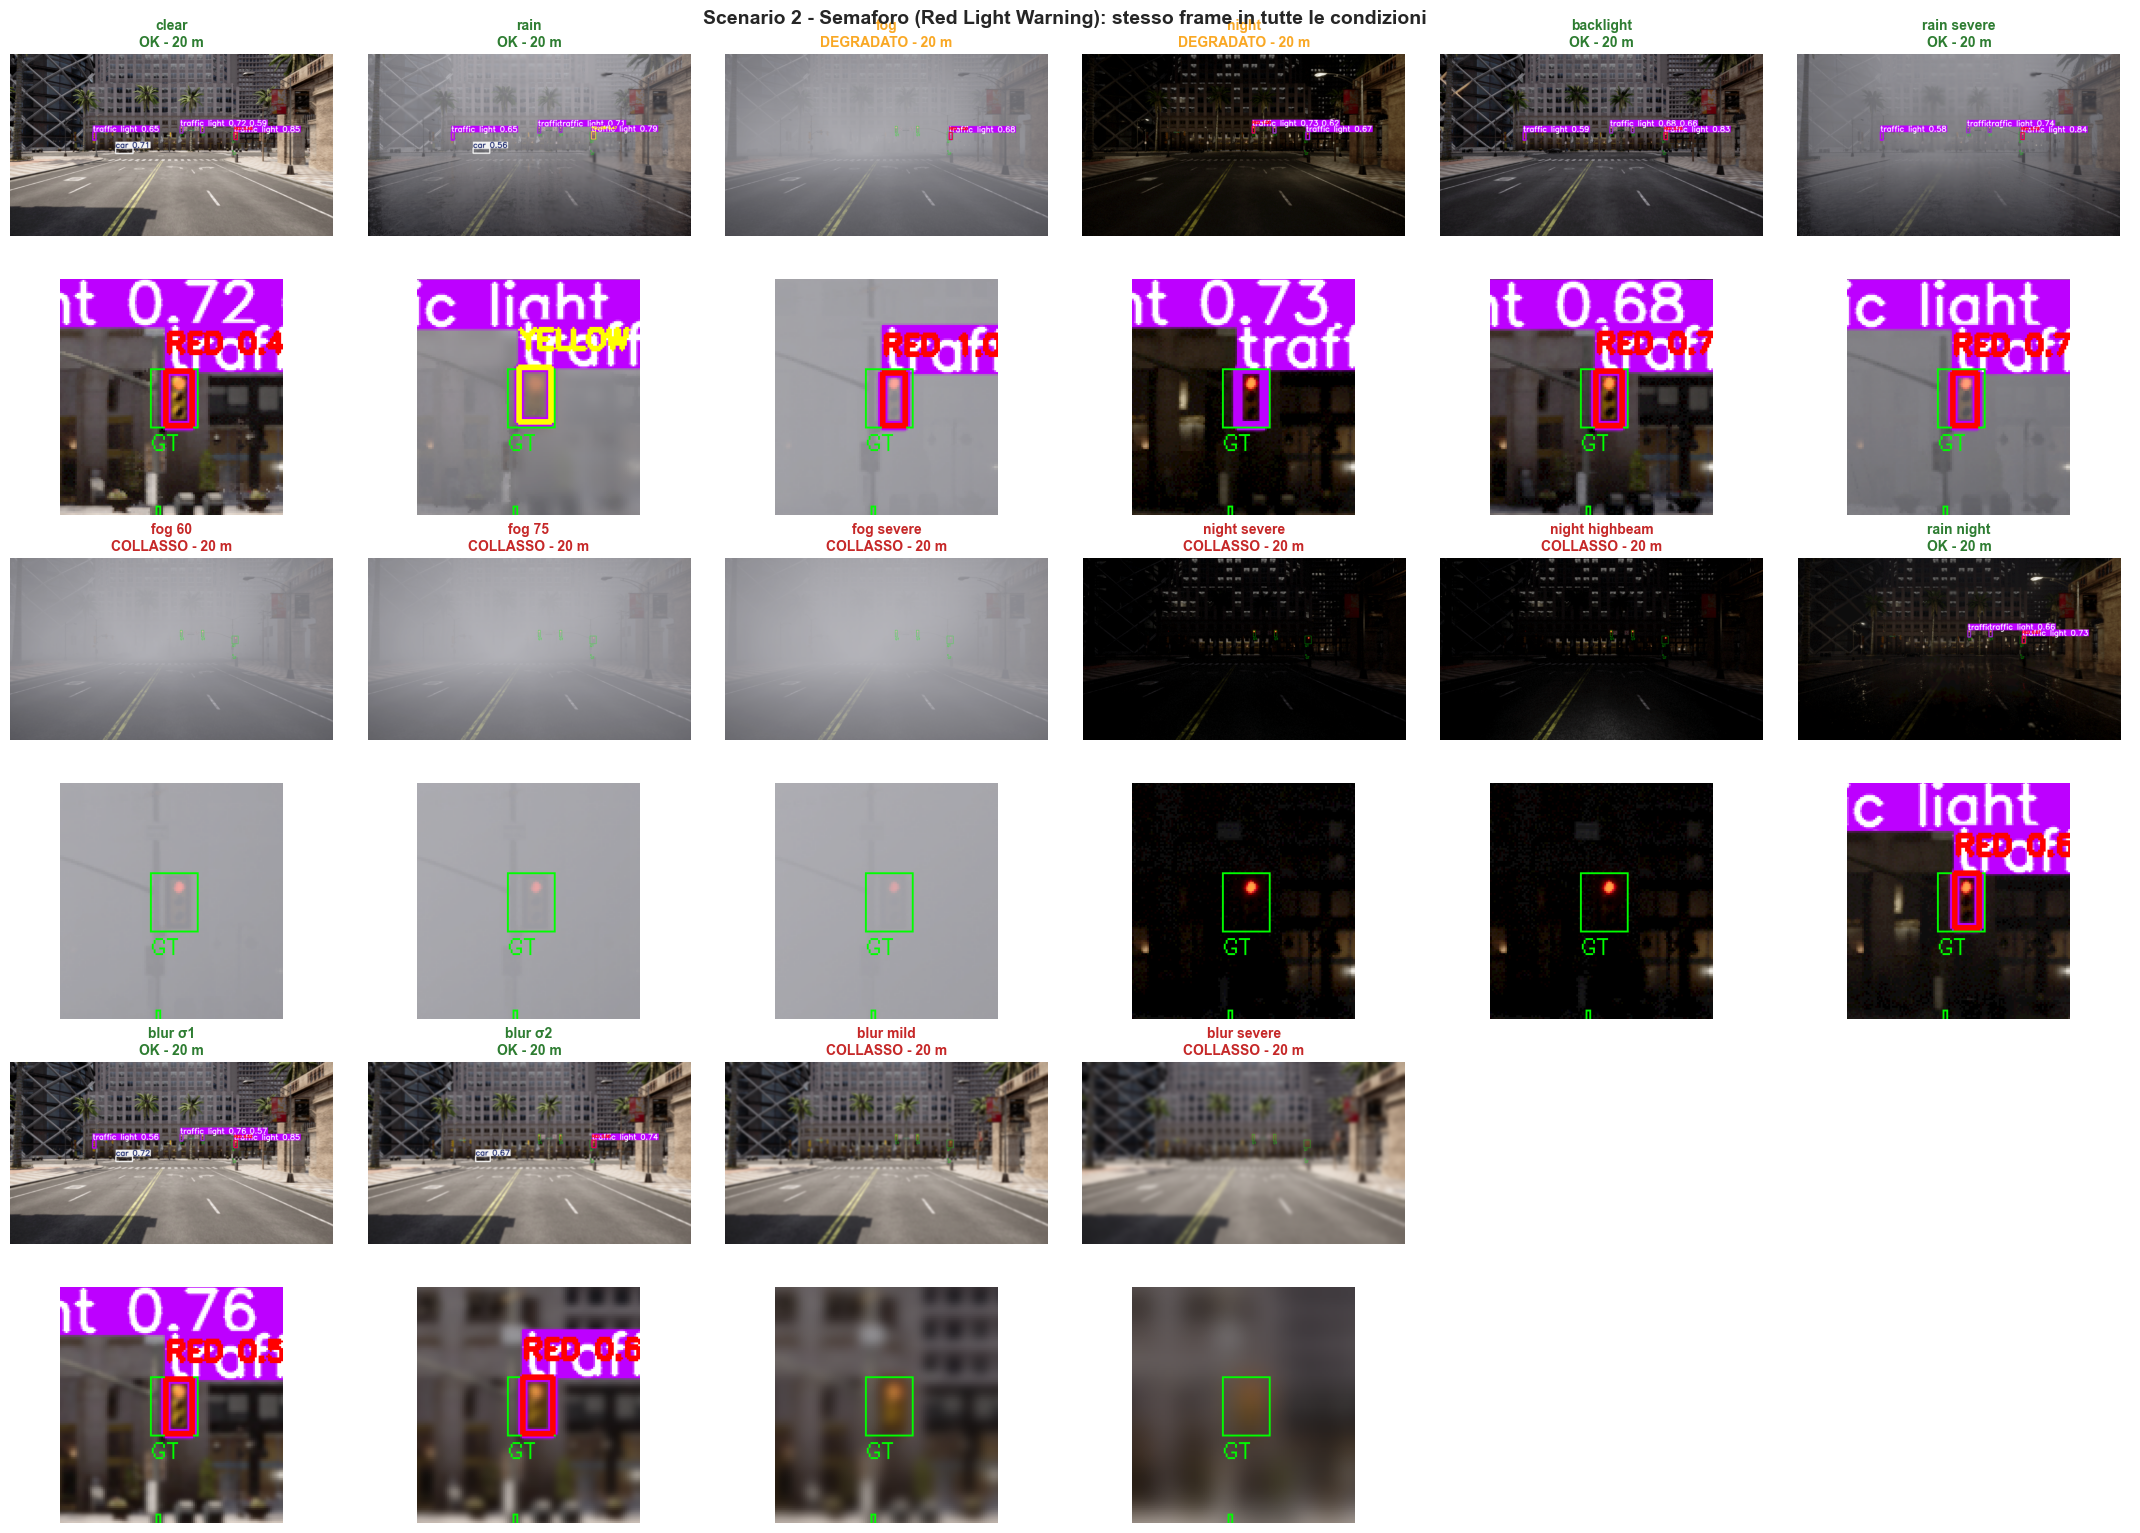

In [23]:
# SIDE-BY-SIDE: stesso frame (stessa distanza) in tutte le condizioni, dall'ultimo batch
import re


def sample_with_gt(res, run_label, prefix):
    """(immagine annotata, ingrandimento sul GT, distanza) del sample che inizia con prefix, o None."""
    run_dir = os.path.join(res['latest'], SCENARIOS[res['key']]['samples'], run_label)
    if not os.path.isdir(run_dir):
        return None
    for fname in sorted(os.listdir(run_dir)):
        m = re.match(re.escape(prefix) + r'.*?_(\d+\.\d)m', fname)
        if not m:
            continue
        image = np.array(Image.open(os.path.join(run_dir, fname)).convert('RGB'))
        frames = res['frames']
        vis = frames[(frames['batch_dir'] == res['latest']) & (frames['run_label'] == run_label)
                     & (frames['gt_visible'] == 1)]
        zoom = None
        if len(vis):
            row = vis.iloc[(vis['distance_m'] - float(m.group(1))).abs().argmin()]
            zoom = gt_zoom(image, row)
        return image, zoom, float(m.group(1))
    return None


def panel_axes(n, col_w, row_h, max_cols=6):
    """Figura con n pannelli (immagine sopra, ingrandimento sotto), al massimo max_cols per riga."""
    ncols = min(n, max_cols)
    blocks = -(-n // ncols)
    fig, axes = plt.subplots(2 * blocks, ncols, figsize=(col_w * ncols, row_h * blocks), squeeze=False,
                             gridspec_kw={'height_ratios': [1, 1.3] * blocks})
    for ax in axes.flat:
        ax.axis('off')
    return fig, [(axes[2 * (i // ncols), i % ncols], axes[2 * (i // ncols) + 1, i % ncols]) for i in range(n)]


for key, res in RESULTS.items():
    res['key'] = key
    latest = res['summary'][res['summary']['batch_dir'] == res['latest']]
    labels = dict(zip(latest['condition'], latest['run_label']))
    panels = []
    for cond in res['agg'].index:
        if cond in labels:
            found = sample_with_gt(res, labels[cond], SCENARIOS[key]['side_sample'])
            if found:
                panels.append((cond, res['agg'].loc[cond, 'esito']) + found)
    if not panels:
        print(f"{SCENARIOS[key]['name']}: nessun sample trovato in {res['latest']}")
        continue
    fig, pairs = panel_axes(len(panels), 3.6, 5.2)
    for (ax_img, ax_zoom), (cond, esito, image, zoom, dist) in zip(pairs, panels):
        ax_img.imshow(image)
        ax_img.set_title(f"{cond}\n{esito} - {dist:.0f} m", fontsize=10, fontweight='bold',
                         color=VERDICT_COLORS[esito])
        if zoom is not None:
            ax_zoom.imshow(zoom)
    plt.suptitle(f"{SCENARIOS[key]['name']}: stesso frame in tutte le condizioni", fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.savefig(os.path.join(res['plots_dir'], f'side_by_side_{key}.png'), dpi=150, bbox_inches='tight')
    plt.show()


## 14. Failure Cases

Un **failure case** è un frame in cui il target viene rilevato in clear ma **non** nella condizione considerata. Grazie alle traiettorie identiche, lo stesso indice di frame corrisponde alla stessa posizione del veicolo in tutte le condizioni, quindi il confronto è diretto.

- **Tabella**: per ogni condizione, quanti frame rilevati in clear vengono persi, a quali distanze, e il primo frame perso in zona critica.
- **Immagini**: per le condizioni DEGRADATO o COLLASSO, il primo frame in zona critica in cui il target non viene rilevato (sample `miss_crit_*`), con l'ingrandimento sul box di ground truth.


  FAILURE CASES - Scenario 1 - Pedone (FCW)
    Condizione     Esito Frame persi rispetto al clear Distanze dei frame persi (m)  Persi in zona critica Primo perso in zona critica (m)
          rain        OK                        8 / 35                  10.4 - 22.1                      8                            22.1
           fog        OK                        3 / 35                  20.0 - 22.1                      3                            22.1
         night        OK                        2 / 35                  21.7 - 22.1                      2                            22.1
     backlight        OK                        3 / 35                  20.0 - 22.1                      3                            22.1
   rain severe        OK                        0 / 35                            -                      0                               -
        fog 60        OK                        4 / 35                  19.6 - 22.1                      4                

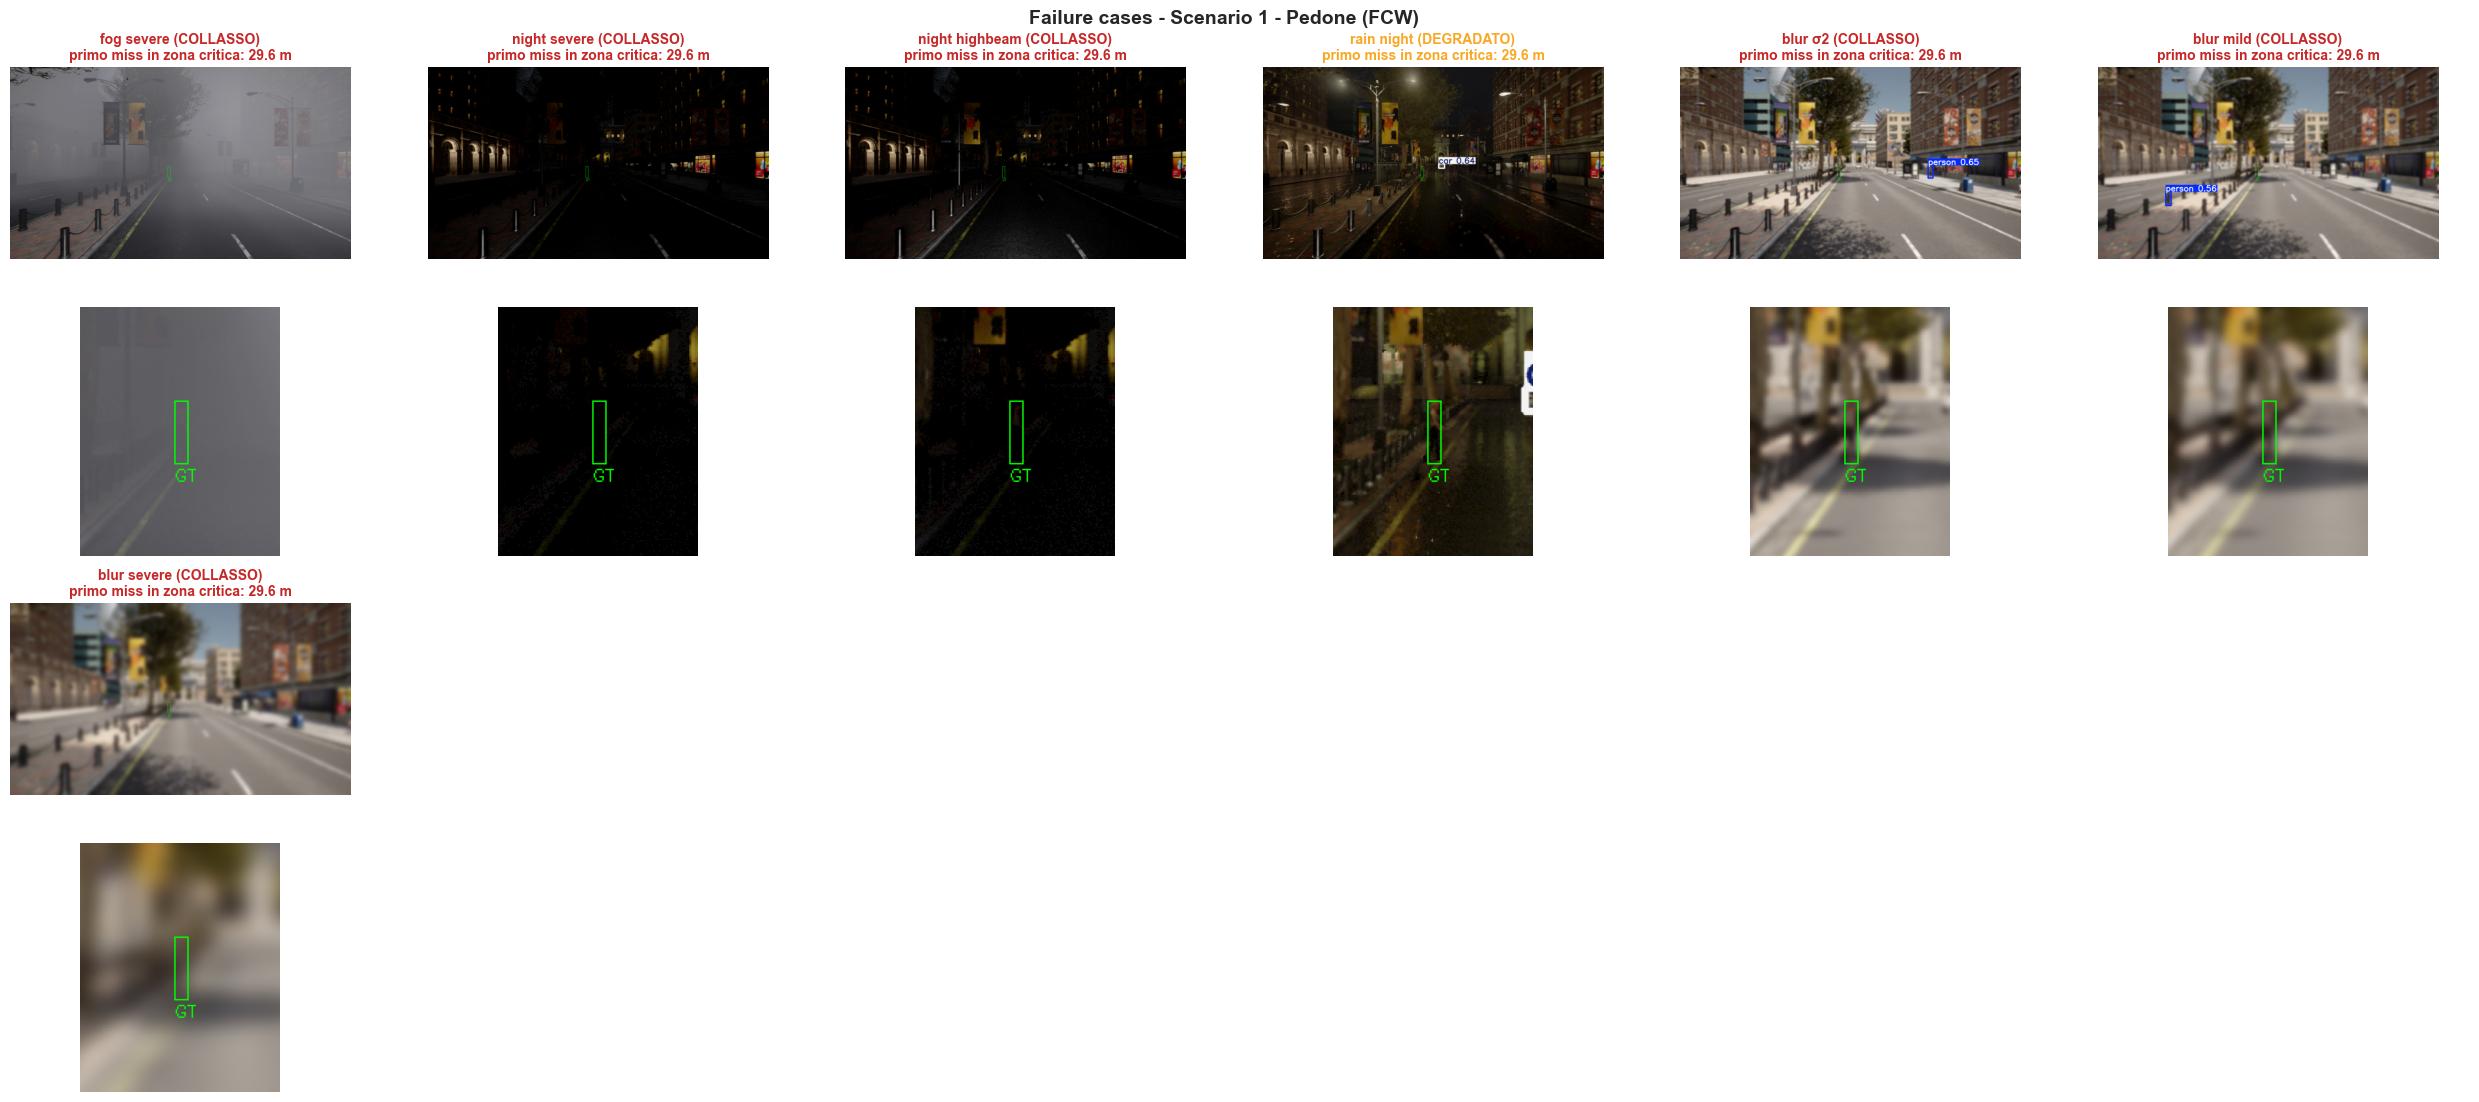

  FAILURE CASES - Scenario 2 - Semaforo (Red Light Warning)
    Condizione     Esito Frame persi rispetto al clear Distanze dei frame persi (m)  Persi in zona critica Primo perso in zona critica (m)
          rain        OK                        1 / 69                  30.7 - 30.7                      0                               -
           fog DEGRADATO                       33 / 69                  16.1 - 33.3                     20                            27.7
         night DEGRADATO                       20 / 69                  23.3 - 33.3                     12                            27.7
     backlight        OK                        1 / 69                  30.7 - 30.7                      0                               -
   rain severe        OK                        1 / 69                  30.7 - 30.7                      0                               -
        fog 60  COLLASSO                       39 / 69                  15.0 - 33.3                     26

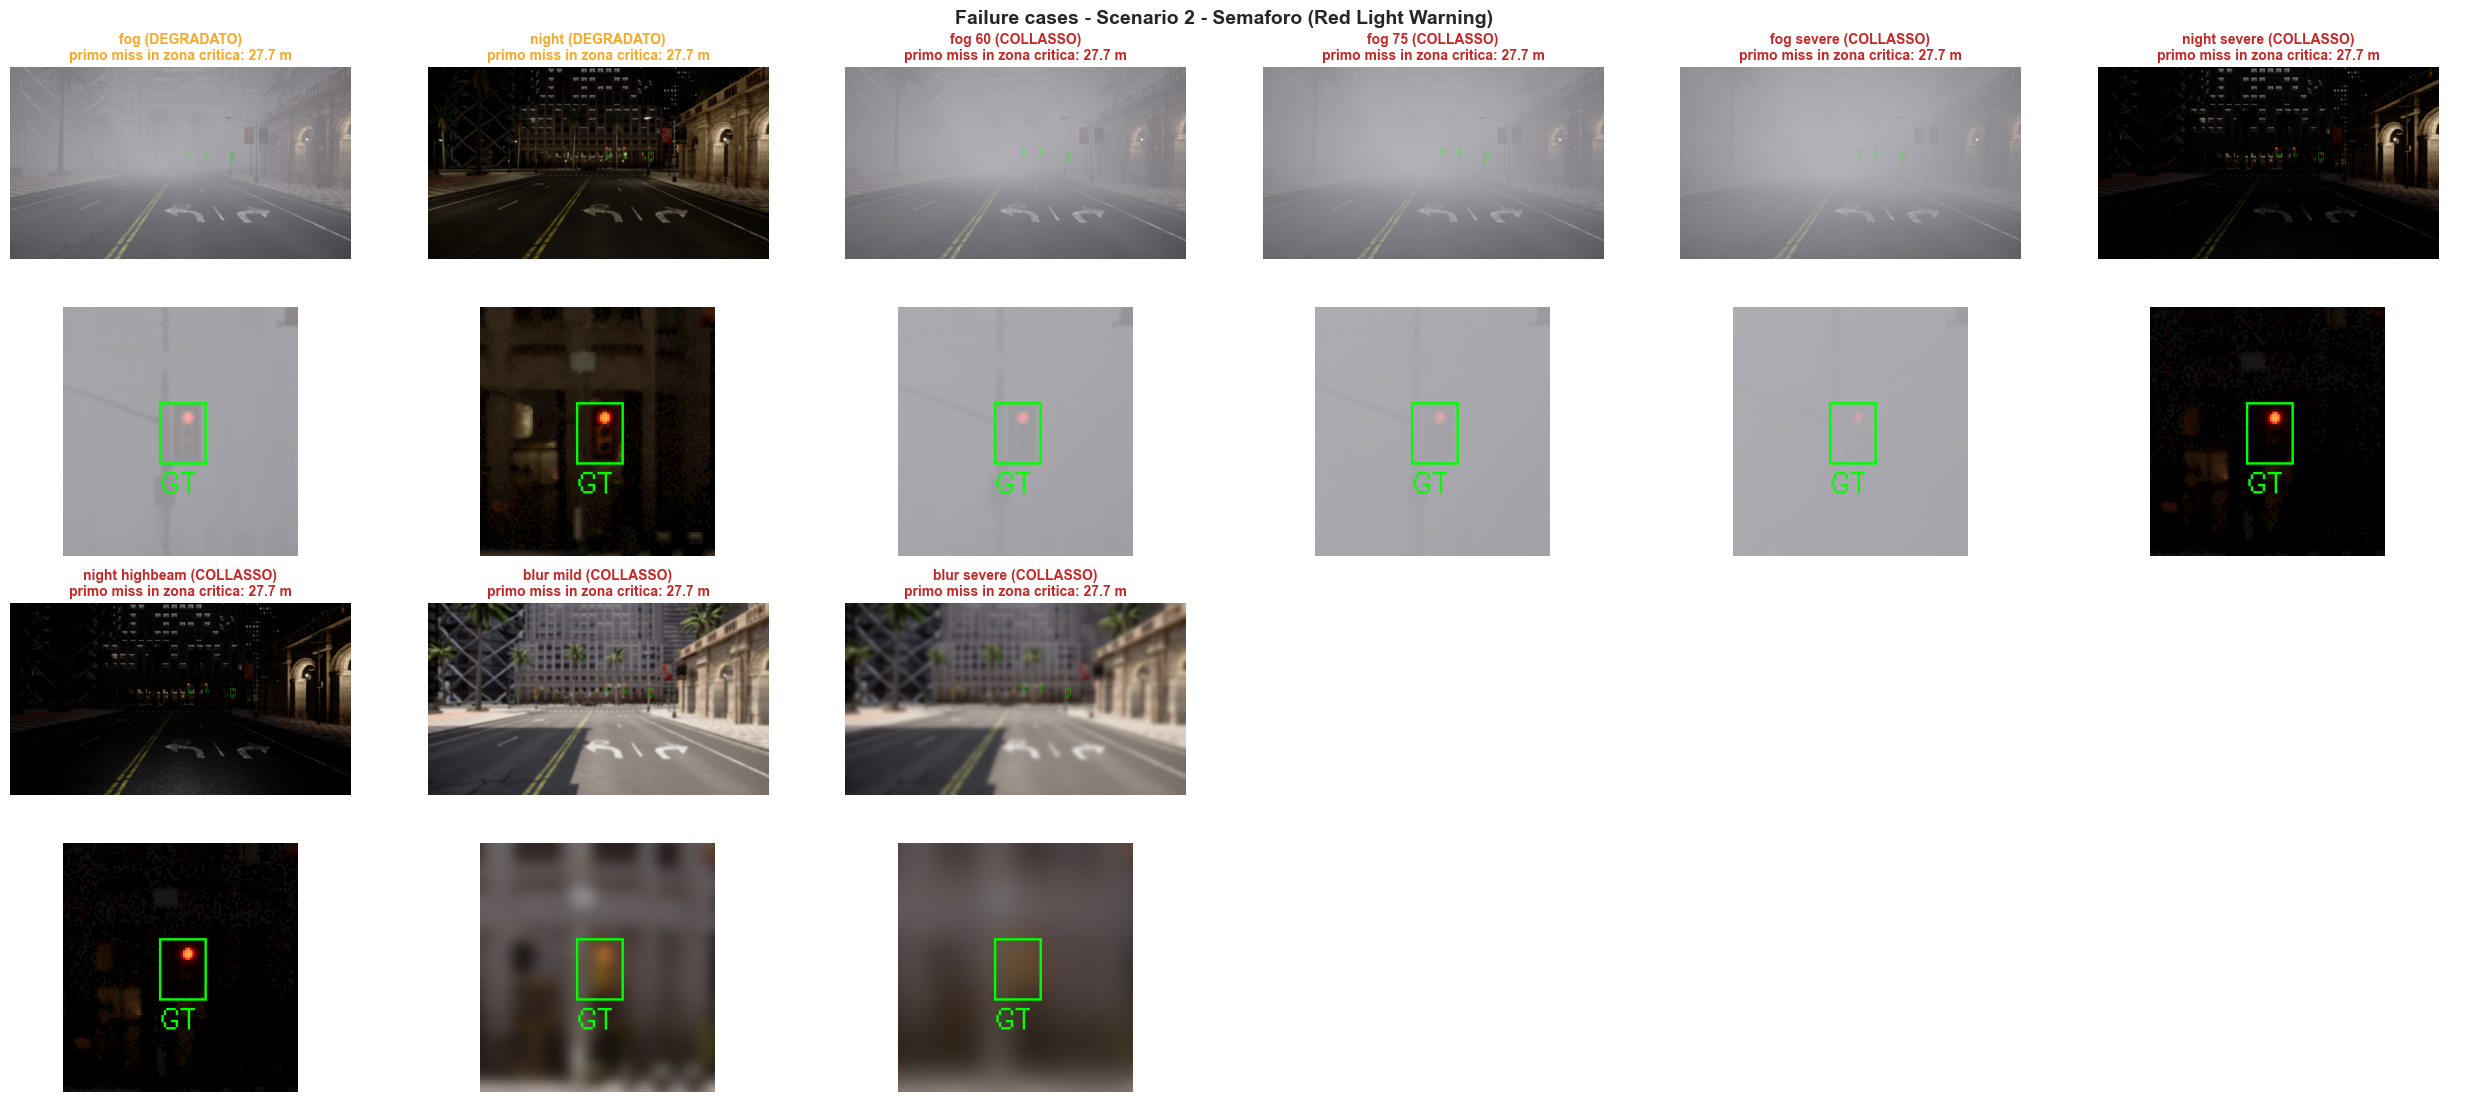

In [24]:
# FAILURE CASES: frame rilevati in clear ma persi nella condizione (ultimo batch)
for key, res in RESULTS.items():
    frames = res['frames']
    latest = frames[frames['batch_dir'] == res['latest']]
    clear = latest[latest['condition'] == 'clear'].set_index('frame_index')
    if clear.empty:
        print(f"{SCENARIOS[key]['name']}: condizione clear assente, confronto non possibile")
        continue
    rows = []
    for cond in res['agg'].index:
        if cond == 'clear':
            continue
        other = latest[latest['condition'] == cond].set_index('frame_index')
        both = clear[['tp', 'distance_m']].join(other[['tp', 'gt_visible', 'in_critical_zone']],
                                                 rsuffix='_cond', how='inner')
        lost = both[(both['tp'] == 1) & (both['tp_cond'] == 0) & (both['gt_visible'] == 1)]
        lost_crit = lost[lost['in_critical_zone'] == 1]
        rows.append({
            'Condizione': cond,
            'Esito': res['agg'].loc[cond, 'esito'],
            'Frame persi rispetto al clear': f"{len(lost)} / {int(both['tp'].sum())}",
            'Distanze dei frame persi (m)': (f"{lost['distance_m'].min():.1f} - {lost['distance_m'].max():.1f}"
                                            if len(lost) else '-'),
            'Persi in zona critica': len(lost_crit),
            'Primo perso in zona critica (m)': f"{lost_crit['distance_m'].max():.1f}" if len(lost_crit) else '-',
        })
    print('=' * 100)
    print(f"  FAILURE CASES - {SCENARIOS[key]['name']}")
    print('=' * 100)
    print(pd.DataFrame(rows).to_string(index=False))
    print()

    # Immagini: primo miss in zona critica per le condizioni non OK
    res['key'] = key
    summary_latest = res['summary'][res['summary']['batch_dir'] == res['latest']]
    labels = dict(zip(summary_latest['condition'], summary_latest['run_label']))
    failing = [c for c in res['agg'].index if res['agg'].loc[c, 'esito'] != 'OK' and c in labels]
    panels = []
    for cond in failing:
        found = sample_with_gt(res, labels[cond], 'miss_crit')
        if found:
            panels.append((cond, found))
    if panels:
        fig, pairs = panel_axes(len(panels), 4.2, 5.6)
        for (ax_img, ax_zoom), (cond, (image, zoom, dist)) in zip(pairs, panels):
            esito = res['agg'].loc[cond, 'esito']
            ax_img.imshow(image)
            ax_img.set_title(f"{cond} ({esito})\nprimo miss in zona critica: {dist:.1f} m", fontsize=10,
                             fontweight='bold', color=VERDICT_COLORS[esito])
            if zoom is not None:
                ax_zoom.imshow(zoom)
        plt.suptitle(f"Failure cases - {SCENARIOS[key]['name']}", fontsize=14, fontweight='bold')
        plt.tight_layout()
        plt.savefig(os.path.join(res['plots_dir'], f'failure_cases_{key}.png'), dpi=150, bbox_inches='tight')
        plt.show()


## 15. Sintesi Automatica dei Risultati

Riepilogo generato dai dati: per ogni scenario, le condizioni raggruppate per esito, la condizione peggiore e la soglia di fallimento di ogni corruzione (blur, gocce sulla lente, abbagliamento). Il testo stampato è la base per le conclusioni (Sezione 16) e per il report.


In [25]:
# SINTESI AUTOMATICA
for key, res in RESULTS.items():
    agg = res['agg']
    print('=' * 80)
    print(f"  {SCENARIOS[key]['name']}")
    print('=' * 80)
    for esito in ('COLLASSO', 'DEGRADATO', 'OK'):
        rows = agg[agg['esito'] == esito]
        if len(rows):
            items = [f"{c} ({m})" if m else c for c, m in zip(rows.index, rows['motivo'])]
            print(f"  {esito:10s}: {', '.join(items)}")

    others = agg.drop(index='clear', errors='ignore')
    if len(others) and others['critical_recall'].notna().any():
        worst = others['critical_recall'].idxmin()
        print(f"  Condizione peggiore (recall in zona critica): {worst} "
              f"= {agg.loc[worst, 'critical_recall']:.0%}"
              + (f" contro {agg.loc['clear', 'critical_recall']:.0%} in clear" if 'clear' in agg.index else ''))

    for title, (steps, _) in CORRUPTION_LADDERS.items():
        if not all(s in agg.index for s in steps):
            continue
        esiti = agg.loc[steps, 'esito'].tolist()
        first_bad = next((s for s, e in zip(steps, esiti) if e == 'COLLASSO'), None)
        if first_bad:
            print(f"  {title}: il sistema collassa a partire da '{first_bad}' "
                  f"(esiti: {', '.join(f'{s}={e}' for s, e in zip(steps, esiti))})")
        else:
            print(f"  {title}: nessun collasso fino a '{steps[-1]}' (esiti: {', '.join(esiti)})")
    print()


  Scenario 1 - Pedone (FCW)
  COLLASSO  : fog severe (warning troppo tardi per fermarsi), night severe (warning troppo tardi per fermarsi), night highbeam (warning troppo tardi per fermarsi), blur σ2 (warning troppo tardi per fermarsi), blur mild (warning troppo tardi per fermarsi), blur severe (nessun warning)
  DEGRADATO : rain night (recall zona critica al 77% del clear)
  OK        : clear, rain, fog, night, backlight, rain severe, fog 60, fog 75, blur σ1
  Condizione peggiore (recall in zona critica): blur severe = 0% contro 57% in clear
  Blur: il sistema collassa a partire da 'blur σ2' (esiti: clear=OK, blur σ1=OK, blur σ2=COLLASSO, blur mild=COLLASSO, blur severe=COLLASSO)

  Scenario 2 - Semaforo (Red Light Warning)
  COLLASSO  : fog 60 (warning troppo tardi per fermarsi), fog 75 (warning troppo tardi per fermarsi), fog severe (warning troppo tardi per fermarsi), night severe (warning troppo tardi per fermarsi), night highbeam (warning troppo tardi per fermarsi), blur mild (wa

## 16. Conclusioni

> **Da completare dopo l'esecuzione del benchmark** con la tabella degli esiti (Sezione 12.1) e la sintesi della Sezione 15. Metodologia completa, grafici e failure case sono nel report.
